# Performance of Linear Regression Model in Predicting Fuel Consumption for the Government Fleets
**Guimaras State University — College of Science and Technology**

This notebook reproduces the model-development workflow of the study (Chapter III) in Google Colab:

1. Collect and merge the historical fleet records with the supplementary dataset
2. Data cleaning and outlier removal
3. Variable selection (correlation heatmap and Variance Inflation Factor, VIF > 5 removed)
4. Train-test split (80/20) and Linear Regression training
5. Evaluation with R², MAE and RMSE, and k-fold cross-validation
6. Regression assumption checks (LINE conditions) with statsmodels
7. Saving the trained model with Joblib for the Flask web application

The code in this notebook is the same preprocessing and diagnostics code used by the web application
(`model/preprocess.py`, `model/diagnostics.py`, `model/train_model.py`).

In [1]:
# Colab already includes pandas, numpy, scikit-learn, matplotlib and seaborn.
!pip -q install statsmodels joblib


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json, os, warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
sns.set_theme(style="whitegrid")
RANDOM_STATE, CV_FOLDS = 42, 5

## 1. Data collection — the datasets (built into this notebook)
This version already contains the data exported from the web application (Model Performance → Training Details):
**historical_fleet_data.csv** (the fleet trip records) and **supplementary_data.csv** (2,000 real-world trips from the open
online dataset of Fan & Song, 2022, Mendeley Data, https://doi.org/10.17632/jzjxcdn6k4.2, CC BY 4.0).
The next cell writes both files, so **Runtime → Run all** trains the model with no file upload.


In [ ]:
# Data exported from the web application. For newer records, download both CSV files again from
# Model Performance and use fuel_consumption_linear_regression.ipynb (the upload version).
HISTORICAL_PATH, SUPPLEMENTARY_PATH = "historical_fleet_data.csv", "supplementary_data.csv"
HISTORICAL_CSV = 'vehicle_type,brand_model,engine_displacement,fuel_type,year_model,odometer_reading,distance_km,duration_minutes,avg_speed_kmh,trip_type,departure_time,departure_period,passenger_cargo_load_kg,route,road_type,terrain_classification,actual_fuel_consumption\nVan,Nissan Van,2.5,Diesel,2020.0,0.0,192.0,288.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,19.2\nVan,Nissan Van,2.5,Diesel,2020.0,192.0,128.0,192.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,12.8\nVan,Nissan Van,2.5,Diesel,2020.0,320.0,192.0,288.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,19.2\nVan,Nissan Van,2.5,Diesel,2020.0,512.0,208.0,312.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,20.8\nVan,Nissan Van,2.5,Diesel,2020.0,720.0,64.0,96.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,6.4\nVan,Nissan Van,2.5,Diesel,2020.0,784.0,100.0,150.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,10.0\nVan,Nissan Van,2.5,Diesel,2020.0,884.0,182.0,273.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,18.2\nVan,Nissan Van,2.5,Diesel,2020.0,1066.0,93.0,139.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,9.3\nVan,Nissan Van,2.5,Diesel,2020.0,1159.0,64.0,96.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,6.4\nVan,Nissan Van,2.5,Diesel,2020.0,1223.0,89.0,133.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,8.9\nVan,Nissan Van,2.5,Diesel,2020.0,1312.0,262.0,393.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,26.2\nVan,Nissan Van,2.5,Diesel,2020.0,1574.0,332.0,498.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,33.2\nVan,Nissan Van,2.5,Diesel,2020.0,1906.0,184.0,276.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,18.4\nVan,Nissan Van,2.5,Diesel,2020.0,2090.0,278.0,417.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,27.8\nVan,Nissan Van,2.5,Diesel,2020.0,2368.0,196.0,294.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,19.6\nVan,Nissan Van,2.5,Diesel,2020.0,2564.0,67.0,100.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,6.7\nVan,Nissan Van,2.5,Diesel,2020.0,2631.0,154.0,231.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,15.4\nVan,Nissan Van,2.5,Diesel,2020.0,2785.0,32.0,48.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,3.2\nVan,Nissan Van,2.5,Diesel,2020.0,2817.0,229.0,343.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,22.9\nVan,Nissan Van,2.5,Diesel,2020.0,3046.0,208.0,312.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,20.8\nVan,Nissan Van,2.5,Diesel,2020.0,3254.0,64.0,96.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,6.4\nVan,Nissan Van,2.5,Diesel,2020.0,3318.0,168.0,252.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,16.8\nVan,Nissan Van,2.5,Diesel,2020.0,3486.0,283.0,424.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,28.3\nVan,Nissan Van,2.5,Diesel,2020.0,3769.0,202.0,303.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,20.2\nVan,Nissan Van,2.5,Diesel,2020.0,3971.0,269.0,403.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,26.9\nVan,Nissan Van,2.5,Diesel,2020.0,4240.0,188.0,282.0,40.0,Official Business,08:00,Early Morning,0.0,RASUC/RCAF,Paved,Flat,18.8\nVan,Nissan Van,2.5,Diesel,2020.0,4428.0,262.0,393.0,40.0,Official Business,08:00,Early Morning,0.0,RASUC/RCAF,Paved,Flat,26.2\nVan,Nissan Van,2.5,Diesel,2020.0,4690.0,208.0,312.0,40.0,Official Business,08:00,Early Morning,0.0,RASUC/RCAF,Paved,Flat,20.8\nVan,Nissan Van,2.5,Diesel,2020.0,4898.0,215.0,322.5,40.0,Official Business,08:00,Early Morning,0.0,RASUC/RCAF,Paved,Flat,21.5\nVan,Nissan Van,2.5,Diesel,2020.0,5113.0,233.0,349.5,40.0,Official Business,08:00,Early Morning,0.0,RASUC/RCAF,Paved,Flat,23.3\nVan,Nissan Van,2.5,Diesel,2020.0,5346.0,220.0,330.0,40.0,Official Business,08:00,Early Morning,0.0,RASUC/RCAF,Paved,Flat,22.0\nVan,Nissan Van,2.5,Diesel,2020.0,5566.0,132.0,198.0,40.0,Official Business,08:00,Early Morning,0.0,RASUC/RCAF,Paved,Flat,13.2\nVan,Nissan Van,2.5,Diesel,2020.0,5698.0,256.0,384.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,25.6\nVan,Nissan Van,2.5,Diesel,2020.0,5954.0,128.0,192.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,12.8\nVan,Nissan Van,2.5,Diesel,2020.0,6082.0,248.0,372.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,24.8\nVan,Nissan Van,2.5,Diesel,2020.0,6330.0,270.0,405.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,27.0\nVan,Nissan Van,2.5,Diesel,2020.0,6600.0,131.0,196.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,13.1\nVan,Nissan Van,2.5,Diesel,2020.0,6731.0,112.0,168.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,11.2\nVan,Nissan Van,2.5,Diesel,2020.0,6843.0,151.0,226.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,15.1\nVan,Nissan Van,2.5,Diesel,2020.0,6994.0,106.0,159.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,10.6\nVan,Nissan Van,2.5,Diesel,2020.0,7100.0,169.0,253.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,16.9\nVan,Nissan Van,2.5,Diesel,2020.0,7269.0,362.0,543.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,36.2\nVan,Nissan Van,2.5,Diesel,2020.0,7631.0,128.0,192.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,12.8\nVan,Nissan Van,2.5,Diesel,2020.0,7759.0,209.0,313.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,20.9\nVan,Nissan Van,2.5,Diesel,2020.0,7968.0,134.0,201.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,13.4\nVan,Nissan Van,2.5,Diesel,2020.0,8102.0,222.0,333.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,22.2\nVan,Nissan Van,2.5,Diesel,2020.0,8324.0,156.0,234.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,15.6\nVan,Nissan Van,2.5,Diesel,2020.0,8480.0,67.0,100.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,6.7\nVan,Nissan Van,2.5,Diesel,2020.0,8547.0,131.0,196.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,13.1\nVan,Nissan Van,2.5,Diesel,2020.0,8678.0,64.0,96.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,6.4\nVan,Nissan Van,2.5,Diesel,2020.0,8742.0,136.0,204.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,13.6\nVan,Nissan Van,2.5,Diesel,2020.0,8878.0,200.0,300.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,20.0\nVan,Nissan Van,2.5,Diesel,2020.0,9078.0,364.0,546.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,36.4\nVan,Nissan Van,2.5,Diesel,2020.0,9442.0,134.0,201.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,13.4\nVan,Nissan Van,2.5,Diesel,2020.0,9576.0,188.0,282.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,18.8\nVan,Nissan Van,2.5,Diesel,2020.0,9764.0,138.0,207.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,13.8\nVan,Nissan Van,2.5,Diesel,2020.0,9902.0,210.0,315.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,21.0\nVan,Nissan Van,2.5,Diesel,2020.0,10112.0,257.0,385.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,25.7\nVan,Nissan Van,2.5,Diesel,2020.0,10369.0,154.0,231.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,15.4\nVan,Nissan Van,2.5,Diesel,2020.0,10523.0,146.0,219.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,14.6\nVan,Nissan Van,2.5,Diesel,2020.0,10669.0,92.0,138.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,9.2\nVan,Nissan Van,2.5,Diesel,2020.0,10761.0,184.0,276.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,18.4\nVan,Nissan Van,2.5,Diesel,2020.0,10945.0,196.0,294.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,19.6\nVan,Nissan Van,2.5,Diesel,2020.0,11141.0,122.0,183.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,12.2\nVan,Nissan Van,2.5,Diesel,2020.0,11263.0,232.0,348.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,23.2\nVan,Nissan Van,2.5,Diesel,2020.0,11495.0,126.0,189.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,12.6\nVan,Nissan Van,2.5,Diesel,2020.0,11621.0,90.0,135.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,9.0\nVan,Nissan Van,2.5,Diesel,2020.0,11711.0,64.0,96.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,6.4\nVan,Nissan Van,2.5,Diesel,2020.0,11775.0,76.0,114.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,7.6\nVan,Nissan Van,2.5,Diesel,2020.0,11851.0,147.0,220.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,14.7\nVan,Nissan Van,2.5,Diesel,2020.0,11998.0,84.0,126.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,8.4\nVan,Nissan Van,2.5,Diesel,2020.0,12082.0,148.0,222.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,14.8\nVan,Nissan Van,2.5,Diesel,2020.0,12230.0,158.0,237.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,15.8\nVan,Nissan Van,2.5,Diesel,2020.0,12388.0,372.0,558.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,37.2\nVan,Nissan Van,2.5,Diesel,2020.0,12760.0,202.0,303.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,20.2\nVan,Nissan Van,2.5,Diesel,2020.0,12962.0,244.0,366.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,24.4\nVan,Nissan Van,2.5,Diesel,2020.0,13206.0,104.0,156.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,10.4\nVan,Nissan Van,2.5,Diesel,2020.0,13310.0,163.0,244.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,16.3\nVan,Nissan Van,2.5,Diesel,2020.0,13473.0,176.0,264.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,17.6\nVan,Nissan Van,2.5,Diesel,2020.0,13649.0,257.0,385.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,25.7\nVan,Nissan Van,2.5,Diesel,2020.0,13906.0,173.0,259.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,17.3\nVan,Nissan Van,2.5,Diesel,2020.0,14079.0,204.0,306.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,20.4\nVan,Nissan Van,2.5,Diesel,2020.0,14283.0,338.0,507.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,33.8\nVan,Nissan Van,2.5,Diesel,2020.0,14621.0,315.0,472.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,31.5\nVan,Nissan Van,2.5,Diesel,2020.0,14936.0,116.0,174.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,11.6\nVan,Nissan Van,2.5,Diesel,2020.0,15052.0,218.0,327.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,21.8\nVan,Nissan Van,2.5,Diesel,2020.0,15270.0,158.0,237.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,15.8\nVan,Nissan Van,2.5,Diesel,2020.0,15428.0,240.0,360.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,24.0\nVan,Nissan Van,2.5,Diesel,2020.0,15668.0,67.0,100.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,6.7\nVan,Nissan Van,2.5,Diesel,2020.0,15735.0,131.0,196.5,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,13.1\nVan,Nissan Van,2.5,Diesel,2020.0,15866.0,64.0,96.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,6.4\nVan,Nissan Van,2.5,Diesel,2020.0,15930.0,190.0,285.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,19.0\nVan,Nissan Van,2.5,Diesel,2020.0,16120.0,248.0,372.0,40.0,Official Business,08:00,Early Morning,0.0,Official travel,Paved,Flat,24.8\n'
SUPPLEMENTARY_CSV = 'vehicle_type,brand_model,engine_displacement,fuel_type,year_model,distance_km,duration_minutes,avg_speed_kmh,departure_time,departure_period,actual_fuel_consumption\nSedan,Audi A6L,2.0,Gasoline,2014,1.94,7.42,15.7,07:37,Early Morning,0.3445\nSedan,Audi A6L,2.0,Gasoline,2014,20.68,57.03,21.8,07:11,Early Morning,2.3269\nSedan,Audi A6L,2.0,Gasoline,2014,5.74,21.4,16.1,18:58,Evening,0.6645\nSedan,Audi A6L,2.0,Gasoline,2014,11.14,34.1,19.6,20:24,Night,1.6577\nSedan,Audi A6L,2.0,Gasoline,2014,11.89,29.78,23.9,08:03,Early Morning,1.1446\nSedan,Audi A6L,2.0,Gasoline,2014,16.48,36.57,27.0,11:13,Morning,1.5692\nSedan,Audi A6L,2.0,Gasoline,2014,20.71,56.32,22.1,07:09,Early Morning,2.3402\nSedan,Audi A6L,2.0,Gasoline,2014,3.74,11.75,19.1,12:00,Afternoon,0.5009\nSedan,Audi A6L,2.0,Gasoline,2014,7.41,32.07,13.9,20:23,Night,0.8304\nSedan,Audi A6L,2.0,Gasoline,2014,3.02,10.2,17.7,13:38,Afternoon,0.4695\nSedan,Audi A6L,2.0,Gasoline,2014,3.72,9.2,24.3,13:38,Afternoon,0.4955\nSedan,Audi A6L,2.0,Gasoline,2014,1.66,6.82,14.6,12:43,Afternoon,0.2597\nSedan,Audi A6L,2.0,Gasoline,2014,10.02,21.37,28.2,21:37,Night,1.0276\nSedan,Audi A6L,2.0,Gasoline,2014,2.57,9.08,16.9,08:25,Early Morning,0.3303\nSedan,Audi A6L,2.0,Gasoline,2014,3.86,9.13,25.4,16:14,Afternoon,0.4506\nSedan,Audi A6L,2.0,Gasoline,2014,28.23,62.75,27.0,19:30,Evening,2.4306\nSedan,Audi A6L,2.0,Gasoline,2014,2.47,12.97,11.4,10:19,Morning,0.4412\nSedan,Audi A6L,2.0,Gasoline,2014,59.79,78.0,46.0,15:13,Afternoon,4.1897\nSedan,Audi A6L,2.0,Gasoline,2014,15.15,35.22,25.8,15:58,Afternoon,1.4392\nSedan,Audi A6L,2.0,Gasoline,2014,11.68,40.0,17.5,16:48,Afternoon,1.5219\nSedan,Audi A6L,2.0,Gasoline,2014,11.72,29.15,24.1,21:33,Night,1.0517\nSedan,Audi A6L,2.0,Gasoline,2014,9.74,19.45,30.0,09:05,Morning,0.8471\nSedan,Audi A6L,2.0,Gasoline,2014,19.72,22.25,53.2,14:50,Afternoon,1.3226\nSedan,Audi A6L,2.0,Gasoline,2014,5.55,24.0,13.9,10:34,Morning,0.6748\nSedan,Audi A6L,2.0,Gasoline,2014,36.81,39.02,56.6,08:03,Early Morning,2.5011\nSedan,Audi A6L,2.0,Gasoline,2014,5.69,11.23,30.4,18:53,Evening,0.7427\nSedan,Audi A6L,2.0,Gasoline,2014,10.95,21.02,31.3,07:47,Early Morning,0.9586\nSedan,Audi A6L,2.0,Gasoline,2014,7.38,17.57,25.2,20:26,Night,0.8221\nSedan,Audi A6L,2.0,Gasoline,2014,7.46,36.98,12.1,17:19,Evening,1.0832\nSedan,Audi A6L,2.0,Gasoline,2014,7.5,20.02,22.5,12:51,Afternoon,0.7692\nSedan,Audi A6L,2.0,Gasoline,2014,27.75,41.37,40.3,17:17,Evening,2.2109\nSedan,Audi A6L,2.0,Gasoline,2014,4.16,11.27,22.2,15:26,Afternoon,0.4995\nSedan,Audi A6L,2.0,Gasoline,2014,31.27,50.6,37.1,07:46,Early Morning,2.2226\nSedan,Audi A6L,2.0,Gasoline,2014,10.42,35.62,17.5,22:13,Night,1.0892\nSedan,Audi A6L,2.0,Gasoline,2014,2.87,14.33,12.0,12:26,Afternoon,0.3963\nSedan,Audi A6L,2.0,Gasoline,2014,66.87,59.9,67.0,13:34,Afternoon,4.7822\nSedan,Audi A6L,2.0,Gasoline,2014,1.9,6.88,16.5,14:43,Afternoon,0.2969\nSedan,Audi A6L,2.0,Gasoline,2014,7.97,18.42,26.0,17:09,Evening,0.77\nSedan,Audi A6L,2.0,Gasoline,2014,20.6,46.95,26.3,06:58,Early Morning,1.8557\nSedan,Audi A6L,2.0,Gasoline,2014,15.16,28.88,31.5,19:52,Evening,1.7385\nSedan,Audi A6L,2.0,Gasoline,2014,25.56,54.63,28.1,22:01,Night,2.0041\nSedan,Audi A6L,2.0,Gasoline,2014,8.89,35.15,15.2,07:14,Early Morning,1.2441\nSedan,Audi A6L,2.0,Gasoline,2014,2.19,7.3,18.0,08:04,Early Morning,0.2492\nSedan,Audi A6L,2.0,Gasoline,2014,122.17,93.27,78.6,16:23,Afternoon,8.1938\nSedan,Audi A6L,2.0,Gasoline,2014,21.34,67.42,19.0,07:28,Early Morning,2.2967\nSedan,Audi A6L,2.0,Gasoline,2014,5.62,11.58,29.1,08:13,Early Morning,0.7465\nSedan,Audi A6L,2.0,Gasoline,2014,23.71,41.25,34.5,16:36,Afternoon,1.8259\nSedan,Audi A6L,2.0,Gasoline,2014,16.93,58.25,17.4,20:15,Night,2.0198\nSedan,Audi A6L,2.0,Gasoline,2014,5.85,15.17,23.1,17:51,Evening,0.7579\nSedan,Audi A6L,2.0,Gasoline,2014,27.47,41.22,40.0,19:32,Evening,2.0436\nSedan,Audi A6L,2.0,Gasoline,2014,9.86,20.42,29.0,16:15,Afternoon,0.7591\nSedan,Audi A6L,2.0,Gasoline,2014,15.79,44.37,21.4,08:38,Early Morning,1.8007\nSedan,Audi A6L,2.0,Gasoline,2014,1.57,4.17,22.6,14:50,Afternoon,0.1553\nSedan,Audi A6L,2.0,Gasoline,2014,2.18,9.55,13.7,13:32,Afternoon,0.3307\nSedan,Audi A6L,2.0,Gasoline,2014,23.54,40.17,35.2,08:00,Early Morning,1.5795\nSedan,Audi A6L,2.0,Gasoline,2014,2.28,7.08,19.3,11:22,Morning,0.3076\nSedan,Audi A6L,2.0,Gasoline,2014,45.91,58.37,47.2,07:21,Early Morning,3.4911\nSedan,Audi A6L,2.0,Gasoline,2014,7.69,21.75,21.2,12:22,Afternoon,0.8088\nSedan,Audi A6L,2.0,Gasoline,2014,245.18,148.55,99.0,05:39,Early Morning,18.378\nSedan,Audi A6L,2.0,Gasoline,2014,2.99,11.62,15.5,14:54,Afternoon,0.4598\nSedan,Audi A6L,2.0,Gasoline,2014,35.57,46.97,45.4,17:12,Evening,2.5469\nSedan,Audi A6L,2.0,Gasoline,2014,15.7,66.92,14.1,06:55,Early Morning,2.2614\nSedan,Audi A6L,2.0,Gasoline,2014,2.22,6.22,21.5,14:24,Afternoon,0.3015\nSedan,Audi A6L,2.0,Gasoline,2014,8.06,17.92,27.0,10:39,Morning,0.6695\nSedan,Audi A6L,2.0,Gasoline,2014,5.24,13.4,23.5,08:56,Early Morning,0.4089\nSedan,Audi A6L,2.0,Gasoline,2014,1.8,10.23,10.5,13:06,Afternoon,0.3075\nSedan,Audi A6L,2.0,Gasoline,2014,32.0,87.28,22.0,10:56,Morning,2.921\nSedan,Audi A6L,2.0,Gasoline,2014,1.66,9.57,10.4,12:09,Afternoon,0.3024\nSedan,Audi A6L,2.0,Gasoline,2014,35.84,58.88,36.5,21:08,Night,2.3538\nSedan,Audi A6L,2.0,Gasoline,2014,5.86,15.85,22.2,15:23,Afternoon,0.8701\nSedan,Audi A6L,2.0,Gasoline,2014,8.35,32.12,15.6,07:03,Early Morning,1.0405\nSedan,Audi A6L,2.0,Gasoline,2014,28.76,32.52,53.1,11:00,Morning,2.7966\nSedan,Audi A6L,2.0,Gasoline,2014,4.29,22.85,11.3,10:30,Morning,0.6284\nSedan,Audi A6L,2.0,Gasoline,2014,53.17,85.52,37.3,15:46,Afternoon,4.262\nSedan,Audi A6L,2.0,Gasoline,2014,51.33,107.75,28.6,07:03,Early Morning,4.285\nSedan,Audi A6L,2.0,Gasoline,2014,25.27,35.5,42.7,19:55,Evening,1.7649\nSedan,Audi A6L,2.0,Gasoline,2014,9.72,29.77,19.6,09:00,Morning,1.1141\nSedan,Audi A6L,2.0,Gasoline,2014,3.23,10.17,19.1,12:03,Afternoon,0.3707\nSedan,Audi A6L,2.0,Gasoline,2014,3.72,16.35,13.6,08:30,Early Morning,0.5408\nSedan,Audi A6L,2.0,Gasoline,2014,12.25,38.48,19.1,07:19,Early Morning,1.5711\nSedan,Audi A6L,2.0,Gasoline,2014,83.79,210.03,23.9,08:12,Early Morning,7.2833\nSedan,Audi A6L,2.0,Gasoline,2014,8.31,24.02,20.8,10:55,Morning,1.102\nSedan,Audi A6L,2.0,Gasoline,2014,32.21,84.33,22.9,17:06,Evening,4.1221\nSedan,Audi A6L,2.0,Gasoline,2014,2.03,8.63,14.1,07:34,Early Morning,0.3614\nSedan,Audi A6L,2.0,Gasoline,2014,10.36,15.88,39.2,17:13,Evening,1.1878\nSedan,Audi A6L,2.0,Gasoline,2014,1.8,8.45,12.8,16:38,Afternoon,0.279\nSedan,Audi A6L,2.0,Gasoline,2014,3.73,12.72,17.6,08:33,Early Morning,0.4788\nSedan,Audi A6L,2.0,Gasoline,2014,2.98,17.42,10.3,20:02,Night,0.4466\nSedan,Audi A6L,2.0,Gasoline,2014,6.62,31.28,12.7,15:14,Afternoon,0.9721\nSedan,Audi A6L,2.0,Gasoline,2014,4.17,17.88,14.0,07:15,Early Morning,0.559\nSedan,Audi A6L,2.0,Gasoline,2014,3.96,21.57,11.0,18:46,Evening,0.6912\nSedan,Audi A6L,2.0,Gasoline,2014,21.2,67.85,18.7,15:56,Afternoon,2.5984\nSedan,Audi A6L,2.0,Gasoline,2014,31.18,37.82,49.5,21:24,Night,2.9408\nSedan,Audi A6L,2.0,Gasoline,2014,9.82,16.87,34.9,19:23,Evening,0.6875\nSedan,Audi A6L,2.0,Gasoline,2014,15.76,55.93,16.9,06:39,Early Morning,1.833\nSedan,Audi A6L,2.0,Gasoline,2014,26.48,47.73,33.3,17:41,Evening,2.3973\nSedan,Audi A6L,2.0,Gasoline,2014,59.94,73.85,48.7,17:19,Evening,3.8646\nSedan,Audi A6L,2.0,Gasoline,2014,5.29,18.7,17.0,17:32,Evening,0.6733\nSedan,Audi A6L,2.0,Gasoline,2014,67.25,87.35,46.2,12:30,Afternoon,4.663\nSedan,Audi A6L,2.0,Gasoline,2014,3.09,7.72,24.0,16:25,Afternoon,0.3901\nSedan,Audi A6L,2.0,Gasoline,2014,3.14,12.32,15.3,01:48,Night,0.5927\nSedan,Audi A6L,2.0,Gasoline,2014,70.73,48.62,87.3,14:46,Afternoon,6.443\nSedan,Audi A6L,2.0,Gasoline,2014,9.71,19.73,29.5,06:26,Early Morning,0.8828\nSedan,Audi A6L,2.0,Gasoline,2014,5.69,12.37,27.6,08:10,Early Morning,0.7484\nSedan,Audi A6L,2.0,Gasoline,2014,5.87,8.92,39.5,08:13,Early Morning,0.6096\nSedan,Audi A6L,2.0,Gasoline,2014,17.38,29.33,35.5,19:58,Evening,1.4025\nSedan,Audi A6L,2.0,Gasoline,2014,16.11,53.35,18.1,16:58,Afternoon,1.9252\nSedan,Audi A6L,2.0,Gasoline,2014,2.6,4.73,33.0,16:47,Afternoon,0.2396\nSedan,Audi A6L,2.0,Gasoline,2014,27.01,36.82,44.0,12:34,Afternoon,2.1986\nSedan,Audi A6L,2.0,Gasoline,2014,58.26,62.75,55.7,22:02,Night,3.5233\nSedan,Audi A6L,2.0,Gasoline,2014,3.38,14.27,14.2,18:30,Evening,0.4877\nSedan,Audi A6L,2.0,Gasoline,2014,37.22,115.73,19.3,16:55,Afternoon,4.6304\nSedan,Audi A6L,2.0,Gasoline,2014,7.79,13.65,34.2,17:00,Evening,0.7765\nSedan,Audi A6L,2.0,Gasoline,2014,3.2,6.12,31.4,19:13,Evening,0.2766\nSedan,Audi A6L,2.0,Gasoline,2014,61.65,91.37,40.5,15:17,Afternoon,5.2475\nSedan,Audi A6L,2.0,Gasoline,2014,2.03,5.52,22.1,18:04,Evening,0.2256\nSedan,Audi A6L,2.0,Gasoline,2014,5.57,15.45,21.6,22:02,Night,0.68\nSedan,Audi A6L,2.0,Gasoline,2014,17.43,26.95,38.8,12:59,Afternoon,1.4187\nSedan,Audi A6L,2.0,Gasoline,2014,50.44,107.87,28.1,17:34,Evening,4.3468\nSedan,Audi A6L,2.0,Gasoline,2014,15.74,64.0,14.8,08:32,Early Morning,2.6548\nSedan,Audi A6L,2.0,Gasoline,2014,5.57,9.53,35.0,09:47,Morning,0.6214\nSedan,Audi A6L,2.0,Gasoline,2014,8.73,21.97,23.8,12:01,Afternoon,1.0444\nSedan,Audi A6L,2.0,Gasoline,2014,13.23,23.9,33.2,00:23,Night,1.3203\nSedan,Audi A6L,2.0,Gasoline,2014,64.54,59.6,65.0,21:01,Night,5.2151\nSedan,Audi A6L,2.0,Gasoline,2014,23.24,54.25,25.7,19:29,Evening,1.7534\nSedan,Audi A6L,2.0,Gasoline,2014,38.13,47.75,47.9,06:15,Early Morning,2.518\nSedan,Audi A6L,2.0,Gasoline,2014,11.16,25.28,26.5,09:36,Morning,1.1947\nSedan,Audi A6L,2.0,Gasoline,2014,2.26,9.23,14.7,11:30,Morning,0.3447\nSedan,Audi A6L,2.0,Gasoline,2014,30.08,36.98,48.8,21:05,Night,1.9265\nSedan,Audi A6L,2.0,Gasoline,2014,25.19,54.28,27.8,20:06,Night,2.0435\nSedan,Audi A6L,2.0,Gasoline,2014,4.15,8.98,27.7,15:21,Afternoon,0.4675\nSedan,Audi A6L,2.0,Gasoline,2014,3.47,14.23,14.6,17:33,Evening,0.4804\nSedan,Audi A6L,2.0,Gasoline,2014,5.26,17.42,18.1,13:23,Afternoon,0.5601\nSedan,Audi A6L,2.0,Gasoline,2014,1.72,5.02,20.5,10:53,Morning,0.2544\nSedan,Audi A6L,2.0,Gasoline,2014,2.62,7.42,21.2,17:30,Evening,0.2935\nSedan,Audi A6L,2.0,Gasoline,2014,5.19,26.05,12.0,17:53,Evening,0.8364\nSedan,Audi A6L,2.0,Gasoline,2014,2.84,10.85,15.7,15:11,Afternoon,0.3317\nSedan,Audi A6L,2.0,Gasoline,2014,18.22,52.33,20.9,06:41,Early Morning,1.7477\nSedan,Audi A6L,2.0,Gasoline,2014,14.79,45.6,19.5,15:03,Afternoon,1.8103\nSedan,Audi A6L,2.0,Gasoline,2014,27.46,65.05,25.3,20:12,Night,1.8767\nSedan,Audi A6L,2.0,Gasoline,2014,4.24,10.4,24.5,11:16,Morning,0.4366\nSedan,Audi A6L,2.0,Gasoline,2014,6.33,21.6,17.6,16:18,Afternoon,1.0429\nSedan,Audi A6L,2.0,Gasoline,2014,17.01,54.47,18.7,15:35,Afternoon,2.351\nSedan,Audi A6L,2.0,Gasoline,2014,32.24,104.25,18.6,11:01,Morning,3.5105\nSedan,Audi A6L,2.0,Gasoline,2014,16.61,48.13,20.7,14:01,Afternoon,1.5539\nSedan,Audi A6L,2.0,Gasoline,2014,64.44,58.68,65.9,10:53,Morning,4.3882\nSedan,Audi A6L,2.0,Gasoline,2014,6.9,18.07,22.9,08:49,Early Morning,0.6928\nSedan,Audi A6L,2.0,Gasoline,2014,5.11,9.77,31.4,15:01,Afternoon,0.3892\nSedan,Audi A6L,2.0,Gasoline,2014,4.67,10.52,26.6,11:48,Morning,0.4563\nSedan,Audi A6L,2.0,Gasoline,2014,3.37,9.9,20.4,17:12,Evening,0.3236\nSedan,Audi A6L,2.0,Gasoline,2014,21.91,26.1,50.4,04:30,Night,1.6697\nSedan,Audi A6L,2.0,Gasoline,2014,4.69,21.18,13.3,06:35,Early Morning,0.6646\nSedan,Audi A6L,2.0,Gasoline,2014,26.36,30.08,52.6,19:48,Evening,1.9072\nSedan,Audi A6L,2.0,Gasoline,2014,6.96,16.83,24.8,09:42,Morning,0.6885\nSedan,Audi A6L,2.0,Gasoline,2014,6.65,18.15,22.0,17:23,Evening,0.8612\nSedan,Audi A6L,2.0,Gasoline,2014,4.11,14.57,16.9,14:58,Afternoon,0.522\nSedan,Audi A6L,2.0,Gasoline,2014,2.01,4.98,24.2,18:36,Evening,0.259\nSedan,Audi A6L,2.0,Gasoline,2014,9.8,29.87,19.7,17:03,Evening,1.1562\nSedan,Audi A6L,2.0,Gasoline,2014,6.4,23.37,16.4,15:32,Afternoon,0.8971\nSedan,Audi A6L,2.0,Gasoline,2014,15.18,28.42,32.0,18:31,Evening,1.1404\nSedan,Audi A6L,2.0,Gasoline,2014,2.17,5.9,22.1,14:38,Afternoon,0.2027\nSedan,Audi A6L,2.0,Gasoline,2014,28.13,50.7,33.3,18:38,Evening,1.8248\nSedan,Audi A6L,2.0,Gasoline,2014,80.73,101.33,47.8,19:02,Evening,5.5647\nSedan,Audi A6L,2.0,Gasoline,2014,10.68,22.52,28.5,14:51,Afternoon,1.0598\nSedan,Audi A6L,2.0,Gasoline,2014,2.75,7.15,23.1,21:08,Night,0.3524\nSedan,Audi A6L,2.0,Gasoline,2014,3.9,8.62,27.1,08:25,Early Morning,0.3776\nSedan,Audi A6L,2.0,Gasoline,2014,20.02,43.6,27.6,07:45,Early Morning,2.1959\nSedan,Audi A6L,2.0,Gasoline,2014,28.87,52.37,33.1,20:39,Night,2.8184\nSedan,Audi A6L,2.0,Gasoline,2014,36.27,80.3,27.1,17:23,Evening,3.1218\nSedan,Audi A6L,2.0,Gasoline,2014,8.45,28.02,18.1,17:29,Evening,1.0161\nSedan,Audi A6L,2.0,Gasoline,2014,14.45,44.57,19.5,08:34,Early Morning,1.5563\nSedan,Audi A6L,2.0,Gasoline,2014,6.45,16.2,23.9,07:07,Early Morning,0.7904\nSedan,Audi A6L,2.0,Gasoline,2014,38.31,49.47,46.5,06:21,Early Morning,2.8066\nSedan,Audi A6L,2.0,Gasoline,2014,2.8,10.27,16.3,20:04,Night,0.3505\nSedan,Audi A6L,2.0,Gasoline,2014,1.64,6.17,15.9,12:48,Afternoon,0.2388\nSedan,Audi A6L,2.0,Gasoline,2014,3.18,7.15,26.7,12:48,Afternoon,0.3052\nSedan,Audi A6L,2.0,Gasoline,2014,8.33,26.52,18.8,20:21,Night,1.0699\nSedan,Audi A6L,2.0,Gasoline,2014,1.77,9.18,11.6,16:23,Afternoon,0.2745\nSedan,Audi A6L,2.0,Gasoline,2014,1.69,4.03,25.2,19:15,Evening,0.1855\nSedan,Audi A6L,2.0,Gasoline,2014,14.37,28.57,30.2,21:17,Night,1.4065\nSedan,Audi A6L,2.0,Gasoline,2014,14.49,34.5,25.2,16:02,Afternoon,1.4645\nSedan,Audi A6L,2.0,Gasoline,2014,2.82,10.1,16.8,09:56,Morning,0.3908\nSedan,Audi A6L,2.0,Gasoline,2014,8.84,15.25,34.8,14:06,Afternoon,0.6161\nSedan,Audi A6L,2.0,Gasoline,2014,10.72,25.95,24.8,10:03,Morning,1.1438\nSedan,Audi A6L,2.0,Gasoline,2014,3.64,8.1,26.9,14:29,Afternoon,0.54\nSedan,Audi A6L,2.0,Gasoline,2014,5.16,19.53,15.8,16:46,Afternoon,0.7276\nSedan,Audi A6L,2.0,Gasoline,2014,3.53,17.27,12.3,18:14,Evening,0.4289\nSedan,Audi A6L,2.0,Gasoline,2014,27.07,37.43,43.4,13:14,Afternoon,1.7893\nSedan,Audi A6L,2.0,Gasoline,2014,6.4,15.23,25.2,13:56,Afternoon,0.7604\nSedan,Audi A6L,2.0,Gasoline,2014,25.78,41.07,37.7,08:30,Early Morning,2.2345\nSedan,Audi A6L,2.0,Gasoline,2014,7.9,41.42,11.4,16:56,Afternoon,1.1665\nSedan,Audi A6L,2.0,Gasoline,2014,7.5,14.58,30.8,06:28,Early Morning,0.6135\nSedan,Audi A6L,2.0,Gasoline,2014,2.84,6.43,26.5,11:04,Morning,0.3551\nSedan,Audi A6L,2.0,Gasoline,2014,3.36,11.13,18.1,20:22,Night,0.4091\nSedan,Audi A6L,2.0,Gasoline,2014,1.54,7.15,13.0,13:15,Afternoon,0.2549\nSedan,Audi A6L,2.0,Gasoline,2014,2.51,10.28,14.6,15:45,Afternoon,0.2961\nSedan,Audi A6L,2.0,Gasoline,2014,8.87,30.83,17.3,10:20,Morning,0.9794\nSedan,Audi A6L,2.0,Gasoline,2014,3.35,11.23,17.9,11:07,Morning,0.4024\nSedan,Audi A6L,2.0,Gasoline,2014,4.12,11.7,21.1,16:05,Afternoon,0.4114\nSedan,Audi A6L,2.0,Gasoline,2014,5.64,15.95,21.2,07:46,Early Morning,0.6266\nVan,Buick GL8,2.4,Gasoline,2014,16.94,32.5,31.3,18:25,Evening,1.8083\nVan,Buick GL8,2.4,Gasoline,2014,43.23,76.77,33.8,19:04,Evening,4.0309\nVan,Buick GL8,2.5,Gasoline,2017,56.72,92.82,36.7,20:01,Night,6.0514\nVan,Buick GL8,2.4,Gasoline,2014,19.76,55.12,21.5,15:44,Afternoon,2.4605\nVan,Buick GL8,2.5,Gasoline,2017,178.91,106.7,100.6,14:34,Afternoon,14.3887\nVan,Buick GL8,2.5,Gasoline,2017,38.79,71.67,32.5,20:11,Night,3.517\nVan,Buick GL8,2.4,Gasoline,2014,63.86,73.6,52.1,13:29,Afternoon,5.3242\nVan,Buick GL8,2.5,Gasoline,2017,10.31,21.0,29.5,14:03,Afternoon,1.0749\nVan,Buick GL8,2.4,Gasoline,2014,63.62,162.38,23.5,17:01,Evening,7.6344\nVan,Buick GL8,2.4,Gasoline,2014,6.11,19.72,18.6,08:16,Early Morning,1.0618\nVan,Buick GL8,2.4,Gasoline,2014,18.66,33.65,33.3,12:55,Afternoon,2.1577\nVan,Buick GL8,2.4,Gasoline,2014,2.13,7.13,17.9,08:38,Early Morning,0.3733\nVan,Buick GL8,2.5,Gasoline,2017,7.34,28.03,15.7,18:55,Evening,1.0028\nVan,Buick GL8,2.5,Gasoline,2017,14.19,36.3,23.4,15:23,Afternoon,1.6028\nVan,Buick GL8,2.4,Gasoline,2014,6.03,19.83,18.2,11:19,Morning,1.0355\nVan,Buick GL8,2.4,Gasoline,2014,52.98,39.3,80.9,09:01,Morning,5.31\nVan,Buick GL8,2.4,Gasoline,2014,60.95,145.48,25.1,20:57,Night,7.3486\nVan,Buick GL8,2.5,Gasoline,2017,3.55,14.75,14.4,11:24,Morning,0.5525\nVan,Buick GL8,2.4,Gasoline,2014,189.07,194.48,58.3,11:19,Morning,16.9111\nVan,Buick GL8,2.5,Gasoline,2017,36.76,124.13,17.8,15:53,Afternoon,4.602\nVan,Buick GL8,2.4,Gasoline,2014,4.81,12.97,22.2,15:44,Afternoon,0.6149\nVan,Buick GL8,2.5,Gasoline,2017,71.56,62.92,68.2,15:24,Afternoon,5.9522\nVan,Buick GL8,2.4,Gasoline,2014,15.18,23.65,38.5,20:39,Night,1.2748\nVan,Buick GL8,2.4,Gasoline,2014,9.2,22.77,24.2,07:29,Early Morning,1.3229\nVan,Buick GL8,2.4,Gasoline,2014,22.1,37.58,35.3,10:39,Morning,2.6681\nVan,Buick GL8,2.5,Gasoline,2017,37.92,47.97,47.4,15:05,Afternoon,3.2554\nVan,Buick GL8,2.5,Gasoline,2017,5.14,23.68,13.0,20:28,Night,0.8811\nVan,Buick GL8,2.4,Gasoline,2014,13.96,30.88,27.1,14:20,Afternoon,1.8441\nVan,Buick GL8,2.5,Gasoline,2017,33.63,59.13,34.1,10:26,Morning,2.8487\nVan,Buick GL8,2.4,Gasoline,2014,107.63,245.48,26.3,07:25,Early Morning,12.05\nVan,Buick GL8,2.5,Gasoline,2017,57.47,91.62,37.6,10:22,Morning,4.8332\nVan,Buick GL8,2.4,Gasoline,2014,8.2,30.87,15.9,10:10,Morning,1.1045\nVan,Buick GL8,2.4,Gasoline,2014,9.73,24.22,24.1,08:40,Early Morning,1.1191\nVan,Buick GL8,2.5,Gasoline,2017,4.4,24.8,10.7,13:47,Afternoon,0.7718\nVan,Buick GL8,2.5,Gasoline,2017,32.8,56.45,34.9,18:57,Evening,2.6487\nVan,Buick GL8,2.4,Gasoline,2014,9.83,19.4,30.4,08:03,Early Morning,1.208\nVan,Buick GL8,2.4,Gasoline,2014,1.9,7.02,16.2,15:25,Afternoon,0.2939\nVan,Buick GL8,2.4,Gasoline,2014,4.74,9.08,31.3,17:17,Evening,0.5877\nVan,Buick GL8,2.5,Gasoline,2017,58.39,61.6,56.9,16:39,Afternoon,4.8403\nVan,Buick GL8,2.5,Gasoline,2017,2.78,5.63,29.6,11:08,Morning,0.2985\nVan,Buick GL8,2.4,Gasoline,2014,10.48,31.62,19.9,15:51,Afternoon,1.3793\nVan,Buick GL8,2.4,Gasoline,2014,14.61,35.18,24.9,16:16,Afternoon,1.8885\nVan,Buick GL8,2.4,Gasoline,2014,7.12,22.93,18.6,14:52,Afternoon,1.0987\nVan,Buick GL8,2.5,Gasoline,2017,12.95,48.23,16.1,05:50,Early Morning,1.9065\nVan,Buick GL8,2.4,Gasoline,2014,4.21,16.62,15.2,10:08,Morning,0.7241\nVan,Buick GL8,2.4,Gasoline,2014,4.14,21.8,11.4,17:09,Evening,0.8327\nVan,Buick GL8,2.5,Gasoline,2017,2.17,8.28,15.8,09:57,Morning,0.3727\nVan,Buick GL8,2.5,Gasoline,2017,2.43,9.22,15.8,15:10,Afternoon,0.3167\nVan,Buick GL8,2.4,Gasoline,2014,6.87,18.47,22.3,06:24,Early Morning,0.8757\nVan,Buick GL8,2.5,Gasoline,2017,4.88,19.05,15.4,07:30,Early Morning,0.7352\nVan,Buick GL8,2.5,Gasoline,2017,86.09,94.33,54.8,18:06,Evening,6.9093\nVan,Buick GL8,2.4,Gasoline,2014,30.08,67.6,26.7,21:40,Night,3.3107\nVan,Buick GL8,2.5,Gasoline,2017,24.04,53.68,26.9,07:49,Early Morning,2.7491\nVan,Buick GL8,2.5,Gasoline,2017,37.2,61.05,36.6,15:15,Afternoon,2.898\nVan,Buick GL8,2.5,Gasoline,2017,4.82,11.98,24.2,18:12,Evening,0.5799\nVan,Buick GL8,2.4,Gasoline,2014,10.91,16.43,39.8,21:19,Night,1.2176\nVan,Buick GL8,2.5,Gasoline,2017,50.02,184.83,16.2,07:08,Early Morning,7.0377\nVan,Buick GL8,2.5,Gasoline,2017,16.16,51.13,19.0,09:20,Morning,1.896\nVan,Buick GL8,2.5,Gasoline,2017,6.32,16.47,23.0,10:35,Morning,0.6443\nVan,Buick GL8,2.5,Gasoline,2017,3.87,7.68,30.2,22:14,Night,0.3365\nVan,Buick GL8,2.5,Gasoline,2017,44.5,203.68,13.1,09:32,Morning,6.5116\nVan,Buick GL8,2.5,Gasoline,2017,27.36,59.05,27.8,15:01,Afternoon,2.7653\nVan,Buick GL8,2.4,Gasoline,2014,9.85,18.05,32.7,16:59,Afternoon,1.1053\nVan,Buick GL8,2.4,Gasoline,2014,13.29,18.05,44.2,07:38,Early Morning,1.5372\nVan,Buick GL8,2.5,Gasoline,2017,47.51,57.15,49.9,23:17,Night,3.7757\nVan,Buick GL8,2.5,Gasoline,2017,19.74,72.18,16.4,15:55,Afternoon,2.8289\nVan,Buick GL8,2.5,Gasoline,2017,5.88,14.62,24.1,06:57,Early Morning,0.6743\nVan,Buick GL8,2.4,Gasoline,2014,27.06,50.9,31.9,11:01,Morning,2.5249\nVan,Buick GL8,2.4,Gasoline,2014,4.58,13.2,20.8,09:29,Morning,0.831\nVan,Buick GL8,2.4,Gasoline,2014,7.61,15.48,29.5,14:45,Afternoon,0.796\nVan,Buick GL8,2.4,Gasoline,2014,4.29,10.12,25.4,19:03,Evening,0.6041\nVan,Buick GL8,2.4,Gasoline,2014,14.55,71.02,12.3,14:17,Afternoon,2.4487\nVan,Buick GL8,2.4,Gasoline,2014,29.92,130.1,13.8,18:33,Evening,4.5371\nVan,Buick GL8,2.4,Gasoline,2014,22.21,42.18,31.6,06:33,Early Morning,2.8846\nVan,Buick GL8,2.5,Gasoline,2017,4.84,24.0,12.1,07:37,Early Morning,0.8535\nVan,Buick GL8,2.4,Gasoline,2014,26.72,57.33,28.0,05:50,Early Morning,2.605\nVan,Buick GL8,2.4,Gasoline,2014,3.77,18.07,12.5,17:20,Evening,0.7882\nVan,Buick GL8,2.5,Gasoline,2017,23.05,118.32,11.7,17:55,Evening,5.5803\nVan,Buick GL8,2.4,Gasoline,2014,3.16,13.03,14.6,18:17,Evening,0.5247\nVan,Buick GL8,2.4,Gasoline,2014,29.58,53.85,33.0,12:09,Afternoon,2.9781\nVan,Buick GL8,2.4,Gasoline,2014,27.92,39.82,42.1,22:30,Night,2.9013\nVan,Buick GL8,2.5,Gasoline,2017,56.37,94.45,35.8,13:28,Afternoon,6.8035\nVan,Buick GL8,2.5,Gasoline,2017,9.73,18.03,32.4,07:45,Early Morning,0.8713\nVan,Buick GL8,2.4,Gasoline,2014,14.62,24.22,36.2,09:18,Morning,1.6736\nVan,Buick GL8,2.4,Gasoline,2014,9.04,16.77,32.4,15:25,Afternoon,0.92\nVan,Buick GL8,2.5,Gasoline,2017,3.79,11.05,20.6,17:14,Evening,0.4329\nVan,Buick GL8,2.5,Gasoline,2017,28.36,77.1,22.1,07:31,Early Morning,2.9766\nVan,Buick GL8,2.4,Gasoline,2014,27.33,45.48,36.0,11:07,Morning,3.0909\nVan,Buick GL8,2.5,Gasoline,2017,34.94,57.13,36.7,20:28,Night,2.7008\nVan,Buick GL8,2.5,Gasoline,2017,6.72,14.55,27.7,17:08,Evening,0.7599\nVan,Buick GL8,2.4,Gasoline,2014,21.85,48.87,26.8,15:53,Afternoon,2.6548\nVan,Buick GL8,2.5,Gasoline,2017,3.23,10.0,19.4,12:17,Afternoon,0.3622\nVan,Buick GL8,2.4,Gasoline,2014,7.36,15.97,27.6,18:10,Evening,0.9819\nVan,Buick GL8,2.4,Gasoline,2014,6.22,25.55,14.6,11:52,Morning,1.4561\nVan,Buick GL8,2.5,Gasoline,2017,15.21,30.15,30.3,12:04,Afternoon,1.6827\nVan,Buick GL8,2.4,Gasoline,2014,36.54,95.6,22.9,14:30,Afternoon,4.921\nVan,Buick GL8,2.4,Gasoline,2014,4.51,15.23,17.8,17:32,Evening,0.764\nVan,Buick GL8,2.4,Gasoline,2014,54.89,74.03,44.5,10:41,Morning,5.705\nVan,Buick GL8,2.4,Gasoline,2014,7.8,27.48,17.0,15:38,Afternoon,1.4693\nVan,Buick GL8,2.5,Gasoline,2017,3.15,10.53,17.9,15:42,Afternoon,0.3958\nVan,Buick GL8,2.5,Gasoline,2017,20.28,54.17,22.5,14:26,Afternoon,2.2213\nVan,Buick GL8,2.4,Gasoline,2014,11.16,46.0,14.6,08:05,Early Morning,2.0395\nVan,Buick GL8,2.5,Gasoline,2017,4.04,16.9,14.3,10:59,Morning,0.5966\nVan,Buick GL8,2.4,Gasoline,2014,11.87,37.0,19.2,07:42,Early Morning,1.8248\nVan,Buick GL8,2.4,Gasoline,2014,9.89,9.68,61.3,21:33,Night,1.3105\nVan,Buick GL8,2.4,Gasoline,2014,9.63,11.68,49.4,04:45,Night,1.002\nVan,Buick GL8,2.5,Gasoline,2017,156.65,99.47,94.5,07:03,Early Morning,16.2774\nVan,Buick GL8,2.5,Gasoline,2017,11.37,36.5,18.7,14:47,Afternoon,1.8624\nVan,Buick GL8,2.4,Gasoline,2014,29.53,67.35,26.3,14:21,Afternoon,3.8186\nVan,Buick GL8,2.5,Gasoline,2017,17.41,35.1,29.8,13:29,Afternoon,2.2551\nVan,Buick GL8,2.5,Gasoline,2017,29.44,33.13,53.3,19:34,Evening,2.6626\nVan,Buick GL8,2.5,Gasoline,2017,4.12,21.67,11.4,08:32,Early Morning,0.7786\nVan,Buick GL8,2.4,Gasoline,2014,66.06,97.53,40.6,07:26,Early Morning,7.3036\nVan,Buick GL8,2.4,Gasoline,2014,7.89,13.5,35.1,17:07,Evening,1.0774\nVan,Buick GL8,2.4,Gasoline,2014,23.51,50.45,28.0,15:54,Afternoon,2.8568\nVan,Buick GL8,2.4,Gasoline,2014,68.94,158.7,26.1,22:36,Night,8.7314\nVan,Buick GL8,2.4,Gasoline,2014,3.98,12.93,18.5,12:33,Afternoon,0.7098\nVan,Buick GL8,2.4,Gasoline,2014,16.07,42.65,22.6,23:00,Night,2.4239\nVan,Buick GL8,2.5,Gasoline,2017,5.08,14.93,20.4,19:43,Evening,0.6649\nVan,Buick GL8,2.4,Gasoline,2014,2.78,6.13,27.2,12:00,Afternoon,0.3764\nVan,Buick GL8,2.4,Gasoline,2014,3.71,8.85,25.1,04:23,Night,0.465\nVan,Buick GL8,2.4,Gasoline,2014,71.03,179.75,23.7,14:28,Afternoon,10.3971\nVan,Buick GL8,2.5,Gasoline,2017,6.05,15.98,22.7,19:31,Evening,0.7701\nVan,Buick GL8,2.4,Gasoline,2014,26.14,49.58,31.6,10:49,Morning,3.1494\nVan,Buick GL8,2.5,Gasoline,2017,10.89,25.93,25.2,22:40,Night,1.2555\nVan,Buick GL8,2.4,Gasoline,2014,1.83,8.67,12.6,06:36,Early Morning,0.3433\nVan,Buick GL8,2.5,Gasoline,2017,19.59,51.35,22.9,19:01,Evening,1.7452\nVan,Buick GL8,2.4,Gasoline,2014,53.38,96.77,33.1,19:20,Evening,5.3796\nVan,Buick GL8,2.5,Gasoline,2017,51.08,99.6,30.8,07:31,Early Morning,5.0931\nVan,Buick GL8,2.5,Gasoline,2017,9.59,15.68,36.7,14:32,Afternoon,0.8483\nVan,Buick GL8,2.4,Gasoline,2014,6.14,26.9,13.7,08:51,Early Morning,0.9776\nVan,Buick GL8,2.4,Gasoline,2014,5.87,26.02,13.5,14:00,Afternoon,1.5714\nVan,Buick GL8,2.5,Gasoline,2017,21.3,38.82,32.9,10:13,Morning,1.839\nVan,Buick GL8,2.5,Gasoline,2017,6.08,19.83,18.4,11:22,Morning,0.939\nVan,Buick GL8,2.4,Gasoline,2014,192.45,142.95,80.8,15:17,Afternoon,18.3199\nVan,Buick GL8,2.4,Gasoline,2014,28.15,73.72,22.9,16:47,Afternoon,4.7189\nVan,Buick GL8,2.4,Gasoline,2014,6.02,28.65,12.6,15:40,Afternoon,1.3659\nVan,Buick GL8,2.5,Gasoline,2017,6.3,10.12,37.4,07:13,Early Morning,0.5609\nVan,Buick GL8,2.5,Gasoline,2017,93.98,128.9,43.7,10:21,Morning,8.8513\nVan,Buick GL8,2.4,Gasoline,2014,3.08,8.77,21.1,10:16,Morning,0.6313\nVan,Buick GL8,2.5,Gasoline,2017,92.01,89.03,62.0,14:08,Afternoon,7.3667\nVan,Buick GL8,2.4,Gasoline,2014,9.29,47.28,11.8,17:49,Evening,2.2082\nVan,Buick GL8,2.4,Gasoline,2014,27.47,43.78,37.6,23:04,Night,2.8086\nVan,Buick GL8,2.4,Gasoline,2014,16.3,33.83,28.9,07:38,Early Morning,1.873\nVan,Buick GL8,2.4,Gasoline,2014,22.1,69.77,19.0,09:57,Morning,3.6837\nVan,Buick GL8,2.5,Gasoline,2017,4.42,15.22,17.4,09:42,Morning,0.5598\nVan,Buick GL8,2.4,Gasoline,2014,1.79,7.1,15.1,13:54,Afternoon,0.3275\nVan,Buick GL8,2.5,Gasoline,2017,9.39,22.85,24.7,17:27,Evening,1.0817\nVan,Buick GL8,2.4,Gasoline,2014,35.55,77.0,27.7,10:54,Morning,5.0372\nVan,Buick GL8,2.5,Gasoline,2017,87.32,116.0,45.2,18:04,Evening,7.9259\nVan,Buick GL8,2.5,Gasoline,2017,24.56,31.28,47.1,05:34,Early Morning,1.8456\nVan,Buick GL8,2.5,Gasoline,2017,5.05,11.58,26.1,13:18,Afternoon,0.5994\nVan,Buick GL8,2.4,Gasoline,2014,7.06,33.98,12.5,13:43,Afternoon,1.3392\nVan,Buick GL8,2.4,Gasoline,2014,48.13,83.15,34.7,05:30,Early Morning,5.3255\nVan,Buick GL8,2.4,Gasoline,2014,29.01,51.55,33.8,19:46,Evening,2.9906\nVan,Buick GL8,2.4,Gasoline,2014,66.66,67.3,59.4,14:12,Afternoon,6.1963\nVan,Buick GL8,2.5,Gasoline,2017,13.88,35.48,23.5,22:21,Night,1.655\nVan,Buick GL8,2.5,Gasoline,2017,6.4,16.87,22.8,15:07,Afternoon,0.6463\nVan,Buick GL8,2.4,Gasoline,2014,3.75,9.9,22.7,18:08,Evening,0.5523\nVan,Buick GL8,2.5,Gasoline,2017,43.5,70.7,36.9,06:12,Early Morning,4.4745\nVan,Buick GL8,2.5,Gasoline,2017,7.24,12.77,34.0,11:42,Morning,1.3681\nVan,Buick GL8,2.5,Gasoline,2017,10.87,32.48,20.1,22:39,Night,1.1975\nVan,Buick GL8,2.4,Gasoline,2014,9.57,29.67,19.4,16:46,Afternoon,1.2532\nVan,Buick GL8,2.5,Gasoline,2017,7.89,39.0,12.1,14:30,Afternoon,1.4568\nVan,Buick GL8,2.5,Gasoline,2017,37.88,48.27,47.1,16:26,Afternoon,3.2459\nVan,Buick GL8,2.4,Gasoline,2014,3.86,10.32,22.5,19:07,Evening,0.4379\nVan,Buick GL8,2.5,Gasoline,2017,78.95,79.78,59.4,05:37,Early Morning,6.2571\nVan,Buick GL8,2.5,Gasoline,2017,57.19,64.17,53.5,08:46,Early Morning,4.9845\nVan,Buick GL8,2.4,Gasoline,2014,9.65,22.27,26.0,12:32,Afternoon,1.3003\nVan,Buick GL8,2.4,Gasoline,2014,2.62,14.55,10.8,12:06,Afternoon,0.5601\nVan,Buick GL8,2.5,Gasoline,2017,2.36,13.15,10.8,19:49,Evening,0.3819\nVan,Buick GL8,2.4,Gasoline,2014,13.61,18.13,45.0,04:34,Night,1.523\nVan,Buick GL8,2.5,Gasoline,2017,2.4,9.8,14.7,21:22,Night,0.3812\nVan,Buick GL8,2.4,Gasoline,2014,13.28,20.95,38.0,13:54,Afternoon,1.1684\nVan,Buick GL8,2.4,Gasoline,2014,10.99,37.1,17.8,13:05,Afternoon,1.1051\nVan,Buick GL8,2.4,Gasoline,2014,7.06,29.05,14.6,09:27,Morning,1.1963\nVan,Buick GL8,2.4,Gasoline,2014,31.44,80.3,23.5,09:21,Morning,3.7955\nVan,Buick GL8,2.4,Gasoline,2014,2.02,5.72,21.2,11:43,Morning,0.3541\nVan,Buick GL8,2.5,Gasoline,2017,45.99,136.7,20.2,16:17,Afternoon,5.1632\nVan,Buick GL8,2.5,Gasoline,2017,12.58,51.23,14.7,16:33,Afternoon,1.8346\nVan,Buick GL8,2.4,Gasoline,2014,6.87,17.73,23.2,23:46,Night,0.8495\nVan,Buick GL8,2.4,Gasoline,2014,3.64,15.4,14.2,16:42,Afternoon,0.5726\nVan,Buick GL8,2.5,Gasoline,2017,2.81,10.93,15.4,14:00,Afternoon,0.5799\nVan,Buick GL8,2.5,Gasoline,2017,11.62,28.4,24.6,05:17,Early Morning,1.4116\nVan,Buick GL8,2.4,Gasoline,2014,8.8,14.08,37.5,14:10,Afternoon,0.8836\nVan,Buick GL8,2.4,Gasoline,2014,2.53,9.85,15.4,16:45,Afternoon,0.3849\nVan,Buick GL8,2.5,Gasoline,2017,19.99,35.4,33.9,08:01,Early Morning,1.8276\nVan,Buick GL8,2.4,Gasoline,2014,46.0,98.73,28.0,11:52,Morning,5.0659\nVan,Buick GL8,2.4,Gasoline,2014,5.39,13.45,24.0,17:01,Evening,0.7828\nVan,Buick GL8,2.5,Gasoline,2017,9.91,47.5,12.5,16:29,Afternoon,1.6754\nVan,Buick GL8,2.4,Gasoline,2014,2.43,14.1,10.3,09:34,Morning,0.5904\nVan,Buick GL8,2.4,Gasoline,2014,8.98,29.32,18.4,20:10,Night,1.4415\nVan,Buick GL8,2.4,Gasoline,2014,52.87,106.73,29.7,07:18,Early Morning,6.5946\nVan,Buick GL8,2.4,Gasoline,2014,29.32,48.1,36.6,19:23,Evening,3.0366\nVan,Buick GL8,2.4,Gasoline,2014,13.03,62.58,12.5,07:49,Early Morning,2.6117\nVan,Buick GL8,2.5,Gasoline,2017,65.73,200.42,19.7,15:19,Afternoon,8.2477\nVan,Buick GL8,2.4,Gasoline,2014,3.16,12.58,15.1,09:11,Morning,0.5344\nVan,Buick GL8,2.4,Gasoline,2014,8.09,26.63,18.2,19:12,Evening,1.2187\nVan,Buick GL8,2.5,Gasoline,2017,5.61,26.08,12.9,19:53,Evening,0.9922\nVan,Buick GL8,2.4,Gasoline,2014,142.26,135.5,63.0,13:31,Afternoon,12.755\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.78,8.78,19.0,11:41,Morning,0.5963\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.2,21.22,26.0,15:07,Afternoon,1.2302\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,39.66,57.63,41.3,08:51,Early Morning,4.3857\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,1.57,5.0,18.9,16:49,Afternoon,0.2449\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,32.43,59.52,32.7,16:59,Afternoon,3.6985\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,31.24,55.72,33.6,15:04,Afternoon,3.9861\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,16.7,33.4,30.0,06:37,Early Morning,1.9792\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.23,20.57,12.3,15:56,Afternoon,0.6872\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,6.78,19.07,21.3,11:36,Morning,0.8473\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.16,16.2,37.6,13:34,Afternoon,0.9581\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,38.98,63.52,36.8,14:13,Afternoon,4.3817\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.3,9.57,14.5,19:24,Evening,0.4288\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.61,30.93,20.6,17:07,Evening,1.4808\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,48.47,100.55,28.9,17:56,Evening,5.4738\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,14.02,28.97,29.0,07:04,Early Morning,1.8768\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.97,34.43,17.4,08:03,Early Morning,1.7422\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,11.18,31.8,21.1,15:30,Afternoon,1.5885\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,503.81,370.9,81.5,14:33,Afternoon,46.6664\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,125.98,72.1,104.8,07:50,Early Morning,12.9729\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,17.34,44.18,23.6,07:58,Early Morning,2.2151\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,11.68,55.02,12.7,12:47,Afternoon,1.7558\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.81,11.7,29.8,19:17,Evening,0.6261\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,1.96,9.35,12.6,11:27,Morning,0.4525\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.04,17.8,33.8,12:55,Afternoon,1.3672\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,8.14,39.48,12.4,10:08,Morning,1.7024\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,85.02,87.87,58.1,13:47,Afternoon,7.2419\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.07,10.87,17.0,09:43,Morning,0.6712\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,113.75,152.97,44.6,10:15,Morning,10.6058\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,1.52,8.47,10.7,17:00,Evening,0.3603\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.65,15.57,14.1,07:39,Early Morning,0.8584\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,19.57,31.38,37.4,07:55,Early Morning,2.1518\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.9,19.6,18.1,17:48,Evening,0.8642\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,8.9,23.68,22.5,15:22,Afternoon,1.1104\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.07,22.95,26.3,07:05,Early Morning,1.3587\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,1.89,8.27,13.7,12:03,Afternoon,0.3453\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,1.88,8.85,12.7,12:26,Afternoon,0.3838\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,56.49,98.33,34.5,17:37,Evening,5.6687\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,20.42,34.58,35.4,10:25,Morning,2.1996\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,6.86,30.45,13.5,12:05,Afternoon,1.19\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,7.44,30.87,14.5,07:21,Early Morning,1.4773\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.24,18.73,29.6,06:25,Early Morning,1.0999\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.67,18.92,14.8,15:03,Afternoon,0.8192\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.1,10.78,22.8,13:13,Afternoon,0.6043\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,103.2,80.23,77.2,14:27,Afternoon,9.4619\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,13.82,24.32,34.1,07:16,Early Morning,1.6642\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,11.82,30.72,23.1,16:00,Afternoon,1.3291\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,43.02,56.02,46.1,12:18,Afternoon,4.4226\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.15,9.27,13.9,18:12,Evening,0.3986\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.31,12.25,16.2,21:03,Night,0.4369\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,29.43,100.83,17.5,20:34,Night,3.8533\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,6.4,21.87,17.6,10:12,Morning,0.9791\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,7.8,26.02,18.0,09:11,Morning,1.3012\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,15.72,45.43,20.8,21:30,Night,2.0592\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,12.09,50.23,14.4,15:58,Afternoon,2.0954\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.14,28.53,21.3,08:09,Early Morning,1.4808\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,26.25,36.1,43.6,12:30,Afternoon,2.7318\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.78,18.25,19.0,18:19,Evening,0.8744\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,17.63,55.42,19.1,10:40,Morning,2.2282\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.94,20.47,14.5,18:48,Evening,0.8614\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,16.39,49.45,19.9,07:05,Early Morning,2.2997\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,28.11,50.02,33.7,10:39,Morning,2.8716\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,67.34,48.98,82.5,12:39,Afternoon,5.5934\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.82,8.0,28.7,16:19,Afternoon,0.6062\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,7.88,19.27,24.5,13:00,Afternoon,1.0617\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,23.97,47.5,30.3,11:32,Morning,2.5738\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,14.21,31.27,27.3,18:20,Evening,1.6194\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,8.4,18.13,27.8,23:52,Night,1.0865\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.07,8.63,21.3,12:54,Afternoon,0.4522\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,17.8,41.8,25.5,19:20,Evening,2.0629\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,69.78,54.52,76.8,17:15,Evening,6.6785\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.12,18.85,16.3,18:52,Evening,0.825\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.34,22.02,28.2,19:26,Evening,1.1985\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,8.43,25.48,19.8,17:07,Evening,1.3194\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.51,8.47,24.9,19:27,Evening,0.4364\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,1.9,6.8,16.8,17:01,Evening,0.3213\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.98,19.3,18.6,18:39,Evening,0.9457\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,17.31,34.48,30.1,09:17,Morning,1.9259\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,13.69,38.42,21.4,19:21,Evening,1.7597\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.22,11.33,11.7,06:28,Early Morning,0.4833\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,126.47,229.73,33.0,22:33,Night,12.3434\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,45.67,60.62,45.2,15:45,Afternoon,4.4955\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.27,15.5,16.5,09:24,Morning,0.6296\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,21.88,34.85,37.7,16:09,Afternoon,1.9829\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.93,39.6,16.6,17:26,Evening,1.6049\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.28,9.22,27.9,11:46,Morning,0.5701\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,16.18,42.87,22.6,06:49,Early Morning,2.0608\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,16.67,43.13,23.2,07:05,Early Morning,2.2213\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.71,16.55,38.8,13:01,Afternoon,1.1975\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.38,10.98,23.9,13:57,Afternoon,0.5727\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.05,38.22,15.8,21:08,Night,1.5975\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.54,25.57,13.0,07:29,Early Morning,1.0691\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.87,21.88,10.6,07:02,Early Morning,1.0268\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,116.72,212.32,33.0,18:05,Evening,12.1207\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.94,13.95,16.9,08:56,Early Morning,0.6793\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,11.49,23.08,29.9,15:07,Afternoon,1.5802\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.76,18.7,18.5,17:18,Evening,0.9554\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.23,29.93,18.5,14:33,Afternoon,1.5042\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.72,17.33,19.8,17:42,Evening,0.8537\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,6.15,22.23,16.6,18:29,Evening,0.8411\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,32.17,56.55,34.1,21:10,Night,3.2197\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.02,15.83,34.2,20:19,Night,1.2189\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,11.32,30.12,22.5,08:42,Early Morning,1.8549\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,85.57,94.75,54.2,08:30,Early Morning,7.4363\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,55.53,89.47,37.2,10:19,Morning,5.8845\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,12.0,19.3,37.3,22:15,Night,1.326\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,18.43,51.0,21.7,07:49,Early Morning,2.5209\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,22.18,37.9,35.1,21:52,Night,2.1318\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,22.27,36.67,36.4,12:32,Afternoon,2.2786\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.74,13.03,44.8,23:49,Night,1.1965\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.42,7.6,34.9,07:58,Early Morning,0.5672\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,130.48,128.95,60.7,08:38,Early Morning,12.1464\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.65,19.18,14.6,11:29,Morning,0.903\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,11.41,36.67,18.7,18:16,Evening,1.7885\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,43.67,68.92,38.0,07:20,Early Morning,4.3722\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.78,9.58,23.7,18:19,Evening,0.5262\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.81,18.45,18.9,22:11,Night,0.9269\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,20.7,45.0,27.6,22:25,Night,2.3871\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.53,9.38,16.2,18:37,Evening,0.6135\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.23,19.18,32.0,08:07,Early Morning,1.2165\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,21.8,36.33,36.0,10:30,Morning,2.3325\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.57,26.02,10.5,15:11,Afternoon,1.1101\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.33,22.13,28.0,19:20,Evening,1.3479\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.95,13.9,47.3,09:01,Morning,1.0534\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.04,14.52,20.8,07:30,Early Morning,0.7323\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.39,8.57,72.8,10:08,Morning,0.8384\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,50.47,81.78,37.0,21:09,Night,5.9212\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,11.19,32.53,20.6,11:27,Morning,1.2666\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.58,15.05,10.3,15:17,Afternoon,0.7263\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.97,15.48,11.5,16:37,Afternoon,0.6744\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,7.08,13.72,31.0,15:24,Afternoon,0.9182\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.63,10.43,15.1,22:02,Night,0.4353\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.82,25.5,23.1,08:19,Early Morning,1.4083\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.56,21.43,29.6,19:00,Evening,1.2635\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,19.38,35.05,33.2,22:01,Night,1.8373\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.61,25.05,25.4,06:56,Early Morning,1.6376\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.56,20.33,28.2,07:32,Early Morning,1.0762\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,13.42,23.37,34.5,07:45,Early Morning,1.712\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.64,19.57,14.2,20:22,Night,0.8128\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,22.26,48.23,27.7,14:45,Afternoon,2.2533\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,12.17,22.73,32.1,16:36,Afternoon,1.4462\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.93,14.2,12.4,17:34,Evening,0.67\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.44,7.4,19.8,12:32,Afternoon,0.3534\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,96.52,79.55,72.8,11:49,Morning,9.7415\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.16,20.42,29.9,13:32,Afternoon,1.3394\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,32.23,60.63,31.9,08:02,Early Morning,3.6401\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,6.64,17.2,23.1,08:42,Early Morning,1.061\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.06,19.85,15.3,16:47,Afternoon,0.8772\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.55,30.13,19.0,09:44,Morning,1.4599\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,11.45,11.58,59.3,10:20,Morning,1.3972\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.99,17.37,17.3,07:34,Early Morning,0.8253\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,1.52,4.52,20.2,08:11,Early Morning,0.1998\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.02,10.57,28.5,10:38,Morning,0.6829\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,11.32,25.27,26.9,18:23,Evening,1.2955\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,1.66,6.98,14.3,17:24,Evening,0.3378\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,33.96,63.38,32.2,13:38,Afternoon,5.2774\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,118.42,113.72,62.5,13:41,Afternoon,10.2605\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,1.89,7.07,16.0,09:17,Morning,0.386\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,1.64,5.05,19.4,10:02,Morning,0.2546\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,266.33,196.67,81.3,12:12,Afternoon,20.7241\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,90.49,138.27,39.3,14:32,Afternoon,8.4458\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,39.77,41.23,57.9,15:28,Afternoon,4.03\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.5,9.62,21.8,18:52,Evening,0.4028\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,16.52,46.87,21.1,07:50,Early Morning,1.945\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,12.17,23.43,31.2,16:33,Afternoon,1.4513\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,6.19,10.18,36.5,16:46,Afternoon,0.6243\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,26.93,31.57,51.2,11:56,Morning,2.522\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,7.22,21.22,20.4,16:53,Afternoon,0.9768\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,38.4,65.13,35.4,09:26,Morning,3.8285\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.56,38.03,15.1,17:46,Evening,1.4777\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,7.93,23.03,20.7,11:11,Morning,1.1123\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,5.41,11.75,27.6,13:32,Afternoon,0.8895\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,26.65,52.2,30.6,20:40,Night,2.823\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.41,11.85,22.3,19:18,Evening,0.6753\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,24.76,38.03,39.1,10:42,Morning,2.7653\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.66,25.87,22.4,07:29,Early Morning,1.4547\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,6.65,13.08,30.5,08:46,Early Morning,0.8815\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,14.34,30.95,27.8,14:45,Afternoon,1.6923\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,16.53,34.0,29.2,07:04,Early Morning,1.9502\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.28,13.32,10.3,14:53,Afternoon,0.495\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.37,21.25,29.3,19:59,Evening,1.3553\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.31,7.72,18.0,14:52,Afternoon,0.4057\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,6.25,10.17,36.9,12:23,Afternoon,0.7262\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,18.19,25.22,43.3,12:00,Afternoon,1.9247\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,16.3,33.68,29.0,16:44,Afternoon,1.7813\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,7.07,25.02,17.0,15:16,Afternoon,1.2123\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,1.71,5.45,18.8,18:19,Evening,0.2917\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.18,8.22,15.9,07:37,Early Morning,0.5073\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,2.96,8.4,21.2,11:37,Morning,0.452\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.58,20.35,10.6,07:00,Early Morning,0.9431\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.88,21.2,30.8,11:42,Morning,1.2664\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,13.77,39.87,20.7,07:10,Early Morning,2.0631\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.61,37.8,16.8,17:40,Evening,1.7264\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,7.88,35.7,13.2,17:37,Evening,1.4306\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.84,28.85,22.6,17:27,Evening,1.5414\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,7.39,24.17,18.4,17:54,Evening,1.246\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,8.93,26.45,20.3,11:04,Morning,1.2531\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,9.74,20.32,28.8,20:05,Night,1.0121\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,10.04,15.93,37.8,13:02,Afternoon,1.1466\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,3.04,18.72,9.7,14:02,Afternoon,0.6464\nSUV,Chevrolet Captiva,2.4,Gasoline,2014,4.86,13.18,22.1,20:16,Night,0.7529\nSedan,Honda Accord,2.0,Gasoline,2015,7.87,10.5,45.0,12:17,Afternoon,0.5172\nSedan,Honda Accord,2.0,Gasoline,2015,2.02,11.95,10.1,20:21,Night,0.2728\nSedan,Honda Accord,2.0,Gasoline,2015,9.16,32.28,17.0,15:20,Afternoon,0.8942\nSedan,Honda Accord,2.0,Gasoline,2015,42.98,81.55,31.6,06:01,Early Morning,3.2286\nSedan,Honda Accord,2.0,Gasoline,2015,39.65,86.07,27.6,07:26,Early Morning,3.0135\nSedan,Honda Accord,2.0,Gasoline,2015,22.72,74.42,18.3,19:42,Evening,2.4932\nSedan,Honda Accord,2.0,Gasoline,2015,38.65,104.02,22.3,08:16,Early Morning,3.1757\nSedan,Honda Accord,2.0,Gasoline,2015,17.21,31.3,33.0,10:16,Morning,1.2894\nSedan,Honda Accord,2.0,Gasoline,2015,73.55,153.43,28.8,05:36,Early Morning,5.8377\nSedan,Honda Accord,2.0,Gasoline,2015,3.43,16.47,12.5,09:10,Morning,0.5468\nSedan,Honda Accord,2.0,Gasoline,2015,4.28,21.38,12.0,16:01,Afternoon,0.4772\nSedan,Honda Accord,2.0,Gasoline,2015,68.21,165.4,24.7,20:35,Night,6.1152\nSedan,Honda Accord,2.0,Gasoline,2015,8.82,24.45,21.6,18:23,Evening,0.7037\nSedan,Honda Accord,2.0,Gasoline,2015,9.93,23.22,25.7,13:20,Afternoon,0.7795\nSedan,Honda Accord,2.0,Gasoline,2015,36.76,51.42,42.9,13:41,Afternoon,2.3475\nSedan,Honda Accord,2.0,Gasoline,2015,3.84,17.05,13.5,20:30,Night,0.4341\nSedan,Honda Accord,2.0,Gasoline,2015,7.16,14.33,30.0,15:18,Afternoon,0.6574\nSedan,Honda Accord,2.0,Gasoline,2015,57.02,53.97,63.4,12:05,Afternoon,3.07\nSedan,Honda Accord,2.0,Gasoline,2015,1.73,5.3,19.6,20:07,Night,0.1586\nSedan,Honda Accord,2.0,Gasoline,2015,18.19,56.55,19.3,09:22,Morning,1.8446\nSedan,Honda Accord,2.0,Gasoline,2015,26.26,42.55,37.0,07:35,Early Morning,1.8328\nSedan,Honda Accord,2.0,Gasoline,2015,28.98,38.35,45.3,09:36,Morning,1.7769\nSedan,Honda Accord,2.0,Gasoline,2015,3.86,13.73,16.9,15:16,Afternoon,0.2993\nSedan,Honda Accord,2.0,Gasoline,2015,25.18,39.82,37.9,06:21,Early Morning,1.6351\nSedan,Honda Accord,2.0,Gasoline,2015,25.58,41.98,36.6,07:19,Early Morning,1.8979\nSedan,Honda Accord,2.0,Gasoline,2015,27.06,36.95,43.9,19:03,Evening,1.7176\nSedan,Honda Accord,2.0,Gasoline,2015,21.15,61.65,20.6,07:34,Early Morning,1.6607\nSedan,Honda Accord,2.0,Gasoline,2015,3.67,14.7,15.0,17:00,Evening,0.4805\nSedan,Honda Accord,2.0,Gasoline,2015,13.05,28.6,27.4,12:07,Afternoon,1.1942\nSedan,Honda Accord,2.0,Gasoline,2015,36.24,174.1,12.5,08:00,Early Morning,4.6779\nSedan,Honda Accord,2.0,Gasoline,2015,12.21,35.03,20.9,14:55,Afternoon,1.0146\nSedan,Honda Accord,2.0,Gasoline,2015,9.84,16.47,35.8,09:06,Morning,0.8782\nSedan,Honda Accord,2.0,Gasoline,2015,6.39,11.87,32.3,09:04,Morning,0.43\nSedan,Honda Accord,2.0,Gasoline,2015,42.72,52.25,49.1,12:37,Afternoon,2.3274\nSedan,Honda Accord,2.0,Gasoline,2015,3.77,12.05,18.8,17:53,Evening,0.4397\nSedan,Honda Accord,2.0,Gasoline,2015,2.54,8.35,18.2,06:43,Early Morning,0.2813\nSedan,Honda Accord,2.0,Gasoline,2015,34.53,95.83,21.6,10:04,Morning,2.5856\nSedan,Honda Accord,2.0,Gasoline,2015,47.77,67.88,42.2,15:58,Afternoon,2.8076\nSedan,Honda Accord,2.0,Gasoline,2015,8.2,20.33,24.2,10:07,Morning,0.6659\nSedan,Honda Accord,2.0,Gasoline,2015,61.79,92.23,40.2,20:22,Night,4.2614\nSedan,Honda Accord,2.0,Gasoline,2015,10.52,33.47,18.9,18:08,Evening,0.8963\nSedan,Honda Accord,2.0,Gasoline,2015,103.42,197.4,31.4,08:50,Early Morning,7.2692\nSedan,Honda Accord,2.0,Gasoline,2015,24.62,45.83,32.2,14:14,Afternoon,1.6993\nSedan,Honda Accord,2.0,Gasoline,2015,2.8,13.3,12.6,11:27,Morning,0.3134\nSedan,Honda Accord,2.0,Gasoline,2015,72.28,113.7,38.1,12:09,Afternoon,5.2065\nSedan,Honda Accord,2.0,Gasoline,2015,60.39,202.67,17.9,08:10,Early Morning,6.634\nSedan,Honda Accord,2.0,Gasoline,2015,1.97,6.05,19.5,08:46,Early Morning,0.2594\nSedan,Honda Accord,2.0,Gasoline,2015,7.09,15.52,27.4,10:51,Morning,0.6322\nSedan,Honda Accord,2.0,Gasoline,2015,36.4,97.2,22.5,14:06,Afternoon,2.7719\nSedan,Honda Accord,2.0,Gasoline,2015,9.35,22.02,25.5,12:17,Afternoon,0.7731\nSedan,Honda Accord,2.0,Gasoline,2015,2.97,17.65,10.1,08:17,Early Morning,0.4733\nSedan,Honda Accord,2.0,Gasoline,2015,26.12,89.4,17.5,10:14,Morning,2.2925\nSedan,Honda Accord,2.0,Gasoline,2015,3.87,10.3,22.5,09:24,Morning,0.3666\nSedan,Honda Accord,2.0,Gasoline,2015,9.66,19.43,29.8,16:52,Afternoon,0.6785\nSedan,Honda Accord,2.0,Gasoline,2015,11.82,27.17,26.1,17:17,Evening,0.8927\nSedan,Honda Accord,2.0,Gasoline,2015,12.54,28.33,26.5,12:35,Afternoon,0.8985\nSedan,Honda Accord,2.0,Gasoline,2015,76.65,139.38,33.0,20:33,Night,5.2696\nSedan,Honda Accord,2.0,Gasoline,2015,4.0,9.65,24.9,15:05,Afternoon,0.4043\nSedan,Honda Accord,2.0,Gasoline,2015,6.23,20.48,18.2,09:03,Morning,0.5357\nSedan,Honda Accord,2.0,Gasoline,2015,11.08,34.03,19.5,07:56,Early Morning,0.9296\nSedan,Honda Accord,2.0,Gasoline,2015,44.45,116.3,22.9,21:07,Night,3.762\nSedan,Honda Accord,2.0,Gasoline,2015,61.33,132.47,27.8,06:01,Early Morning,5.5746\nSedan,Honda Accord,2.0,Gasoline,2015,27.45,86.57,19.0,12:03,Afternoon,2.8321\nSedan,Honda Accord,2.0,Gasoline,2015,3.0,8.82,20.4,15:55,Afternoon,0.2687\nSedan,Honda Accord,2.0,Gasoline,2015,14.77,58.67,15.1,06:53,Early Morning,1.6239\nSedan,Honda Accord,2.0,Gasoline,2015,10.78,34.9,18.5,13:41,Afternoon,0.967\nSedan,Honda Accord,2.0,Gasoline,2015,3.21,9.08,21.2,08:31,Early Morning,0.3649\nSedan,Honda Accord,2.0,Gasoline,2015,15.29,24.93,36.8,08:52,Early Morning,1.0571\nSedan,Honda Accord,2.0,Gasoline,2015,41.0,91.25,27.0,08:54,Early Morning,3.6982\nSedan,Honda Accord,2.0,Gasoline,2015,3.62,12.1,17.9,11:57,Morning,0.426\nSedan,Honda Accord,2.0,Gasoline,2015,11.99,27.22,26.4,13:23,Afternoon,0.8473\nSedan,Honda Accord,2.0,Gasoline,2015,8.33,22.3,22.4,15:10,Afternoon,0.6551\nSedan,Honda Accord,2.0,Gasoline,2015,13.27,33.3,23.9,03:16,Night,1.226\nSedan,Honda Accord,2.0,Gasoline,2015,16.1,35.25,27.4,14:03,Afternoon,1.4137\nSedan,Honda Accord,2.0,Gasoline,2015,15.87,68.88,13.8,11:39,Morning,1.9266\nSedan,Honda Accord,2.0,Gasoline,2015,61.04,163.82,22.4,14:52,Afternoon,5.7947\nSedan,Honda Accord,2.0,Gasoline,2015,4.45,11.72,22.8,19:57,Evening,0.416\nSedan,Honda Accord,2.0,Gasoline,2015,21.03,35.52,35.5,07:09,Early Morning,1.5799\nSedan,Honda Accord,2.0,Gasoline,2015,15.06,52.8,17.1,16:03,Afternoon,1.7358\nSedan,Honda Accord,2.0,Gasoline,2015,21.13,46.73,27.1,23:56,Night,1.5724\nSedan,Honda Accord,2.0,Gasoline,2015,13.73,31.8,25.9,10:22,Morning,0.8209\nSedan,Honda Accord,2.0,Gasoline,2015,69.92,88.18,47.6,23:52,Night,4.1079\nSedan,Honda Accord,2.0,Gasoline,2015,12.34,33.82,21.9,13:31,Afternoon,1.2846\nSedan,Honda Accord,2.0,Gasoline,2015,3.61,13.45,16.1,16:59,Afternoon,0.4795\nSedan,Honda Accord,2.0,Gasoline,2015,3.48,13.8,15.2,21:00,Night,0.3715\nSedan,Honda Accord,2.0,Gasoline,2015,4.41,15.48,17.1,14:32,Afternoon,0.5029\nSedan,Honda Accord,2.0,Gasoline,2015,63.48,126.28,30.2,05:57,Early Morning,5.3524\nSedan,Honda Accord,2.0,Gasoline,2015,88.48,115.2,46.1,05:40,Early Morning,5.6574\nSedan,Honda Accord,2.0,Gasoline,2015,6.57,19.5,20.2,10:29,Morning,0.5058\nSedan,Honda Accord,2.0,Gasoline,2015,58.13,203.22,17.2,16:29,Afternoon,5.8777\nSedan,Honda Accord,2.0,Gasoline,2015,1.83,6.78,16.2,17:34,Evening,0.2316\nSedan,Honda Accord,2.0,Gasoline,2015,70.39,189.87,22.2,12:03,Afternoon,8.6575\nSedan,Honda Accord,2.0,Gasoline,2015,43.55,83.27,31.4,22:26,Night,2.7623\nSedan,Honda Accord,2.0,Gasoline,2015,5.39,21.65,14.9,14:33,Afternoon,0.5741\nSedan,Honda Accord,2.0,Gasoline,2015,13.05,39.7,19.7,17:58,Evening,1.4493\nSedan,Honda Accord,2.0,Gasoline,2015,14.27,44.5,19.2,18:48,Evening,1.4518\nSedan,Honda Accord,2.0,Gasoline,2015,2.9,8.25,21.1,14:00,Afternoon,0.3634\nSedan,Honda Accord,2.0,Gasoline,2015,5.01,14.2,21.2,19:13,Evening,0.6056\nSedan,Honda Accord,2.0,Gasoline,2015,26.14,53.98,29.1,21:07,Night,1.942\nSedan,Honda Accord,2.0,Gasoline,2015,48.8,113.45,25.8,12:06,Afternoon,3.7274\nSedan,Honda Accord,2.0,Gasoline,2015,18.27,80.17,13.7,16:23,Afternoon,2.4115\nSedan,Honda Accord,2.0,Gasoline,2015,5.85,15.03,23.4,02:49,Night,0.5228\nSedan,Honda Accord,2.0,Gasoline,2015,1.86,6.7,16.6,09:02,Morning,0.2549\nSedan,Honda Accord,2.0,Gasoline,2015,81.4,193.9,25.2,08:12,Early Morning,8.343\nSedan,Honda Accord,2.0,Gasoline,2015,27.92,87.93,19.1,05:03,Early Morning,3.143\nSedan,Honda Accord,2.0,Gasoline,2015,102.07,91.7,66.8,09:26,Morning,6.0364\nSedan,Honda Accord,2.0,Gasoline,2015,19.7,29.92,39.5,12:43,Afternoon,1.4311\nSedan,Honda Accord,2.0,Gasoline,2015,3.82,9.45,24.3,16:30,Afternoon,0.3323\nSedan,Honda Accord,2.0,Gasoline,2015,40.98,86.3,28.5,21:31,Night,2.8409\nSedan,Honda Accord,2.0,Gasoline,2015,15.75,33.58,28.1,11:26,Morning,1.0873\nSedan,Honda Accord,2.0,Gasoline,2015,2.48,7.85,19.0,10:46,Morning,0.3228\nSedan,Honda Accord,2.0,Gasoline,2015,7.01,28.77,14.6,13:35,Afternoon,0.9982\nSedan,Honda Accord,2.0,Gasoline,2015,46.96,130.2,21.6,04:42,Night,5.1892\nSedan,Honda Accord,2.0,Gasoline,2015,10.16,43.48,14.0,19:22,Evening,1.4213\nSedan,Honda Accord,2.0,Gasoline,2015,17.15,35.67,28.9,19:49,Evening,1.1801\nSedan,Honda Accord,2.0,Gasoline,2015,32.3,59.87,32.4,14:52,Afternoon,2.5278\nSedan,Honda Accord,2.0,Gasoline,2015,13.23,39.6,20.0,22:37,Night,1.3434\nSedan,Honda Accord,2.0,Gasoline,2015,2.11,8.2,15.5,13:51,Afternoon,0.1924\nSedan,Honda Accord,2.0,Gasoline,2015,14.18,49.67,17.1,12:07,Afternoon,1.8312\nSedan,Honda Accord,2.0,Gasoline,2015,2.74,8.5,19.4,17:04,Evening,0.2811\nSedan,Honda Accord,2.0,Gasoline,2015,3.71,9.92,22.5,05:44,Early Morning,0.414\nSedan,Honda Accord,2.0,Gasoline,2015,7.37,11.7,37.8,16:13,Afternoon,0.5224\nSedan,Honda Accord,2.0,Gasoline,2015,1.54,7.3,12.6,08:40,Early Morning,0.248\nSedan,Honda Accord,2.0,Gasoline,2015,33.36,55.47,36.1,17:05,Evening,2.1838\nSedan,Honda Accord,2.0,Gasoline,2015,23.05,53.5,25.9,19:46,Evening,1.5578\nSedan,Honda Accord,2.0,Gasoline,2015,38.87,58.57,39.8,09:42,Morning,2.2589\nSedan,Honda Accord,2.0,Gasoline,2015,24.34,70.13,20.8,13:23,Afternoon,2.1005\nSedan,Honda Accord,2.0,Gasoline,2015,11.67,32.28,21.7,09:22,Morning,1.058\nSedan,Honda Accord,2.0,Gasoline,2015,7.51,15.37,29.3,23:25,Night,0.6462\nSedan,Honda Accord,2.0,Gasoline,2015,13.48,42.58,19.0,06:39,Early Morning,1.4783\nSedan,Honda Accord,2.0,Gasoline,2015,3.02,8.27,21.9,17:47,Evening,0.3903\nSedan,Honda Accord,2.0,Gasoline,2015,6.76,22.7,17.9,05:45,Early Morning,0.6254\nSedan,Honda Accord,2.0,Gasoline,2015,53.05,163.1,19.5,07:14,Early Morning,6.46\nSedan,Honda Accord,2.0,Gasoline,2015,50.72,150.22,20.3,13:10,Afternoon,5.9445\nSedan,Honda Accord,2.0,Gasoline,2015,2.07,7.85,15.8,20:04,Night,0.2371\nSedan,Honda Accord,2.0,Gasoline,2015,54.67,134.27,24.4,20:56,Night,5.4691\nSedan,Honda Accord,2.0,Gasoline,2015,1.61,9.53,10.1,09:57,Morning,0.2085\nSedan,Honda Accord,2.0,Gasoline,2015,31.44,40.92,46.1,15:44,Afternoon,1.9255\nSedan,Honda Accord,2.0,Gasoline,2015,3.54,10.12,21.0,10:54,Morning,0.3564\nSedan,Honda Accord,2.0,Gasoline,2015,15.13,28.77,31.6,21:08,Night,1.1716\nSedan,Honda Accord,2.0,Gasoline,2015,38.26,108.15,21.2,11:27,Morning,4.3969\nSedan,Honda Accord,2.0,Gasoline,2015,31.02,112.18,16.6,07:55,Early Morning,3.5192\nSedan,Honda Accord,2.0,Gasoline,2015,20.37,15.82,77.3,13:16,Afternoon,1.411\nSedan,Honda Accord,2.0,Gasoline,2015,27.78,77.9,21.4,17:24,Evening,2.5583\nSedan,Honda Accord,2.0,Gasoline,2015,7.1,19.13,22.3,20:15,Night,0.4884\nSedan,Honda Accord,2.0,Gasoline,2015,4.47,17.23,15.5,19:32,Evening,0.543\nSedan,Honda Accord,2.0,Gasoline,2015,11.49,15.72,43.9,10:22,Morning,0.9059\nSedan,Honda Accord,2.0,Gasoline,2015,5.34,14.67,21.9,16:50,Afternoon,0.4797\nSedan,Honda Accord,2.0,Gasoline,2015,73.0,119.38,36.7,00:17,Night,4.2731\nSedan,Honda Accord,2.0,Gasoline,2015,2.28,7.63,17.9,18:56,Evening,0.2248\nSedan,Honda Accord,2.0,Gasoline,2015,2.12,9.85,12.9,19:57,Evening,0.2619\nSedan,Honda Accord,2.0,Gasoline,2015,2.43,12.52,11.6,17:28,Evening,0.2685\nSedan,Honda Accord,2.0,Gasoline,2015,1.68,5.05,19.9,12:29,Afternoon,0.2143\nSedan,Honda Accord,2.0,Gasoline,2015,29.27,46.13,38.1,19:54,Evening,2.0845\nSedan,Honda Accord,2.0,Gasoline,2015,17.12,32.78,31.3,11:49,Morning,1.1714\nSedan,Honda Accord,2.0,Gasoline,2015,19.35,50.68,22.9,19:33,Evening,1.4284\nSedan,Honda Accord,2.0,Gasoline,2015,5.52,9.47,35.0,15:39,Afternoon,0.3217\nSedan,Honda Accord,2.0,Gasoline,2015,5.98,9.25,38.8,19:34,Evening,0.4494\nSedan,Honda Accord,2.0,Gasoline,2015,21.94,44.73,29.4,07:16,Early Morning,1.7898\nSedan,Honda Accord,2.0,Gasoline,2015,7.68,20.13,22.9,09:18,Morning,0.6378\nSedan,Honda Accord,2.0,Gasoline,2015,60.94,98.65,37.1,00:49,Night,3.7712\nSedan,Honda Accord,2.0,Gasoline,2015,28.75,41.8,41.3,18:44,Evening,1.6584\nSedan,Honda Accord,2.0,Gasoline,2015,66.39,252.33,15.8,15:06,Afternoon,6.485\nSedan,Honda Accord,2.0,Gasoline,2015,45.75,111.33,24.7,21:58,Night,3.4255\nSedan,Honda Accord,2.0,Gasoline,2015,40.28,32.78,73.7,01:28,Night,2.3568\nSedan,Honda Accord,2.0,Gasoline,2015,16.5,27.08,36.5,14:01,Afternoon,0.7647\nSedan,Honda Accord,2.0,Gasoline,2015,9.24,17.0,32.6,10:49,Morning,0.6388\nSedan,Honda Accord,2.0,Gasoline,2015,58.02,91.65,38.0,22:46,Night,4.3174\nSedan,Honda Accord,2.0,Gasoline,2015,30.71,89.82,20.5,17:31,Evening,2.711\nSedan,Honda Accord,2.0,Gasoline,2015,1.72,6.97,14.9,11:07,Morning,0.1907\nSedan,Honda Accord,2.0,Gasoline,2015,11.44,28.77,23.9,12:59,Afternoon,0.8834\nSedan,Honda Accord,2.0,Gasoline,2015,45.32,87.0,31.3,12:14,Afternoon,3.1898\nSedan,Honda Accord,2.0,Gasoline,2015,33.03,65.47,30.3,18:53,Evening,2.5216\nSedan,Honda Accord,2.0,Gasoline,2015,27.39,128.77,12.8,07:41,Early Morning,3.1818\nSedan,Honda Accord,2.0,Gasoline,2015,81.63,90.03,54.4,10:31,Morning,5.2929\nSedan,Honda Accord,2.0,Gasoline,2015,146.48,342.52,25.7,01:13,Night,11.6388\nSedan,Honda Accord,2.0,Gasoline,2015,7.33,25.83,17.0,08:27,Early Morning,0.6977\nSedan,Honda Accord,2.0,Gasoline,2015,2.57,10.22,15.1,15:02,Afternoon,0.2489\nSedan,Honda Accord,2.0,Gasoline,2015,21.97,36.37,36.2,20:58,Night,1.6417\nSedan,Honda Accord,2.0,Gasoline,2015,73.44,103.07,42.8,10:38,Morning,5.5509\nSedan,Honda Accord,2.0,Gasoline,2015,6.3,25.65,14.7,09:00,Morning,0.7392\nSedan,Honda Accord,2.0,Gasoline,2015,1.91,5.02,22.8,14:09,Afternoon,0.1744\nSedan,Honda Accord,2.0,Gasoline,2015,2.06,7.38,16.8,16:17,Afternoon,0.2285\nSedan,Honda Accord,2.0,Gasoline,2015,54.5,185.72,17.6,18:10,Evening,5.339\nSedan,Honda Accord,2.0,Gasoline,2015,23.32,32.25,43.4,12:49,Afternoon,1.6153\nSedan,Honda Accord,2.0,Gasoline,2015,31.52,71.73,26.4,14:09,Afternoon,2.0503\nSedan,Honda Accord,2.0,Gasoline,2015,15.75,20.93,45.2,06:12,Early Morning,0.8424\nSedan,Honda Accord,2.0,Gasoline,2015,124.42,250.02,29.9,12:55,Afternoon,9.9204\nSedan,Honda Accord,2.0,Gasoline,2015,45.96,127.63,21.6,17:08,Evening,3.9405\nSedan,Honda Accord,2.0,Gasoline,2015,4.85,22.57,12.9,08:27,Early Morning,0.6164\nSedan,Honda Accord,2.0,Gasoline,2015,1.9,6.1,18.7,15:03,Afternoon,0.1852\nSedan,Honda Accord,2.0,Gasoline,2015,7.14,28.83,14.8,15:58,Afternoon,0.6783\nSedan,Honda Accord,2.0,Gasoline,2015,14.27,38.67,22.1,12:52,Afternoon,1.2065\nSedan,Honda Accord,2.0,Gasoline,2015,41.61,57.42,43.5,11:14,Morning,2.5562\nSedan,Honda Accord,2.0,Gasoline,2015,15.99,32.47,29.6,08:22,Early Morning,1.2571\nSedan,Honda Accord,2.0,Gasoline,2015,2.24,6.77,19.8,21:05,Night,0.2323\nSedan,Honda Accord,2.0,Gasoline,2015,2.31,9.27,15.0,09:24,Morning,0.3599\nSedan,Honda Accord,2.0,Gasoline,2015,7.13,11.85,36.1,14:13,Afternoon,0.4911\nSedan,Honda Accord,2.0,Gasoline,2015,14.65,27.45,32.0,16:49,Afternoon,1.3197\nSedan,Honda Accord,2.0,Gasoline,2015,3.72,19.87,11.2,15:47,Afternoon,0.6114\nVan,Honda Odyssey,2.4,Gasoline,2015,6.38,17.23,22.2,17:19,Evening,0.7775\nVan,Honda Odyssey,2.4,Gasoline,2015,51.46,79.07,39.1,08:14,Early Morning,4.5301\nVan,Honda Odyssey,2.4,Gasoline,2015,4.57,10.57,26.0,12:46,Afternoon,0.576\nVan,Honda Odyssey,2.4,Gasoline,2015,22.33,55.1,24.3,15:04,Afternoon,2.0786\nVan,Honda Odyssey,2.4,Gasoline,2015,27.93,52.1,32.2,07:06,Early Morning,2.3964\nVan,Honda Odyssey,2.4,Gasoline,2015,4.77,10.6,27.0,14:58,Afternoon,0.4978\nVan,Honda Odyssey,2.4,Gasoline,2015,3.77,20.28,11.1,14:08,Afternoon,0.5864\nVan,Honda Odyssey,2.4,Gasoline,2015,18.81,23.07,48.9,18:13,Evening,1.5365\nVan,Honda Odyssey,2.4,Gasoline,2015,5.75,11.42,30.2,19:52,Evening,0.5996\nVan,Honda Odyssey,2.4,Gasoline,2015,13.93,25.92,32.3,14:12,Afternoon,1.2084\nVan,Honda Odyssey,2.4,Gasoline,2015,12.07,21.18,34.2,17:35,Evening,1.2643\nVan,Honda Odyssey,2.4,Gasoline,2015,3.33,11.08,18.0,16:02,Afternoon,0.4524\nVan,Honda Odyssey,2.4,Gasoline,2015,41.66,59.37,42.1,18:07,Evening,2.9181\nVan,Honda Odyssey,2.4,Gasoline,2015,8.99,44.3,12.2,14:40,Afternoon,1.0549\nVan,Honda Odyssey,2.4,Gasoline,2015,2.89,10.22,17.0,16:30,Afternoon,0.3026\nVan,Honda Odyssey,2.4,Gasoline,2015,5.62,23.52,14.3,16:39,Afternoon,0.7572\nVan,Honda Odyssey,2.4,Gasoline,2015,56.98,92.43,37.0,12:18,Afternoon,4.8013\nVan,Honda Odyssey,2.4,Gasoline,2015,6.39,20.55,18.7,15:27,Afternoon,0.9103\nVan,Honda Odyssey,2.4,Gasoline,2015,3.64,11.7,18.7,16:17,Afternoon,0.4505\nVan,Honda Odyssey,2.4,Gasoline,2015,50.76,47.12,64.6,05:21,Early Morning,3.62\nVan,Honda Odyssey,2.4,Gasoline,2015,16.32,68.78,14.2,17:13,Evening,2.1607\nVan,Honda Odyssey,2.4,Gasoline,2015,25.36,42.48,35.8,13:40,Afternoon,2.277\nVan,Honda Odyssey,2.4,Gasoline,2015,2.08,7.97,15.6,12:04,Afternoon,0.254\nVan,Honda Odyssey,2.4,Gasoline,2015,7.83,24.62,19.1,09:14,Morning,0.8581\nVan,Honda Odyssey,2.4,Gasoline,2015,21.06,27.38,46.1,12:12,Afternoon,1.4503\nVan,Honda Odyssey,2.4,Gasoline,2015,13.14,56.38,14.0,15:55,Afternoon,1.5767\nVan,Honda Odyssey,2.4,Gasoline,2015,4.8,15.92,18.1,13:35,Afternoon,0.6275\nVan,Honda Odyssey,2.4,Gasoline,2015,4.05,15.42,15.8,17:11,Evening,0.4868\nVan,Honda Odyssey,2.4,Gasoline,2015,1.59,7.82,12.2,16:27,Afternoon,0.1535\nVan,Honda Odyssey,2.4,Gasoline,2015,8.24,17.85,27.7,16:57,Afternoon,0.6272\nVan,Honda Odyssey,2.4,Gasoline,2015,4.18,11.0,22.8,14:32,Afternoon,0.3924\nVan,Honda Odyssey,2.4,Gasoline,2015,1.6,5.57,17.2,16:00,Afternoon,0.1814\nVan,Honda Odyssey,2.4,Gasoline,2015,4.87,13.32,22.0,20:05,Night,0.4421\nVan,Honda Odyssey,2.4,Gasoline,2015,3.7,7.93,28.0,15:18,Afternoon,0.4889\nVan,Honda Odyssey,2.4,Gasoline,2015,2.9,10.23,17.0,16:10,Afternoon,0.4367\nVan,Honda Odyssey,2.4,Gasoline,2015,1.51,5.85,15.5,18:33,Evening,0.1991\nVan,Honda Odyssey,2.4,Gasoline,2015,6.43,17.78,21.7,20:26,Night,0.6465\nVan,Honda Odyssey,2.4,Gasoline,2015,2.11,7.15,17.7,19:56,Evening,0.2419\nVan,Honda Odyssey,2.4,Gasoline,2015,1.72,8.57,12.1,18:10,Evening,0.2438\nVan,Honda Odyssey,2.4,Gasoline,2015,2.91,12.93,13.5,08:47,Early Morning,0.5475\nVan,Honda Odyssey,2.4,Gasoline,2015,30.68,116.97,15.7,16:21,Afternoon,3.8725\nVan,Honda Odyssey,2.4,Gasoline,2015,16.96,72.5,14.0,17:39,Evening,2.0029\nVan,Honda Odyssey,2.4,Gasoline,2015,44.55,55.4,48.2,16:29,Afternoon,3.2838\nVan,Honda Odyssey,2.4,Gasoline,2015,8.68,25.05,20.8,15:20,Afternoon,0.8368\nVan,Honda Odyssey,2.4,Gasoline,2015,9.01,27.73,19.5,17:04,Evening,0.9574\nVan,Honda Odyssey,2.4,Gasoline,2015,4.1,13.37,18.4,13:39,Afternoon,0.4414\nVan,Honda Odyssey,2.4,Gasoline,2015,1.64,7.18,13.7,21:12,Night,0.2158\nVan,Honda Odyssey,2.4,Gasoline,2015,7.72,14.47,32.0,06:22,Early Morning,0.6869\nVan,Honda Odyssey,2.4,Gasoline,2015,23.5,53.47,26.4,07:33,Early Morning,2.0265\nVan,Honda Odyssey,2.4,Gasoline,2015,1.54,6.9,13.4,07:42,Early Morning,0.1848\nVan,Honda Odyssey,2.4,Gasoline,2015,25.5,49.48,30.9,19:05,Evening,2.3743\nVan,Honda Odyssey,2.4,Gasoline,2015,24.89,82.0,18.2,14:18,Afternoon,2.8691\nVan,Honda Odyssey,2.4,Gasoline,2015,11.21,15.25,44.1,07:19,Early Morning,0.7825\nVan,Honda Odyssey,2.4,Gasoline,2015,4.0,11.3,21.2,04:36,Night,0.4381\nVan,Honda Odyssey,2.4,Gasoline,2015,18.6,26.13,42.7,18:38,Evening,1.1848\nVan,Honda Odyssey,2.4,Gasoline,2015,11.38,23.12,29.5,12:49,Afternoon,1.0415\nVan,Honda Odyssey,2.4,Gasoline,2015,6.64,29.5,13.5,14:27,Afternoon,0.8798\nVan,Honda Odyssey,2.4,Gasoline,2015,23.56,61.5,23.0,07:02,Early Morning,2.4713\nVan,Honda Odyssey,2.4,Gasoline,2015,28.25,84.07,20.2,13:19,Afternoon,3.2272\nVan,Honda Odyssey,2.4,Gasoline,2015,2.7,9.48,17.1,11:31,Morning,0.4278\nVan,Honda Odyssey,2.4,Gasoline,2015,8.54,28.43,18.0,10:01,Morning,0.8638\nVan,Honda Odyssey,2.4,Gasoline,2015,7.97,14.42,33.2,06:38,Early Morning,0.6156\nVan,Honda Odyssey,2.4,Gasoline,2015,28.6,59.35,28.9,17:39,Evening,2.3493\nVan,Honda Odyssey,2.4,Gasoline,2015,22.73,42.85,31.8,07:05,Early Morning,1.7947\nVan,Honda Odyssey,2.4,Gasoline,2015,7.83,24.63,19.1,08:21,Early Morning,0.7904\nVan,Honda Odyssey,2.4,Gasoline,2015,3.22,8.57,22.5,06:42,Early Morning,0.2868\nVan,Honda Odyssey,2.4,Gasoline,2015,7.68,22.85,20.2,14:43,Afternoon,0.9043\nVan,Honda Odyssey,2.4,Gasoline,2015,24.14,48.93,29.6,11:25,Morning,1.8832\nVan,Honda Odyssey,2.4,Gasoline,2015,4.17,10.38,24.1,19:41,Evening,0.4552\nVan,Honda Odyssey,2.4,Gasoline,2015,3.0,5.88,30.6,09:25,Morning,0.2377\nVan,Honda Odyssey,2.4,Gasoline,2015,32.07,130.48,14.7,09:26,Morning,4.4596\nVan,Honda Odyssey,2.4,Gasoline,2015,35.97,37.37,57.8,17:00,Evening,2.7211\nVan,Honda Odyssey,2.4,Gasoline,2015,2.44,14.58,10.0,19:53,Evening,0.4662\nVan,Honda Odyssey,2.4,Gasoline,2015,8.63,23.33,22.2,08:36,Early Morning,0.8366\nVan,Honda Odyssey,2.4,Gasoline,2015,34.28,34.18,60.2,06:54,Early Morning,2.4531\nVan,Honda Odyssey,2.4,Gasoline,2015,9.39,24.62,22.9,13:56,Afternoon,0.9857\nVan,Honda Odyssey,2.4,Gasoline,2015,23.39,30.93,45.4,07:07,Early Morning,1.7463\nVan,Honda Odyssey,2.4,Gasoline,2015,25.32,37.18,40.8,16:44,Afternoon,2.0882\nVan,Honda Odyssey,2.4,Gasoline,2015,4.02,11.77,20.5,14:26,Afternoon,0.5265\nVan,Honda Odyssey,2.4,Gasoline,2015,5.71,27.25,12.6,16:21,Afternoon,0.671\nVan,Honda Odyssey,2.4,Gasoline,2015,28.3,33.63,50.5,14:39,Afternoon,2.3069\nVan,Honda Odyssey,2.4,Gasoline,2015,5.42,10.77,30.2,14:26,Afternoon,0.5817\nVan,Honda Odyssey,2.4,Gasoline,2015,10.47,20.87,30.1,20:07,Night,1.0409\nVan,Honda Odyssey,2.4,Gasoline,2015,5.07,10.63,28.6,12:47,Afternoon,0.5961\nVan,Honda Odyssey,2.4,Gasoline,2015,5.77,18.1,19.1,04:53,Night,0.5712\nVan,Honda Odyssey,2.4,Gasoline,2015,17.26,58.1,17.8,14:02,Afternoon,2.2654\nVan,Honda Odyssey,2.4,Gasoline,2015,5.84,32.3,10.8,08:30,Early Morning,1.0828\nVan,Honda Odyssey,2.4,Gasoline,2015,3.04,9.27,19.7,11:25,Morning,0.3966\nVan,Honda Odyssey,2.4,Gasoline,2015,12.61,34.3,22.1,15:23,Afternoon,1.5779\nVan,Honda Odyssey,2.4,Gasoline,2015,5.82,16.67,20.9,11:15,Morning,0.737\nVan,Honda Odyssey,2.4,Gasoline,2015,12.72,35.47,21.5,09:25,Morning,1.25\nVan,Honda Odyssey,2.4,Gasoline,2015,7.64,27.23,16.8,15:33,Afternoon,0.8292\nVan,Honda Odyssey,2.4,Gasoline,2015,13.91,32.83,25.4,18:51,Evening,1.1884\nVan,Honda Odyssey,2.4,Gasoline,2015,19.03,26.92,42.4,06:49,Early Morning,1.4429\nVan,Honda Odyssey,2.4,Gasoline,2015,67.63,75.53,53.7,15:17,Afternoon,5.1411\nVan,Honda Odyssey,2.4,Gasoline,2015,12.39,21.05,35.3,15:05,Afternoon,1.1081\nVan,Honda Odyssey,2.4,Gasoline,2015,47.61,93.18,30.7,16:14,Afternoon,4.8168\nVan,Honda Odyssey,2.4,Gasoline,2015,48.02,119.18,24.2,18:01,Evening,4.7121\nVan,Honda Odyssey,2.4,Gasoline,2015,4.48,10.37,25.9,17:26,Evening,0.4317\nVan,Honda Odyssey,2.4,Gasoline,2015,1.7,8.0,12.7,07:33,Early Morning,0.2384\nVan,Honda Odyssey,2.4,Gasoline,2015,1.71,7.25,14.1,11:48,Morning,0.2047\nVan,Honda Odyssey,2.4,Gasoline,2015,17.26,45.25,22.9,18:48,Evening,1.535\nVan,Honda Odyssey,2.4,Gasoline,2015,6.01,16.47,21.9,09:48,Morning,0.6795\nVan,Honda Odyssey,2.4,Gasoline,2015,19.68,67.27,17.6,13:51,Afternoon,2.5889\nVan,Honda Odyssey,2.4,Gasoline,2015,4.22,15.13,16.7,07:54,Early Morning,0.5724\nVan,Honda Odyssey,2.4,Gasoline,2015,1.97,6.8,17.4,18:33,Evening,0.2483\nVan,Honda Odyssey,2.4,Gasoline,2015,1.91,8.1,14.2,11:28,Morning,0.2533\nVan,Honda Odyssey,2.4,Gasoline,2015,18.38,74.15,14.9,14:56,Afternoon,2.5295\nVan,Honda Odyssey,2.4,Gasoline,2015,7.92,28.72,16.5,17:39,Evening,1.1115\nVan,Honda Odyssey,2.4,Gasoline,2015,29.91,59.87,30.0,18:59,Evening,2.6692\nVan,Honda Odyssey,2.4,Gasoline,2015,46.54,81.53,34.3,16:36,Afternoon,3.9419\nVan,Honda Odyssey,2.4,Gasoline,2015,2.05,10.72,11.5,13:41,Afternoon,0.4175\nVan,Honda Odyssey,2.4,Gasoline,2015,91.45,105.23,52.1,06:40,Early Morning,6.5476\nVan,Honda Odyssey,2.4,Gasoline,2015,22.73,38.13,35.8,06:59,Early Morning,1.6947\nVan,Honda Odyssey,2.4,Gasoline,2015,18.88,50.1,22.6,10:30,Morning,1.7827\nVan,Honda Odyssey,2.4,Gasoline,2015,2.13,7.2,17.8,09:46,Morning,0.2132\nVan,Honda Odyssey,2.4,Gasoline,2015,4.54,15.57,17.5,19:23,Evening,0.5846\nVan,Honda Odyssey,2.4,Gasoline,2015,10.1,13.32,45.5,05:56,Early Morning,0.7219\nVan,Honda Odyssey,2.4,Gasoline,2015,36.76,51.57,42.8,20:26,Night,2.6322\nVan,Honda Odyssey,2.4,Gasoline,2015,2.4,10.58,13.6,17:59,Evening,0.3509\nVan,Honda Odyssey,2.4,Gasoline,2015,4.26,21.53,11.9,10:41,Morning,0.7611\nVan,Honda Odyssey,2.4,Gasoline,2015,14.66,19.85,44.3,12:09,Afternoon,1.2673\nVan,Honda Odyssey,2.4,Gasoline,2015,6.52,15.12,25.9,15:08,Afternoon,0.6215\nVan,Honda Odyssey,2.4,Gasoline,2015,2.98,7.42,24.1,11:48,Morning,0.2801\nVan,Honda Odyssey,2.4,Gasoline,2015,9.91,16.1,36.9,12:06,Afternoon,0.723\nVan,Honda Odyssey,2.4,Gasoline,2015,15.89,57.03,16.7,07:49,Early Morning,1.9008\nVan,Honda Odyssey,2.4,Gasoline,2015,6.35,20.88,18.2,09:11,Morning,0.7775\nVan,Honda Odyssey,2.4,Gasoline,2015,5.39,12.08,26.7,10:00,Morning,0.5299\nVan,Honda Odyssey,2.4,Gasoline,2015,38.5,69.43,33.3,14:13,Afternoon,2.9663\nVan,Honda Odyssey,2.4,Gasoline,2015,9.88,14.57,40.7,05:51,Early Morning,1.1255\nVan,Honda Odyssey,2.4,Gasoline,2015,2.34,6.22,22.6,12:32,Afternoon,0.2365\nVan,Honda Odyssey,2.4,Gasoline,2015,28.88,104.98,16.5,20:08,Night,3.2988\nVan,Honda Odyssey,2.4,Gasoline,2015,8.83,30.07,17.6,18:00,Evening,1.155\nVan,Honda Odyssey,2.4,Gasoline,2015,9.67,19.03,30.5,16:32,Afternoon,0.9156\nVan,Honda Odyssey,2.4,Gasoline,2015,144.66,168.9,51.4,10:28,Morning,12.4618\nVan,Honda Odyssey,2.4,Gasoline,2015,8.45,22.4,22.6,10:00,Morning,0.9707\nVan,Honda Odyssey,2.4,Gasoline,2015,2.92,10.85,16.1,14:39,Afternoon,0.469\nVan,Honda Odyssey,2.4,Gasoline,2015,2.78,8.9,18.8,14:51,Afternoon,0.2774\nVan,Honda Odyssey,2.4,Gasoline,2015,15.96,43.4,22.1,07:53,Early Morning,1.5195\nVan,Honda Odyssey,2.4,Gasoline,2015,93.35,111.25,50.3,13:50,Afternoon,6.371\nVan,Honda Odyssey,2.4,Gasoline,2015,2.92,16.95,10.3,10:06,Morning,0.4259\nVan,Honda Odyssey,2.4,Gasoline,2015,21.45,51.02,25.2,09:44,Morning,1.9343\nVan,Honda Odyssey,2.4,Gasoline,2015,55.06,44.52,74.2,11:03,Morning,4.4085\nVan,Honda Odyssey,2.4,Gasoline,2015,19.5,64.53,18.1,11:40,Morning,2.3154\nVan,Honda Odyssey,2.4,Gasoline,2015,25.51,39.98,38.3,14:12,Afternoon,1.8002\nVan,Honda Odyssey,2.4,Gasoline,2015,3.3,18.23,10.9,12:18,Afternoon,0.6609\nVan,Honda Odyssey,2.4,Gasoline,2015,19.41,42.57,27.4,07:20,Early Morning,1.7816\nVan,Honda Odyssey,2.4,Gasoline,2015,37.9,106.88,21.3,09:52,Morning,4.4756\nVan,Honda Odyssey,2.4,Gasoline,2015,2.99,14.95,12.0,13:33,Afternoon,0.4175\nVan,Honda Odyssey,2.4,Gasoline,2015,4.97,10.97,27.2,08:00,Early Morning,0.4731\nVan,Honda Odyssey,2.4,Gasoline,2015,45.04,60.27,44.8,08:28,Early Morning,3.3402\nVan,Honda Odyssey,2.4,Gasoline,2015,3.05,8.32,22.0,09:42,Morning,0.3788\nVan,Honda Odyssey,2.4,Gasoline,2015,13.98,41.3,20.3,16:46,Afternoon,1.5945\nVan,Honda Odyssey,2.4,Gasoline,2015,8.73,27.47,19.1,11:15,Morning,0.8847\nVan,Honda Odyssey,2.4,Gasoline,2015,2.86,11.27,15.2,14:47,Afternoon,0.3414\nVan,Honda Odyssey,2.4,Gasoline,2015,6.99,15.52,27.0,07:08,Early Morning,0.6574\nVan,Honda Odyssey,2.4,Gasoline,2015,6.0,12.13,29.7,07:25,Early Morning,0.6455\nVan,Honda Odyssey,2.4,Gasoline,2015,9.05,33.63,16.2,09:23,Morning,1.1021\nVan,Honda Odyssey,2.4,Gasoline,2015,4.95,11.28,26.3,08:05,Early Morning,0.4467\nVan,Honda Odyssey,2.4,Gasoline,2015,15.08,33.98,26.6,13:18,Afternoon,1.5091\nVan,Honda Odyssey,2.4,Gasoline,2015,3.23,11.58,16.7,15:47,Afternoon,0.3559\nVan,Honda Odyssey,2.4,Gasoline,2015,2.65,10.78,14.8,10:58,Morning,0.4175\nVan,Honda Odyssey,2.4,Gasoline,2015,12.98,31.55,24.7,12:47,Afternoon,1.1698\nVan,Honda Odyssey,2.4,Gasoline,2015,41.48,60.08,41.4,15:14,Afternoon,3.1864\nVan,Honda Odyssey,2.4,Gasoline,2015,14.5,45.32,19.2,08:34,Early Morning,1.5592\nVan,Honda Odyssey,2.4,Gasoline,2015,5.44,15.05,21.7,11:14,Morning,0.5305\nVan,Honda Odyssey,2.4,Gasoline,2015,77.35,61.3,75.7,13:13,Afternoon,5.8984\nVan,Honda Odyssey,2.4,Gasoline,2015,3.22,12.42,15.6,19:36,Evening,0.4775\nVan,Honda Odyssey,2.4,Gasoline,2015,23.66,30.57,46.5,11:26,Morning,1.6986\nVan,Honda Odyssey,2.4,Gasoline,2015,23.42,35.33,39.8,06:59,Early Morning,1.7975\nVan,Honda Odyssey,2.4,Gasoline,2015,1.59,5.27,18.1,14:49,Afternoon,0.1998\nVan,Honda Odyssey,2.4,Gasoline,2015,3.96,11.68,20.4,15:03,Afternoon,0.5287\nVan,Honda Odyssey,2.4,Gasoline,2015,5.75,19.68,17.5,13:42,Afternoon,0.5898\nVan,Honda Odyssey,2.4,Gasoline,2015,1.54,8.5,10.9,14:03,Afternoon,0.2272\nVan,Honda Odyssey,2.4,Gasoline,2015,2.32,6.35,21.9,18:33,Evening,0.2487\nVan,Honda Odyssey,2.4,Gasoline,2015,19.47,53.3,21.9,17:33,Evening,1.9666\nVan,Honda Odyssey,2.4,Gasoline,2015,209.97,131.13,96.1,12:02,Afternoon,18.16\nVan,Honda Odyssey,2.4,Gasoline,2015,28.72,60.78,28.3,17:02,Evening,2.5226\nVan,Honda Odyssey,2.4,Gasoline,2015,340.52,195.25,104.6,11:18,Morning,27.7447\nVan,Honda Odyssey,2.4,Gasoline,2015,24.26,44.3,32.9,12:19,Afternoon,1.9218\nVan,Honda Odyssey,2.4,Gasoline,2015,61.39,167.05,22.0,15:05,Afternoon,5.7404\nVan,Honda Odyssey,2.4,Gasoline,2015,35.22,63.7,33.2,10:30,Morning,2.7972\nVan,Honda Odyssey,2.4,Gasoline,2015,36.83,63.42,34.8,11:12,Morning,2.8112\nVan,Honda Odyssey,2.4,Gasoline,2015,58.35,143.77,24.4,16:17,Afternoon,5.3559\nVan,Honda Odyssey,2.4,Gasoline,2015,24.01,56.23,25.6,20:39,Night,2.2886\nVan,Honda Odyssey,2.4,Gasoline,2015,1.68,7.47,13.5,16:18,Afternoon,0.1928\nVan,Honda Odyssey,2.4,Gasoline,2015,1.86,7.17,15.6,12:18,Afternoon,0.229\nVan,Honda Odyssey,2.4,Gasoline,2015,31.66,51.58,36.8,14:55,Afternoon,2.2102\nVan,Honda Odyssey,2.4,Gasoline,2015,30.75,69.93,26.4,11:22,Morning,2.6392\nVan,Honda Odyssey,2.4,Gasoline,2015,8.03,31.98,15.1,14:28,Afternoon,1.3696\nVan,Honda Odyssey,2.4,Gasoline,2015,4.89,19.23,15.3,16:41,Afternoon,0.5399\nVan,Honda Odyssey,2.4,Gasoline,2015,3.96,14.9,15.9,13:04,Afternoon,0.6752\nVan,Honda Odyssey,2.4,Gasoline,2015,44.54,64.05,41.7,15:53,Afternoon,2.9519\nVan,Honda Odyssey,2.4,Gasoline,2015,7.51,18.23,24.7,16:47,Afternoon,0.735\nVan,Honda Odyssey,2.4,Gasoline,2015,4.78,26.55,10.8,16:22,Afternoon,0.8639\nVan,Honda Odyssey,2.4,Gasoline,2015,2.08,10.7,11.6,12:27,Afternoon,0.2959\nVan,Honda Odyssey,2.4,Gasoline,2015,5.4,15.67,20.7,08:56,Early Morning,0.7264\nVan,Honda Odyssey,2.4,Gasoline,2015,5.22,25.65,12.2,17:16,Evening,0.8273\nVan,Honda Odyssey,2.4,Gasoline,2015,4.88,20.9,14.0,15:03,Afternoon,0.6595\nVan,Honda Odyssey,2.4,Gasoline,2015,16.06,46.27,20.8,14:55,Afternoon,1.6345\nSUV,Hyundai ix35,2.0,Gasoline,2013,18.02,35.0,30.9,06:40,Early Morning,1.8493\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.47,13.75,23.9,09:29,Morning,0.581\nSUV,Hyundai ix35,2.0,Gasoline,2013,18.75,44.1,25.5,06:49,Early Morning,1.9685\nSUV,Hyundai ix35,2.0,Gasoline,2013,11.27,25.15,26.9,06:54,Early Morning,1.1907\nSUV,Hyundai ix35,2.0,Gasoline,2013,14.47,43.48,20.0,07:29,Early Morning,1.6962\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.42,12.62,25.8,11:50,Morning,0.643\nSUV,Hyundai ix35,2.0,Gasoline,2013,15.52,38.53,24.2,08:12,Early Morning,1.8242\nSUV,Hyundai ix35,2.0,Gasoline,2013,13.07,21.45,36.6,15:12,Afternoon,0.9356\nSUV,Hyundai ix35,2.0,Gasoline,2013,14.74,45.0,19.7,07:26,Early Morning,1.8113\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.01,26.23,13.7,16:33,Afternoon,0.9979\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.11,8.72,14.5,19:26,Evening,0.3515\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.16,12.47,20.0,19:46,Evening,0.4793\nSUV,Hyundai ix35,2.0,Gasoline,2013,11.9,41.52,17.2,17:58,Evening,1.4444\nSUV,Hyundai ix35,2.0,Gasoline,2013,24.67,61.73,24.0,10:16,Morning,2.2686\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.33,11.38,12.3,10:52,Morning,0.3371\nSUV,Hyundai ix35,2.0,Gasoline,2013,10.86,29.55,22.0,01:36,Night,1.2252\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.12,15.95,23.0,08:42,Early Morning,0.9402\nSUV,Hyundai ix35,2.0,Gasoline,2013,7.24,26.67,16.3,11:23,Morning,0.7824\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.22,22.37,16.7,17:28,Evening,0.7892\nSUV,Hyundai ix35,2.0,Gasoline,2013,14.82,25.42,35.0,08:05,Early Morning,1.3199\nSUV,Hyundai ix35,2.0,Gasoline,2013,7.47,29.47,15.2,11:19,Morning,1.1191\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.96,16.27,25.7,12:01,Afternoon,0.7622\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.59,28.67,13.8,08:24,Early Morning,1.0973\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.2,6.72,19.7,12:40,Afternoon,0.2859\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.89,15.6,22.7,18:16,Evening,0.8906\nSUV,Hyundai ix35,2.0,Gasoline,2013,10.91,15.7,41.7,15:22,Afternoon,0.9702\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.95,18.78,22.2,16:51,Afternoon,0.7098\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.29,5.15,26.7,11:57,Morning,0.2431\nSUV,Hyundai ix35,2.0,Gasoline,2013,17.38,27.28,38.2,21:27,Night,1.545\nSUV,Hyundai ix35,2.0,Gasoline,2013,8.12,18.6,26.2,09:44,Morning,1.0307\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.27,11.28,12.0,15:48,Afternoon,0.4645\nSUV,Hyundai ix35,2.0,Gasoline,2013,10.86,43.77,14.9,18:13,Evening,1.2439\nSUV,Hyundai ix35,2.0,Gasoline,2013,11.09,21.5,31.0,11:35,Morning,1.1901\nSUV,Hyundai ix35,2.0,Gasoline,2013,9.24,21.28,26.0,09:03,Morning,1.0041\nSUV,Hyundai ix35,2.0,Gasoline,2013,10.4,24.77,25.2,09:53,Morning,1.2962\nSUV,Hyundai ix35,2.0,Gasoline,2013,3.77,16.17,14.0,08:46,Early Morning,0.6921\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.02,18.83,19.2,09:11,Morning,0.8702\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.18,12.48,20.1,12:15,Afternoon,0.5143\nSUV,Hyundai ix35,2.0,Gasoline,2013,3.0,7.82,23.0,13:28,Afternoon,0.3553\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.3,4.35,31.7,14:13,Afternoon,0.2836\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.1,9.93,24.7,16:09,Afternoon,0.4464\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.0,14.55,20.6,15:55,Afternoon,0.568\nSUV,Hyundai ix35,2.0,Gasoline,2013,12.8,25.05,30.7,09:11,Morning,0.9537\nSUV,Hyundai ix35,2.0,Gasoline,2013,24.76,37.75,39.4,15:35,Afternoon,2.152\nSUV,Hyundai ix35,2.0,Gasoline,2013,1.84,10.4,10.6,19:06,Evening,0.322\nSUV,Hyundai ix35,2.0,Gasoline,2013,1.75,6.55,16.0,09:05,Morning,0.2331\nSUV,Hyundai ix35,2.0,Gasoline,2013,23.73,46.2,30.8,10:06,Morning,2.069\nSUV,Hyundai ix35,2.0,Gasoline,2013,15.61,43.12,21.7,17:49,Evening,1.5459\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.39,12.92,25.0,13:16,Afternoon,0.5939\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.79,24.72,16.5,09:36,Morning,0.8861\nSUV,Hyundai ix35,2.0,Gasoline,2013,3.46,12.8,16.2,07:37,Early Morning,0.472\nSUV,Hyundai ix35,2.0,Gasoline,2013,29.55,54.25,32.7,14:34,Afternoon,2.7012\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.09,10.8,22.7,16:00,Afternoon,0.369\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.24,21.25,12.0,20:07,Night,0.6299\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.45,18.25,21.2,18:03,Evening,0.8044\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.98,13.2,31.7,10:01,Morning,0.6697\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.76,28.0,14.5,07:07,Early Morning,0.9864\nSUV,Hyundai ix35,2.0,Gasoline,2013,18.19,40.63,26.9,06:46,Early Morning,1.7732\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.28,10.3,24.9,20:12,Night,0.413\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.32,16.7,19.1,11:53,Morning,0.6068\nSUV,Hyundai ix35,2.0,Gasoline,2013,25.17,35.97,42.0,16:01,Afternoon,1.6669\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.02,7.97,30.3,18:57,Evening,0.3975\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.12,6.03,21.1,15:32,Afternoon,0.2414\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.57,10.2,32.7,13:26,Afternoon,0.5555\nSUV,Hyundai ix35,2.0,Gasoline,2013,13.02,51.33,15.2,14:12,Afternoon,1.7925\nSUV,Hyundai ix35,2.0,Gasoline,2013,17.89,41.78,25.7,06:41,Early Morning,1.8219\nSUV,Hyundai ix35,2.0,Gasoline,2013,9.06,29.33,18.5,09:30,Morning,0.9111\nSUV,Hyundai ix35,2.0,Gasoline,2013,3.38,7.08,28.6,10:46,Morning,0.3497\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.35,6.82,20.7,21:49,Night,0.2246\nSUV,Hyundai ix35,2.0,Gasoline,2013,13.71,23.5,35.0,16:40,Afternoon,1.1516\nSUV,Hyundai ix35,2.0,Gasoline,2013,9.48,21.47,26.5,13:08,Afternoon,1.0369\nSUV,Hyundai ix35,2.0,Gasoline,2013,36.4,50.77,43.0,14:38,Afternoon,3.0998\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.49,12.73,25.9,11:55,Morning,0.5119\nSUV,Hyundai ix35,2.0,Gasoline,2013,7.65,20.28,22.6,17:13,Evening,0.8485\nSUV,Hyundai ix35,2.0,Gasoline,2013,7.43,16.78,26.6,11:29,Morning,0.6127\nSUV,Hyundai ix35,2.0,Gasoline,2013,17.47,37.97,27.6,15:09,Afternoon,1.68\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.56,14.67,26.8,12:36,Afternoon,0.6687\nSUV,Hyundai ix35,2.0,Gasoline,2013,14.09,29.58,28.6,06:48,Early Morning,1.3673\nSUV,Hyundai ix35,2.0,Gasoline,2013,10.63,26.22,24.3,12:23,Afternoon,0.9692\nSUV,Hyundai ix35,2.0,Gasoline,2013,38.38,71.83,32.1,16:33,Afternoon,3.175\nSUV,Hyundai ix35,2.0,Gasoline,2013,11.34,29.32,23.2,16:53,Afternoon,1.04\nSUV,Hyundai ix35,2.0,Gasoline,2013,10.44,25.62,24.4,16:08,Afternoon,0.8921\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.78,19.55,20.8,19:06,Evening,0.8832\nSUV,Hyundai ix35,2.0,Gasoline,2013,15.29,39.8,23.1,07:12,Early Morning,1.4102\nSUV,Hyundai ix35,2.0,Gasoline,2013,15.29,38.65,23.7,08:13,Early Morning,1.6279\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.88,8.07,21.4,09:43,Morning,0.3563\nSUV,Hyundai ix35,2.0,Gasoline,2013,15.59,47.83,19.6,17:43,Evening,1.5092\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.69,13.8,20.4,20:02,Night,0.6094\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.0,8.83,27.1,18:55,Evening,0.3697\nSUV,Hyundai ix35,2.0,Gasoline,2013,45.97,88.92,31.0,12:27,Afternoon,4.432\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.93,14.45,20.5,19:12,Evening,0.483\nSUV,Hyundai ix35,2.0,Gasoline,2013,10.83,35.98,18.1,07:48,Early Morning,1.4539\nSUV,Hyundai ix35,2.0,Gasoline,2013,29.32,54.35,32.4,17:23,Evening,3.1876\nSUV,Hyundai ix35,2.0,Gasoline,2013,21.92,57.9,22.7,16:53,Afternoon,2.2163\nSUV,Hyundai ix35,2.0,Gasoline,2013,23.02,31.87,43.3,00:33,Night,1.9406\nSUV,Hyundai ix35,2.0,Gasoline,2013,16.83,62.5,16.2,17:57,Evening,2.1339\nSUV,Hyundai ix35,2.0,Gasoline,2013,15.71,36.32,25.9,15:18,Afternoon,1.5064\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.17,7.8,32.1,10:38,Morning,0.394\nSUV,Hyundai ix35,2.0,Gasoline,2013,22.04,45.23,29.2,16:57,Afternoon,1.9435\nSUV,Hyundai ix35,2.0,Gasoline,2013,26.99,63.77,25.4,14:37,Afternoon,2.6923\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.75,27.63,14.7,06:46,Early Morning,1.039\nSUV,Hyundai ix35,2.0,Gasoline,2013,18.58,75.63,14.7,15:47,Afternoon,2.4098\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.38,8.93,16.0,16:10,Afternoon,0.4735\nSUV,Hyundai ix35,2.0,Gasoline,2013,18.1,53.02,20.5,17:57,Evening,1.774\nSUV,Hyundai ix35,2.0,Gasoline,2013,21.1,50.9,24.9,17:32,Evening,2.5313\nSUV,Hyundai ix35,2.0,Gasoline,2013,8.89,14.0,38.1,15:09,Afternoon,0.7957\nSUV,Hyundai ix35,2.0,Gasoline,2013,11.97,22.78,31.5,19:55,Evening,1.081\nSUV,Hyundai ix35,2.0,Gasoline,2013,18.05,38.83,27.9,16:15,Afternoon,1.6995\nSUV,Hyundai ix35,2.0,Gasoline,2013,7.35,21.3,20.7,21:04,Night,0.8694\nSUV,Hyundai ix35,2.0,Gasoline,2013,231.95,164.47,84.6,09:19,Morning,19.688\nSUV,Hyundai ix35,2.0,Gasoline,2013,22.59,49.77,27.2,17:47,Evening,2.0918\nSUV,Hyundai ix35,2.0,Gasoline,2013,14.88,26.93,33.2,07:22,Early Morning,1.2152\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.48,13.9,23.7,17:03,Evening,0.801\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.07,14.23,17.1,15:21,Afternoon,0.5663\nSUV,Hyundai ix35,2.0,Gasoline,2013,17.08,40.12,25.5,16:24,Afternoon,1.6781\nSUV,Hyundai ix35,2.0,Gasoline,2013,21.95,51.58,25.5,17:43,Evening,2.3403\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.32,13.28,24.0,11:52,Morning,0.5438\nSUV,Hyundai ix35,2.0,Gasoline,2013,13.48,27.42,29.5,10:01,Morning,1.1863\nSUV,Hyundai ix35,2.0,Gasoline,2013,23.55,92.72,15.2,07:54,Early Morning,3.1977\nSUV,Hyundai ix35,2.0,Gasoline,2013,3.76,13.58,16.6,12:55,Afternoon,0.5227\nSUV,Hyundai ix35,2.0,Gasoline,2013,13.24,38.93,20.4,16:11,Afternoon,2.0182\nSUV,Hyundai ix35,2.0,Gasoline,2013,19.43,38.58,30.2,18:34,Evening,2.1885\nSUV,Hyundai ix35,2.0,Gasoline,2013,10.15,19.92,30.6,20:43,Night,0.901\nSUV,Hyundai ix35,2.0,Gasoline,2013,12.44,31.45,23.7,15:26,Afternoon,1.3705\nSUV,Hyundai ix35,2.0,Gasoline,2013,14.99,59.73,15.1,18:36,Evening,2.2313\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.3,15.73,20.2,18:03,Evening,0.7586\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.18,7.43,17.6,22:42,Night,0.319\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.67,14.37,23.7,16:58,Afternoon,0.6064\nSUV,Hyundai ix35,2.0,Gasoline,2013,89.99,108.05,50.0,10:59,Morning,8.7473\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.91,13.47,26.3,21:13,Night,0.6261\nSUV,Hyundai ix35,2.0,Gasoline,2013,9.61,23.32,24.7,19:51,Evening,0.9801\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.36,5.57,25.5,09:51,Morning,0.2839\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.8,13.05,22.1,07:24,Early Morning,0.7343\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.5,12.97,25.4,10:46,Morning,0.5467\nSUV,Hyundai ix35,2.0,Gasoline,2013,12.04,28.18,25.6,18:04,Evening,1.5055\nSUV,Hyundai ix35,2.0,Gasoline,2013,21.61,43.78,29.6,07:14,Early Morning,1.7355\nSUV,Hyundai ix35,2.0,Gasoline,2013,273.74,196.73,83.5,08:44,Early Morning,24.2325\nSUV,Hyundai ix35,2.0,Gasoline,2013,14.5,24.63,35.3,07:29,Early Morning,1.1366\nSUV,Hyundai ix35,2.0,Gasoline,2013,8.88,18.58,28.7,13:45,Afternoon,1.1113\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.47,15.57,21.1,17:01,Evening,0.7602\nSUV,Hyundai ix35,2.0,Gasoline,2013,7.94,17.98,26.5,08:18,Early Morning,0.972\nSUV,Hyundai ix35,2.0,Gasoline,2013,200.09,203.07,59.1,23:57,Night,13.7864\nSUV,Hyundai ix35,2.0,Gasoline,2013,16.03,41.77,23.0,07:27,Early Morning,1.6246\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.33,20.3,18.7,10:11,Morning,0.7646\nSUV,Hyundai ix35,2.0,Gasoline,2013,1.52,6.77,13.5,08:49,Early Morning,0.2433\nSUV,Hyundai ix35,2.0,Gasoline,2013,3.96,12.98,18.3,13:48,Afternoon,0.5755\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.56,11.03,24.8,18:34,Evening,0.4624\nSUV,Hyundai ix35,2.0,Gasoline,2013,16.61,38.48,25.9,18:23,Evening,1.3967\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.81,13.93,20.7,22:26,Night,0.4532\nSUV,Hyundai ix35,2.0,Gasoline,2013,10.49,34.13,18.4,17:28,Evening,1.5071\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.5,8.88,16.9,15:35,Afternoon,0.3419\nSUV,Hyundai ix35,2.0,Gasoline,2013,19.68,27.97,42.2,21:37,Night,1.5195\nSUV,Hyundai ix35,2.0,Gasoline,2013,3.29,9.92,19.9,21:16,Night,0.292\nSUV,Hyundai ix35,2.0,Gasoline,2013,17.83,35.15,30.4,07:20,Early Morning,1.585\nSUV,Hyundai ix35,2.0,Gasoline,2013,20.76,42.15,29.6,16:12,Afternoon,1.8815\nSUV,Hyundai ix35,2.0,Gasoline,2013,143.94,125.75,68.7,11:25,Morning,12.8986\nSUV,Hyundai ix35,2.0,Gasoline,2013,17.06,21.73,47.1,11:53,Morning,1.2197\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.94,7.48,23.6,07:21,Early Morning,0.3795\nSUV,Hyundai ix35,2.0,Gasoline,2013,16.17,41.97,23.1,16:17,Afternoon,1.5936\nSUV,Hyundai ix35,2.0,Gasoline,2013,41.72,61.33,40.8,06:14,Early Morning,3.1213\nSUV,Hyundai ix35,2.0,Gasoline,2013,124.44,124.83,59.8,14:25,Afternoon,10.6295\nSUV,Hyundai ix35,2.0,Gasoline,2013,9.74,21.88,26.7,19:53,Evening,0.9622\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.64,14.27,23.7,12:07,Afternoon,0.6227\nSUV,Hyundai ix35,2.0,Gasoline,2013,18.82,32.78,34.4,07:08,Early Morning,1.2844\nSUV,Hyundai ix35,2.0,Gasoline,2013,26.16,45.63,34.4,09:06,Morning,2.235\nSUV,Hyundai ix35,2.0,Gasoline,2013,37.75,72.07,31.4,09:58,Morning,3.7475\nSUV,Hyundai ix35,2.0,Gasoline,2013,3.15,11.85,15.9,10:01,Morning,0.4333\nSUV,Hyundai ix35,2.0,Gasoline,2013,11.37,18.65,36.6,14:38,Afternoon,1.0278\nSUV,Hyundai ix35,2.0,Gasoline,2013,8.32,20.72,24.1,12:03,Afternoon,0.7644\nSUV,Hyundai ix35,2.0,Gasoline,2013,10.32,19.6,31.6,18:38,Evening,1.035\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.83,14.85,23.6,14:35,Afternoon,0.5946\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.11,3.6,35.2,10:03,Morning,0.2085\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.69,18.28,18.7,17:00,Evening,0.7644\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.85,20.33,17.3,11:07,Morning,0.9256\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.96,12.47,23.9,08:13,Early Morning,0.6251\nSUV,Hyundai ix35,2.0,Gasoline,2013,10.4,21.0,29.7,09:28,Morning,1.1286\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.98,26.07,13.8,11:35,Morning,0.8254\nSUV,Hyundai ix35,2.0,Gasoline,2013,8.12,22.03,22.1,21:10,Night,0.8748\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.78,14.57,23.8,07:36,Early Morning,0.7049\nSUV,Hyundai ix35,2.0,Gasoline,2013,20.7,38.2,32.5,17:55,Evening,1.6756\nSUV,Hyundai ix35,2.0,Gasoline,2013,26.28,68.2,23.1,09:20,Morning,2.7489\nSUV,Hyundai ix35,2.0,Gasoline,2013,5.18,11.13,27.9,06:29,Early Morning,0.5963\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.67,37.22,10.8,17:41,Evening,1.255\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.31,7.8,17.8,10:53,Morning,0.2703\nSUV,Hyundai ix35,2.0,Gasoline,2013,11.44,19.82,34.6,11:02,Morning,0.9063\nSUV,Hyundai ix35,2.0,Gasoline,2013,14.96,67.53,13.3,07:37,Early Morning,2.1422\nSUV,Hyundai ix35,2.0,Gasoline,2013,1.75,8.05,13.1,10:56,Morning,0.3135\nSUV,Hyundai ix35,2.0,Gasoline,2013,9.16,36.08,15.2,17:15,Evening,1.106\nSUV,Hyundai ix35,2.0,Gasoline,2013,42.98,54.67,47.2,08:52,Early Morning,3.5448\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.23,7.28,18.4,10:20,Morning,0.2322\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.29,27.88,13.5,10:24,Morning,0.947\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.43,8.73,16.7,10:37,Morning,0.281\nSUV,Hyundai ix35,2.0,Gasoline,2013,7.24,18.9,23.0,11:30,Morning,0.8251\nSUV,Hyundai ix35,2.0,Gasoline,2013,3.22,9.32,20.7,11:56,Morning,0.3902\nSUV,Hyundai ix35,2.0,Gasoline,2013,4.42,11.75,22.5,20:46,Night,0.5253\nSUV,Hyundai ix35,2.0,Gasoline,2013,2.54,10.17,15.0,11:04,Morning,0.2684\nSUV,Hyundai ix35,2.0,Gasoline,2013,3.31,14.58,13.6,10:36,Morning,0.503\nSUV,Hyundai ix35,2.0,Gasoline,2013,6.39,36.75,10.4,12:41,Afternoon,1.1016\nSUV,Hyundai ix35,2.0,Gasoline,2013,9.55,21.35,26.8,20:33,Night,0.9532\nSUV,Hyundai ix35,2.0,Gasoline,2013,1.72,7.5,13.8,09:49,Morning,0.3919\nSedan,Nissan Teana,2.0,Gasoline,2013,26.36,45.28,34.9,09:05,Morning,2.1811\nSedan,Nissan Teana,2.0,Gasoline,2016,6.34,32.28,11.8,09:32,Morning,0.8578\nSedan,Nissan Teana,2.0,Gasoline,2016,18.41,47.03,23.5,22:28,Night,1.777\nSedan,Nissan Teana,2.0,Gasoline,2016,5.25,20.28,15.5,07:36,Early Morning,0.9028\nSedan,Nissan Teana,2.0,Gasoline,2013,5.65,25.77,13.2,09:34,Morning,0.8934\nSedan,Nissan Teana,2.0,Gasoline,2016,8.15,16.82,29.1,12:56,Afternoon,0.7327\nSedan,Nissan Teana,2.0,Gasoline,2013,10.4,21.93,28.5,07:55,Early Morning,1.1504\nSedan,Nissan Teana,2.0,Gasoline,2016,8.55,21.7,23.6,12:03,Afternoon,0.9295\nSedan,Nissan Teana,2.0,Gasoline,2016,7.75,21.0,22.1,20:36,Night,0.8653\nSedan,Nissan Teana,2.0,Gasoline,2013,41.1,118.13,20.9,17:13,Evening,4.9663\nSedan,Nissan Teana,2.0,Gasoline,2016,3.84,23.2,9.9,07:25,Early Morning,0.7889\nSedan,Nissan Teana,2.0,Gasoline,2013,7.08,20.08,21.2,14:50,Afternoon,0.8008\nSedan,Nissan Teana,2.0,Gasoline,2013,1.53,3.62,25.4,02:06,Night,0.1678\nSedan,Nissan Teana,2.0,Gasoline,2013,11.19,12.0,56.0,12:14,Afternoon,0.8039\nSedan,Nissan Teana,2.0,Gasoline,2016,2.96,10.18,17.5,16:40,Afternoon,0.3406\nSedan,Nissan Teana,2.0,Gasoline,2016,36.15,73.37,29.6,12:27,Afternoon,3.0011\nSedan,Nissan Teana,2.0,Gasoline,2013,34.52,70.67,29.3,14:25,Afternoon,3.2086\nSedan,Nissan Teana,2.0,Gasoline,2016,135.62,242.3,33.6,20:49,Night,11.3335\nSedan,Nissan Teana,2.0,Gasoline,2013,132.13,177.1,44.8,00:22,Night,9.3566\nSedan,Nissan Teana,2.0,Gasoline,2013,595.9,308.65,115.8,07:58,Early Morning,52.2553\nSedan,Nissan Teana,2.0,Gasoline,2013,47.59,72.08,39.6,19:32,Evening,4.427\nSedan,Nissan Teana,2.0,Gasoline,2016,9.1,21.52,25.4,10:22,Morning,0.8408\nSedan,Nissan Teana,2.0,Gasoline,2013,12.0,25.27,28.5,20:02,Night,1.0496\nSedan,Nissan Teana,2.0,Gasoline,2013,14.76,34.12,26.0,06:37,Early Morning,1.6321\nSedan,Nissan Teana,2.0,Gasoline,2016,5.47,21.93,15.0,11:26,Morning,0.7221\nSedan,Nissan Teana,2.0,Gasoline,2013,3.42,8.38,24.5,15:46,Afternoon,0.4071\nSedan,Nissan Teana,2.0,Gasoline,2013,36.79,43.42,50.8,07:29,Early Morning,2.3081\nSedan,Nissan Teana,2.0,Gasoline,2013,6.97,13.1,31.9,18:48,Evening,0.5478\nSedan,Nissan Teana,2.0,Gasoline,2016,10.96,50.15,13.1,18:11,Evening,1.4323\nSedan,Nissan Teana,2.0,Gasoline,2013,1.76,6.57,16.1,18:34,Evening,0.2248\nSedan,Nissan Teana,2.0,Gasoline,2013,1.88,5.38,21.0,16:02,Afternoon,0.2191\nSedan,Nissan Teana,2.0,Gasoline,2013,25.57,84.75,18.1,16:11,Afternoon,2.8623\nSedan,Nissan Teana,2.0,Gasoline,2016,1.9,9.72,11.7,14:37,Afternoon,0.2406\nSedan,Nissan Teana,2.0,Gasoline,2013,2.38,9.55,15.0,11:07,Morning,0.3\nSedan,Nissan Teana,2.0,Gasoline,2016,2.4,9.03,15.9,16:53,Afternoon,0.2869\nSedan,Nissan Teana,2.0,Gasoline,2013,26.25,54.23,29.0,20:45,Night,2.524\nSedan,Nissan Teana,2.0,Gasoline,2016,24.13,45.07,32.1,14:21,Afternoon,1.8028\nSedan,Nissan Teana,2.0,Gasoline,2016,1.72,6.1,16.9,14:34,Afternoon,0.2159\nSedan,Nissan Teana,2.0,Gasoline,2013,19.96,28.02,42.7,20:54,Night,1.4588\nSedan,Nissan Teana,2.0,Gasoline,2016,32.31,39.42,49.2,05:08,Early Morning,1.9859\nSedan,Nissan Teana,2.0,Gasoline,2013,10.69,25.13,25.5,08:09,Early Morning,0.9016\nSedan,Nissan Teana,2.0,Gasoline,2013,20.46,33.68,36.5,14:46,Afternoon,2.1108\nSedan,Nissan Teana,2.0,Gasoline,2013,5.28,14.07,22.5,05:36,Early Morning,0.5517\nSedan,Nissan Teana,2.0,Gasoline,2013,3.66,9.62,22.8,20:31,Night,0.4434\nSedan,Nissan Teana,2.0,Gasoline,2013,3.79,14.57,15.6,09:08,Morning,0.4551\nSedan,Nissan Teana,2.0,Gasoline,2013,59.39,116.57,30.6,20:27,Night,5.0358\nSedan,Nissan Teana,2.0,Gasoline,2016,21.5,49.45,26.1,11:53,Morning,2.0486\nSedan,Nissan Teana,2.0,Gasoline,2013,15.42,23.95,38.6,14:11,Afternoon,1.3171\nSedan,Nissan Teana,2.0,Gasoline,2013,33.59,71.28,28.3,08:26,Early Morning,2.828\nSedan,Nissan Teana,2.0,Gasoline,2013,8.15,18.87,25.9,09:28,Morning,0.776\nSedan,Nissan Teana,2.0,Gasoline,2016,32.29,100.63,19.2,14:01,Afternoon,3.4296\nSedan,Nissan Teana,2.0,Gasoline,2013,6.79,15.13,26.9,07:57,Early Morning,0.5871\nSedan,Nissan Teana,2.0,Gasoline,2016,43.38,108.62,24.0,18:59,Evening,3.8131\nSedan,Nissan Teana,2.0,Gasoline,2013,3.48,12.27,17.0,17:16,Evening,0.4779\nSedan,Nissan Teana,2.0,Gasoline,2016,1.58,4.98,19.0,06:27,Early Morning,0.2582\nSedan,Nissan Teana,2.0,Gasoline,2013,11.0,24.2,27.3,08:11,Early Morning,1.0325\nSedan,Nissan Teana,2.0,Gasoline,2013,20.2,45.18,26.8,08:42,Early Morning,1.6463\nSedan,Nissan Teana,2.0,Gasoline,2016,3.84,12.6,18.3,07:34,Early Morning,0.4652\nSedan,Nissan Teana,2.0,Gasoline,2013,6.37,15.28,25.0,02:30,Night,0.5428\nSedan,Nissan Teana,2.0,Gasoline,2016,2.02,7.83,15.4,09:42,Morning,0.2563\nSedan,Nissan Teana,2.0,Gasoline,2013,4.6,14.37,19.2,13:56,Afternoon,0.6193\nSedan,Nissan Teana,2.0,Gasoline,2016,49.03,138.95,21.2,20:48,Night,5.0127\nSedan,Nissan Teana,2.0,Gasoline,2013,6.34,13.15,28.9,07:12,Early Morning,0.6926\nSedan,Nissan Teana,2.0,Gasoline,2016,34.46,103.75,19.9,18:15,Evening,3.6391\nSedan,Nissan Teana,2.0,Gasoline,2016,2.45,7.15,20.6,15:03,Afternoon,0.2746\nSedan,Nissan Teana,2.0,Gasoline,2016,18.2,53.57,20.4,14:04,Afternoon,1.8068\nSedan,Nissan Teana,2.0,Gasoline,2013,17.96,49.08,22.0,09:25,Morning,1.9186\nSedan,Nissan Teana,2.0,Gasoline,2013,60.97,193.38,18.9,16:55,Afternoon,6.5249\nSedan,Nissan Teana,2.0,Gasoline,2013,7.98,39.47,12.1,14:06,Afternoon,1.3187\nSedan,Nissan Teana,2.0,Gasoline,2013,14.9,41.95,21.3,06:44,Early Morning,1.6594\nSedan,Nissan Teana,2.0,Gasoline,2016,1.64,9.17,10.7,19:56,Evening,0.2701\nSedan,Nissan Teana,2.0,Gasoline,2016,3.92,16.25,14.5,14:24,Afternoon,0.4638\nSedan,Nissan Teana,2.0,Gasoline,2016,17.53,28.52,36.9,20:02,Night,1.0879\nSedan,Nissan Teana,2.0,Gasoline,2016,35.11,97.2,21.7,13:46,Afternoon,4.2667\nSedan,Nissan Teana,2.0,Gasoline,2016,19.79,36.32,32.7,22:16,Night,1.6026\nSedan,Nissan Teana,2.0,Gasoline,2013,12.01,22.77,31.6,06:39,Early Morning,1.0823\nSedan,Nissan Teana,2.0,Gasoline,2016,2.33,6.98,20.0,08:28,Early Morning,0.2272\nSedan,Nissan Teana,2.0,Gasoline,2016,47.39,112.65,25.2,12:57,Afternoon,3.9038\nSedan,Nissan Teana,2.0,Gasoline,2013,2.47,10.8,13.7,17:13,Evening,0.4466\nSedan,Nissan Teana,2.0,Gasoline,2013,16.11,61.47,15.7,17:52,Evening,2.3514\nSedan,Nissan Teana,2.0,Gasoline,2013,13.45,25.43,31.7,14:27,Afternoon,1.2037\nSedan,Nissan Teana,2.0,Gasoline,2016,10.74,32.35,19.9,15:03,Afternoon,1.374\nSedan,Nissan Teana,2.0,Gasoline,2016,11.42,29.0,23.6,04:46,Night,1.0229\nSedan,Nissan Teana,2.0,Gasoline,2016,16.18,26.82,36.2,21:09,Night,1.2525\nSedan,Nissan Teana,2.0,Gasoline,2016,7.56,20.7,21.9,07:41,Early Morning,0.7222\nSedan,Nissan Teana,2.0,Gasoline,2013,4.16,21.2,11.8,18:08,Evening,0.7513\nSedan,Nissan Teana,2.0,Gasoline,2016,12.94,34.38,22.6,14:58,Afternoon,1.4813\nSedan,Nissan Teana,2.0,Gasoline,2013,11.28,17.62,38.4,15:53,Afternoon,0.7996\nSedan,Nissan Teana,2.0,Gasoline,2013,4.26,22.55,11.3,20:45,Night,0.6768\nSedan,Nissan Teana,2.0,Gasoline,2013,55.96,54.35,61.8,06:25,Early Morning,4.0678\nSedan,Nissan Teana,2.0,Gasoline,2016,1.8,7.45,14.5,10:02,Morning,0.3593\nSedan,Nissan Teana,2.0,Gasoline,2013,1.95,4.5,26.0,20:31,Night,0.2724\nSedan,Nissan Teana,2.0,Gasoline,2016,14.35,46.13,18.7,20:26,Night,1.4659\nSedan,Nissan Teana,2.0,Gasoline,2013,8.47,22.07,23.0,20:17,Night,1.0517\nSedan,Nissan Teana,2.0,Gasoline,2013,14.16,45.98,18.5,20:11,Night,1.8939\nSedan,Nissan Teana,2.0,Gasoline,2013,6.46,30.88,12.5,13:34,Afternoon,1.3807\nSedan,Nissan Teana,2.0,Gasoline,2016,48.07,110.22,26.2,09:03,Morning,4.9429\nSedan,Nissan Teana,2.0,Gasoline,2013,7.04,23.02,18.3,16:03,Afternoon,0.896\nSedan,Nissan Teana,2.0,Gasoline,2013,2.5,7.07,21.2,18:24,Evening,0.3177\nSedan,Nissan Teana,2.0,Gasoline,2016,10.31,26.8,23.1,09:27,Morning,1.2822\nSedan,Nissan Teana,2.0,Gasoline,2013,4.69,11.35,24.8,06:56,Early Morning,0.5214\nSedan,Nissan Teana,2.0,Gasoline,2016,11.03,53.82,12.3,18:49,Evening,1.6214\nSedan,Nissan Teana,2.0,Gasoline,2013,92.35,85.43,64.9,15:19,Afternoon,6.638\nSedan,Nissan Teana,2.0,Gasoline,2013,5.73,28.33,12.1,12:01,Afternoon,1.0421\nSedan,Nissan Teana,2.0,Gasoline,2016,1.95,7.85,14.9,05:52,Early Morning,0.2317\nSedan,Nissan Teana,2.0,Gasoline,2013,5.99,30.6,11.7,10:21,Morning,1.1326\nSedan,Nissan Teana,2.0,Gasoline,2016,89.85,116.83,46.1,11:54,Morning,7.1219\nSedan,Nissan Teana,2.0,Gasoline,2016,18.29,49.68,22.1,09:12,Morning,2.0953\nSedan,Nissan Teana,2.0,Gasoline,2013,2.32,5.9,23.5,13:45,Afternoon,0.288\nSedan,Nissan Teana,2.0,Gasoline,2016,2.78,11.7,14.2,20:01,Night,0.4318\nSedan,Nissan Teana,2.0,Gasoline,2016,7.42,19.53,22.8,15:08,Afternoon,0.8056\nSedan,Nissan Teana,2.0,Gasoline,2016,14.15,24.85,34.2,08:53,Early Morning,1.5423\nSedan,Nissan Teana,2.0,Gasoline,2016,57.44,110.37,31.2,22:05,Night,4.6531\nSedan,Nissan Teana,2.0,Gasoline,2016,33.38,141.0,14.2,15:14,Afternoon,5.287\nSedan,Nissan Teana,2.0,Gasoline,2016,8.77,43.25,12.2,16:12,Afternoon,1.5253\nSedan,Nissan Teana,2.0,Gasoline,2013,8.09,16.07,30.2,09:08,Morning,0.8939\nSedan,Nissan Teana,2.0,Gasoline,2016,49.34,90.53,32.7,21:40,Night,4.6669\nSedan,Nissan Teana,2.0,Gasoline,2016,17.38,34.17,30.5,10:10,Morning,1.818\nSedan,Nissan Teana,2.0,Gasoline,2016,118.5,225.63,31.5,12:29,Afternoon,10.3623\nSedan,Nissan Teana,2.0,Gasoline,2016,4.24,8.88,28.6,14:19,Afternoon,0.6804\nSedan,Nissan Teana,2.0,Gasoline,2016,13.06,33.0,23.8,15:39,Afternoon,1.4109\nSedan,Nissan Teana,2.0,Gasoline,2013,4.24,16.07,15.8,19:25,Evening,0.6337\nSedan,Nissan Teana,2.0,Gasoline,2016,11.21,21.18,31.8,03:34,Night,0.9836\nSedan,Nissan Teana,2.0,Gasoline,2013,16.01,34.07,28.2,15:49,Afternoon,1.5518\nSedan,Nissan Teana,2.0,Gasoline,2013,58.09,195.42,17.8,15:05,Afternoon,7.9577\nSedan,Nissan Teana,2.0,Gasoline,2016,1.88,6.17,18.3,08:19,Early Morning,0.3105\nSedan,Nissan Teana,2.0,Gasoline,2013,4.44,10.37,25.7,06:22,Early Morning,0.514\nSedan,Nissan Teana,2.0,Gasoline,2013,4.39,17.22,15.3,19:57,Evening,0.5849\nSedan,Nissan Teana,2.0,Gasoline,2016,6.34,17.68,21.5,10:51,Morning,0.624\nSedan,Nissan Teana,2.0,Gasoline,2013,6.54,13.35,29.4,17:13,Evening,0.6251\nSedan,Nissan Teana,2.0,Gasoline,2016,4.18,9.27,27.1,16:19,Afternoon,0.4308\nSedan,Nissan Teana,2.0,Gasoline,2016,3.92,14.33,16.4,16:03,Afternoon,0.4515\nSedan,Nissan Teana,2.0,Gasoline,2013,17.0,33.82,30.2,19:53,Evening,1.4543\nSedan,Nissan Teana,2.0,Gasoline,2013,2.76,13.72,12.1,10:21,Morning,0.4091\nSedan,Nissan Teana,2.0,Gasoline,2016,43.5,150.38,17.4,06:48,Early Morning,5.2971\nSedan,Nissan Teana,2.0,Gasoline,2016,14.12,41.88,20.2,13:50,Afternoon,1.7002\nSedan,Nissan Teana,2.0,Gasoline,2016,21.08,21.75,58.2,00:04,Night,1.6674\nSedan,Nissan Teana,2.0,Gasoline,2013,3.62,5.43,39.9,07:11,Early Morning,0.3288\nSedan,Nissan Teana,2.0,Gasoline,2013,4.11,8.8,28.0,16:45,Afternoon,0.537\nSedan,Nissan Teana,2.0,Gasoline,2013,4.13,16.42,15.1,21:42,Night,0.5096\nSedan,Nissan Teana,2.0,Gasoline,2013,21.94,89.82,14.7,20:55,Night,3.5487\nSedan,Nissan Teana,2.0,Gasoline,2016,72.37,230.15,18.9,06:11,Early Morning,7.8817\nSedan,Nissan Teana,2.0,Gasoline,2013,25.94,56.32,27.6,14:07,Afternoon,2.551\nSedan,Nissan Teana,2.0,Gasoline,2013,14.43,56.92,15.2,08:30,Early Morning,2.0764\nSedan,Nissan Teana,2.0,Gasoline,2013,10.84,31.68,20.5,13:52,Afternoon,1.3231\nSedan,Nissan Teana,2.0,Gasoline,2016,8.12,20.55,23.7,13:37,Afternoon,1.0666\nSedan,Nissan Teana,2.0,Gasoline,2013,10.06,20.38,29.6,19:31,Evening,0.8035\nSedan,Nissan Teana,2.0,Gasoline,2016,4.28,22.78,11.3,07:04,Early Morning,0.6676\nSedan,Nissan Teana,2.0,Gasoline,2016,97.64,194.53,30.1,11:17,Morning,8.0968\nSedan,Nissan Teana,2.0,Gasoline,2016,25.39,79.13,19.2,14:34,Afternoon,2.9385\nSedan,Nissan Teana,2.0,Gasoline,2016,3.66,9.92,22.1,08:21,Early Morning,0.4181\nSedan,Nissan Teana,2.0,Gasoline,2013,6.99,20.33,20.6,10:30,Morning,0.8585\nSedan,Nissan Teana,2.0,Gasoline,2016,7.27,17.48,25.0,21:37,Night,0.7463\nSedan,Nissan Teana,2.0,Gasoline,2013,14.23,24.67,34.6,19:18,Evening,1.0351\nSedan,Nissan Teana,2.0,Gasoline,2016,15.74,57.97,16.3,10:40,Morning,1.9801\nSedan,Nissan Teana,2.0,Gasoline,2013,9.17,28.4,19.4,15:01,Afternoon,0.8137\nSedan,Nissan Teana,2.0,Gasoline,2013,2.2,8.73,15.1,16:46,Afternoon,0.3273\nSedan,Nissan Teana,2.0,Gasoline,2016,4.84,10.57,27.5,06:38,Early Morning,0.5095\nSedan,Nissan Teana,2.0,Gasoline,2016,16.42,62.15,15.8,13:43,Afternoon,1.8644\nSedan,Nissan Teana,2.0,Gasoline,2016,5.96,17.97,19.9,21:43,Night,0.6476\nSedan,Nissan Teana,2.0,Gasoline,2016,6.46,25.23,15.4,12:43,Afternoon,0.7407\nSedan,Nissan Teana,2.0,Gasoline,2013,1.84,5.88,18.8,15:42,Afternoon,0.2551\nSedan,Nissan Teana,2.0,Gasoline,2016,14.27,33.38,25.6,15:44,Afternoon,1.1956\nSedan,Nissan Teana,2.0,Gasoline,2013,16.36,37.42,26.2,18:27,Evening,1.4069\nSedan,Nissan Teana,2.0,Gasoline,2013,7.74,22.87,20.3,09:58,Morning,0.9404\nSedan,Nissan Teana,2.0,Gasoline,2016,7.94,32.72,14.6,07:34,Early Morning,0.9666\nSedan,Nissan Teana,2.0,Gasoline,2016,16.35,86.37,11.4,07:35,Early Morning,2.5793\nSedan,Nissan Teana,2.0,Gasoline,2016,1.51,6.15,14.8,12:34,Afternoon,0.1621\nSedan,Nissan Teana,2.0,Gasoline,2013,2.07,6.7,18.5,08:40,Early Morning,0.3015\nSedan,Nissan Teana,2.0,Gasoline,2013,8.25,14.6,33.9,10:56,Morning,0.5737\nSedan,Nissan Teana,2.0,Gasoline,2013,29.83,66.23,27.0,16:54,Afternoon,2.6602\nSedan,Nissan Teana,2.0,Gasoline,2013,53.25,85.98,37.2,09:27,Morning,4.1282\nSedan,Nissan Teana,2.0,Gasoline,2013,2.17,7.33,17.7,13:03,Afternoon,0.2391\nSedan,Nissan Teana,2.0,Gasoline,2013,11.68,28.72,24.4,11:09,Morning,1.0981\nSedan,Nissan Teana,2.0,Gasoline,2013,5.47,16.65,19.7,12:59,Afternoon,0.5914\nSedan,Nissan Teana,2.0,Gasoline,2013,1.73,5.05,20.5,16:11,Afternoon,0.2209\nSedan,Nissan Teana,2.0,Gasoline,2013,25.44,112.63,13.6,17:33,Evening,4.0649\nSedan,Nissan Teana,2.0,Gasoline,2016,5.34,16.63,19.3,15:25,Afternoon,0.7491\nSedan,Nissan Teana,2.0,Gasoline,2013,12.89,29.15,26.5,06:27,Early Morning,1.3968\nSedan,Nissan Teana,2.0,Gasoline,2016,19.07,31.6,36.2,20:26,Night,1.3888\nSedan,Nissan Teana,2.0,Gasoline,2016,8.41,43.18,11.7,07:01,Early Morning,1.3679\nSedan,Nissan Teana,2.0,Gasoline,2016,1.56,3.73,25.0,11:16,Morning,0.1805\nSedan,Nissan Teana,2.0,Gasoline,2013,3.76,16.2,13.9,21:33,Night,0.5401\nSedan,Nissan Teana,2.0,Gasoline,2016,6.69,20.2,19.9,18:01,Evening,0.6698\nSedan,Nissan Teana,2.0,Gasoline,2013,15.59,43.62,21.5,15:34,Afternoon,1.5803\nSedan,Nissan Teana,2.0,Gasoline,2013,2.68,11.43,14.0,10:19,Morning,0.294\nSedan,Nissan Teana,2.0,Gasoline,2013,2.25,7.03,19.2,19:38,Evening,0.3167\nSedan,Nissan Teana,2.0,Gasoline,2016,2.93,8.07,21.8,19:35,Evening,0.3018\nSedan,Nissan Teana,2.0,Gasoline,2013,38.66,46.22,50.2,09:17,Morning,2.5025\nSedan,Nissan Teana,2.0,Gasoline,2016,1.76,9.83,10.7,19:51,Evening,0.3527\nSedan,Nissan Teana,2.0,Gasoline,2016,81.95,92.62,53.1,05:22,Early Morning,5.4453\nSedan,Nissan Teana,2.0,Gasoline,2013,3.64,10.38,21.0,12:49,Afternoon,0.4189\nSedan,Nissan Teana,2.0,Gasoline,2016,3.48,14.05,14.9,19:33,Evening,0.5574\nSedan,Nissan Teana,2.0,Gasoline,2016,11.3,32.17,21.1,16:31,Afternoon,1.0704\nSedan,Nissan Teana,2.0,Gasoline,2013,12.9,30.7,25.2,14:17,Afternoon,1.3218\nSedan,Nissan Teana,2.0,Gasoline,2013,2.9,11.93,14.6,17:25,Evening,0.4415\nSedan,Nissan Teana,2.0,Gasoline,2013,22.2,35.17,37.9,18:08,Evening,1.8062\nSedan,Nissan Teana,2.0,Gasoline,2013,2.57,7.95,19.4,12:35,Afternoon,0.3226\nSedan,Nissan Teana,2.0,Gasoline,2013,31.53,75.87,24.9,18:25,Evening,3.3016\nSedan,Nissan Teana,2.0,Gasoline,2016,6.4,28.18,13.6,16:34,Afternoon,0.7965\nSedan,Nissan Tiida,1.6,Gasoline,2011,17.25,34.07,30.4,22:34,Night,1.2584\nSedan,Nissan Tiida,1.6,Gasoline,2011,25.22,37.9,39.9,23:38,Night,1.7513\nSedan,Nissan Tiida,1.6,Gasoline,2011,56.23,59.38,56.8,14:25,Afternoon,3.423\nSedan,Nissan Tiida,1.6,Gasoline,2011,8.05,15.5,31.2,08:49,Early Morning,0.6994\nSedan,Nissan Tiida,1.6,Gasoline,2011,19.0,38.9,29.3,16:24,Afternoon,1.2718\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.16,7.72,16.8,06:47,Early Morning,0.3448\nSedan,Nissan Tiida,1.6,Gasoline,2011,7.73,32.35,14.3,09:39,Morning,0.8666\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.99,12.08,14.9,12:23,Afternoon,0.3549\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.16,7.28,17.8,06:37,Early Morning,0.3199\nSedan,Nissan Tiida,1.6,Gasoline,2011,14.24,38.88,22.0,08:31,Early Morning,1.1954\nSedan,Nissan Tiida,1.6,Gasoline,2011,12.63,42.7,17.7,16:33,Afternoon,1.1829\nSedan,Nissan Tiida,1.6,Gasoline,2011,1.55,7.72,12.1,13:08,Afternoon,0.1916\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.92,14.67,16.1,21:57,Night,0.4473\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.63,21.68,10.0,15:35,Afternoon,0.4967\nSedan,Nissan Tiida,1.6,Gasoline,2011,13.41,22.43,35.9,21:18,Night,0.9568\nSedan,Nissan Tiida,1.6,Gasoline,2011,13.43,32.93,24.5,07:22,Early Morning,1.1711\nSedan,Nissan Tiida,1.6,Gasoline,2011,9.66,16.78,34.5,15:49,Afternoon,0.6649\nSedan,Nissan Tiida,1.6,Gasoline,2011,8.43,15.77,32.1,09:29,Morning,0.636\nSedan,Nissan Tiida,1.6,Gasoline,2011,5.98,7.68,46.7,12:47,Afternoon,0.5078\nSedan,Nissan Tiida,1.6,Gasoline,2011,16.7,39.15,25.6,17:05,Evening,1.3928\nSedan,Nissan Tiida,1.6,Gasoline,2011,16.3,33.03,29.6,13:12,Afternoon,1.1458\nSedan,Nissan Tiida,1.6,Gasoline,2011,10.8,26.73,24.2,10:47,Morning,1.0332\nSedan,Nissan Tiida,1.6,Gasoline,2011,1.68,3.9,25.9,10:15,Morning,0.1585\nSedan,Nissan Tiida,1.6,Gasoline,2011,22.03,45.62,29.0,07:31,Early Morning,1.6864\nSedan,Nissan Tiida,1.6,Gasoline,2011,7.0,29.75,14.1,21:56,Night,0.8182\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.94,13.5,13.0,18:03,Evening,0.3014\nSedan,Nissan Tiida,1.6,Gasoline,2011,9.38,28.1,20.0,19:09,Evening,0.7553\nSedan,Nissan Tiida,1.6,Gasoline,2011,14.46,34.62,25.1,18:24,Evening,1.1478\nSedan,Nissan Tiida,1.6,Gasoline,2011,12.77,41.07,18.7,17:22,Evening,1.3766\nSedan,Nissan Tiida,1.6,Gasoline,2011,13.21,52.55,15.1,07:01,Early Morning,1.4409\nSedan,Nissan Tiida,1.6,Gasoline,2011,8.54,21.35,24.0,09:50,Morning,0.6999\nSedan,Nissan Tiida,1.6,Gasoline,2011,14.1,30.2,28.0,19:15,Evening,0.9982\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.74,22.27,10.1,15:53,Afternoon,0.5595\nSedan,Nissan Tiida,1.6,Gasoline,2011,16.54,28.92,34.3,17:37,Evening,1.0269\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.39,10.95,13.1,21:25,Night,0.2388\nSedan,Nissan Tiida,1.6,Gasoline,2011,11.63,28.08,24.8,07:52,Early Morning,0.844\nSedan,Nissan Tiida,1.6,Gasoline,2011,34.18,69.63,29.4,18:11,Evening,2.5577\nSedan,Nissan Tiida,1.6,Gasoline,2011,17.13,38.08,27.0,19:50,Evening,1.1983\nSedan,Nissan Tiida,1.6,Gasoline,2011,47.6,168.28,17.0,07:38,Early Morning,4.4357\nSedan,Nissan Tiida,1.6,Gasoline,2011,25.81,39.88,38.8,13:28,Afternoon,1.4608\nSedan,Nissan Tiida,1.6,Gasoline,2011,7.77,25.62,18.2,14:20,Afternoon,0.6621\nSedan,Nissan Tiida,1.6,Gasoline,2011,69.14,115.88,35.8,12:12,Afternoon,3.903\nSedan,Nissan Tiida,1.6,Gasoline,2011,5.3,14.87,21.4,16:42,Afternoon,0.4715\nSedan,Nissan Tiida,1.6,Gasoline,2011,16.59,42.22,23.6,22:03,Night,1.3155\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.76,6.12,27.1,17:09,Evening,0.2094\nSedan,Nissan Tiida,1.6,Gasoline,2011,78.51,103.77,45.4,10:01,Morning,4.8536\nSedan,Nissan Tiida,1.6,Gasoline,2011,7.52,22.17,20.3,14:48,Afternoon,0.7021\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.18,12.75,15.0,12:08,Afternoon,0.3131\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.29,13.27,14.9,09:46,Morning,0.3056\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.77,14.68,11.3,12:00,Afternoon,0.3157\nSedan,Nissan Tiida,1.6,Gasoline,2011,19.17,40.98,28.1,06:57,Early Morning,1.4231\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.16,11.55,16.4,18:27,Evening,0.3421\nSedan,Nissan Tiida,1.6,Gasoline,2011,1.66,7.52,13.3,22:05,Night,0.1681\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.6,11.0,19.7,00:05,Night,0.331\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.93,15.07,11.7,14:37,Afternoon,0.3297\nSedan,Nissan Tiida,1.6,Gasoline,2011,5.5,16.68,19.8,17:12,Evening,0.4502\nSedan,Nissan Tiida,1.6,Gasoline,2011,12.02,26.75,27.0,07:47,Early Morning,0.7999\nSedan,Nissan Tiida,1.6,Gasoline,2011,12.71,50.75,15.0,09:34,Morning,1.4148\nSedan,Nissan Tiida,1.6,Gasoline,2011,11.17,23.95,28.0,17:23,Evening,0.8918\nSedan,Nissan Tiida,1.6,Gasoline,2011,5.92,22.62,15.7,19:53,Evening,0.6606\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.51,14.75,14.3,09:36,Morning,0.396\nSedan,Nissan Tiida,1.6,Gasoline,2011,16.75,54.43,18.5,13:55,Afternoon,1.8269\nSedan,Nissan Tiida,1.6,Gasoline,2011,102.22,155.27,39.5,21:48,Night,6.397\nSedan,Nissan Tiida,1.6,Gasoline,2011,7.02,20.88,20.2,15:23,Afternoon,0.7242\nSedan,Nissan Tiida,1.6,Gasoline,2011,15.65,36.17,26.0,17:29,Evening,0.8997\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.32,12.55,15.9,14:20,Afternoon,0.3521\nSedan,Nissan Tiida,1.6,Gasoline,2011,1.85,7.33,15.1,16:07,Afternoon,0.2384\nSedan,Nissan Tiida,1.6,Gasoline,2011,24.89,47.32,31.6,08:26,Early Morning,1.4814\nSedan,Nissan Tiida,1.6,Gasoline,2011,22.93,46.3,29.7,20:36,Night,1.3493\nSedan,Nissan Tiida,1.6,Gasoline,2011,49.23,204.9,14.4,16:07,Afternoon,5.492\nSedan,Nissan Tiida,1.6,Gasoline,2011,12.23,43.43,16.9,16:18,Afternoon,1.2654\nSedan,Nissan Tiida,1.6,Gasoline,2011,16.76,36.47,27.6,07:38,Early Morning,1.2288\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.45,8.03,18.3,10:55,Morning,0.192\nSedan,Nissan Tiida,1.6,Gasoline,2011,77.44,133.33,34.9,07:20,Early Morning,4.8754\nSedan,Nissan Tiida,1.6,Gasoline,2011,20.32,41.4,29.4,09:02,Morning,1.1947\nSedan,Nissan Tiida,1.6,Gasoline,2011,4.36,15.67,16.7,16:59,Afternoon,0.3893\nSedan,Nissan Tiida,1.6,Gasoline,2011,6.05,19.67,18.4,13:21,Afternoon,0.5286\nSedan,Nissan Tiida,1.6,Gasoline,2011,34.15,101.13,20.3,07:19,Early Morning,3.3016\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.07,8.27,15.0,16:46,Afternoon,0.2166\nSedan,Nissan Tiida,1.6,Gasoline,2011,29.82,74.93,23.9,07:26,Early Morning,2.247\nSedan,Nissan Tiida,1.6,Gasoline,2011,21.97,42.87,30.7,07:27,Early Morning,1.5981\nSedan,Nissan Tiida,1.6,Gasoline,2011,1.67,6.45,15.5,11:15,Morning,0.1618\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.46,9.82,21.1,12:03,Afternoon,0.313\nSedan,Nissan Tiida,1.6,Gasoline,2011,4.55,11.67,23.4,17:20,Evening,0.3616\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.18,10.93,12.0,08:22,Early Morning,0.2496\nSedan,Nissan Tiida,1.6,Gasoline,2011,4.22,11.33,22.4,12:50,Afternoon,0.3294\nSedan,Nissan Tiida,1.6,Gasoline,2011,4.77,14.38,19.9,15:25,Afternoon,0.3968\nSedan,Nissan Tiida,1.6,Gasoline,2011,13.72,64.18,12.8,08:33,Early Morning,1.7465\nSedan,Nissan Tiida,1.6,Gasoline,2011,8.48,20.25,25.1,20:25,Night,0.6515\nSedan,Nissan Tiida,1.6,Gasoline,2011,10.97,29.42,22.4,22:42,Night,0.8276\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.15,10.07,18.8,08:04,Early Morning,0.3179\nSedan,Nissan Tiida,1.6,Gasoline,2011,9.31,16.57,33.7,16:50,Afternoon,0.756\nSedan,Nissan Tiida,1.6,Gasoline,2011,14.46,36.38,23.8,16:29,Afternoon,1.0735\nSedan,Nissan Tiida,1.6,Gasoline,2011,8.19,14.58,33.7,13:38,Afternoon,0.7454\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.85,21.2,10.9,19:06,Evening,0.631\nSedan,Nissan Tiida,1.6,Gasoline,2011,68.03,134.3,30.4,22:13,Night,5.0055\nSedan,Nissan Tiida,1.6,Gasoline,2011,9.11,28.83,19.0,15:27,Afternoon,1.0859\nSedan,Nissan Tiida,1.6,Gasoline,2011,6.04,21.58,16.8,13:31,Afternoon,0.7329\nSedan,Nissan Tiida,1.6,Gasoline,2011,21.12,42.72,29.7,15:08,Afternoon,1.4889\nSedan,Nissan Tiida,1.6,Gasoline,2011,7.83,29.58,15.9,10:26,Morning,0.8343\nSedan,Nissan Tiida,1.6,Gasoline,2011,14.65,37.85,23.2,15:44,Afternoon,1.3908\nSedan,Nissan Tiida,1.6,Gasoline,2011,17.52,31.68,33.2,04:38,Night,1.014\nSedan,Nissan Tiida,1.6,Gasoline,2011,23.33,75.25,18.6,07:33,Early Morning,2.2699\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.07,8.22,22.4,11:08,Morning,0.2547\nSedan,Nissan Tiida,1.6,Gasoline,2011,183.36,203.82,54.0,13:55,Afternoon,10.5895\nSedan,Nissan Tiida,1.6,Gasoline,2011,6.35,23.52,16.2,06:46,Early Morning,0.6271\nSedan,Nissan Tiida,1.6,Gasoline,2011,5.29,16.38,19.4,12:27,Afternoon,0.6559\nSedan,Nissan Tiida,1.6,Gasoline,2011,131.13,359.93,21.9,12:42,Afternoon,14.3101\nSedan,Nissan Tiida,1.6,Gasoline,2011,8.4,19.93,25.3,15:55,Afternoon,0.9128\nSedan,Nissan Tiida,1.6,Gasoline,2011,1.61,6.25,15.4,11:59,Morning,0.2216\nSedan,Nissan Tiida,1.6,Gasoline,2011,6.57,23.55,16.7,16:16,Afternoon,0.7312\nSedan,Nissan Tiida,1.6,Gasoline,2011,10.33,29.82,20.8,22:23,Night,0.859\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.46,14.37,14.4,08:59,Early Morning,0.3763\nSedan,Nissan Tiida,1.6,Gasoline,2011,12.24,31.45,23.4,22:15,Night,0.9088\nSedan,Nissan Tiida,1.6,Gasoline,2011,4.32,15.38,16.9,07:44,Early Morning,0.4425\nSedan,Nissan Tiida,1.6,Gasoline,2011,13.08,54.97,14.3,08:46,Early Morning,1.5581\nSedan,Nissan Tiida,1.6,Gasoline,2011,9.47,13.55,41.9,16:38,Afternoon,0.6335\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.47,8.8,16.8,21:43,Night,0.2047\nSedan,Nissan Tiida,1.6,Gasoline,2011,45.2,38.72,70.0,13:08,Afternoon,2.5669\nSedan,Nissan Tiida,1.6,Gasoline,2011,17.37,39.73,26.2,14:22,Afternoon,1.6147\nSedan,Nissan Tiida,1.6,Gasoline,2011,7.76,21.9,21.3,13:35,Afternoon,0.691\nSedan,Nissan Tiida,1.6,Gasoline,2011,11.63,18.85,37.0,13:52,Afternoon,0.902\nSedan,Nissan Tiida,1.6,Gasoline,2011,28.28,42.65,39.8,13:53,Afternoon,1.478\nSedan,Nissan Tiida,1.6,Gasoline,2011,13.61,32.37,25.2,19:11,Evening,1.1375\nSedan,Nissan Tiida,1.6,Gasoline,2011,30.21,66.18,27.4,07:55,Early Morning,2.1488\nSedan,Nissan Tiida,1.6,Gasoline,2011,12.05,27.1,26.7,17:18,Evening,1.0384\nSedan,Nissan Tiida,1.6,Gasoline,2011,24.72,54.52,27.2,09:03,Morning,2.0158\nSedan,Nissan Tiida,1.6,Gasoline,2011,16.33,42.52,23.0,12:29,Afternoon,1.3581\nSedan,Nissan Tiida,1.6,Gasoline,2011,21.39,33.83,37.9,18:35,Evening,1.2905\nSedan,Nissan Tiida,1.6,Gasoline,2011,63.16,95.0,39.9,23:50,Night,4.4624\nSedan,Nissan Tiida,1.6,Gasoline,2011,11.36,23.03,29.6,15:35,Afternoon,0.7859\nSedan,Nissan Tiida,1.6,Gasoline,2011,54.22,83.53,38.9,21:30,Night,3.2278\nSedan,Nissan Tiida,1.6,Gasoline,2011,1.79,9.13,11.8,08:01,Early Morning,0.2388\nSedan,Nissan Tiida,1.6,Gasoline,2011,11.82,27.72,25.6,12:13,Afternoon,0.9888\nSedan,Nissan Tiida,1.6,Gasoline,2011,56.34,86.38,39.1,10:17,Morning,3.4124\nSedan,Nissan Tiida,1.6,Gasoline,2011,9.0,18.62,29.0,10:23,Morning,0.5908\nSedan,Nissan Tiida,1.6,Gasoline,2011,17.12,38.13,26.9,20:40,Night,1.1728\nSedan,Nissan Tiida,1.6,Gasoline,2011,6.68,11.78,34.0,09:05,Morning,0.6412\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.6,14.92,14.5,15:28,Afternoon,0.4609\nSedan,Nissan Tiida,1.6,Gasoline,2011,19.33,28.93,40.1,13:14,Afternoon,1.3787\nSedan,Nissan Tiida,1.6,Gasoline,2011,77.04,165.02,28.0,12:56,Afternoon,5.9571\nSedan,Nissan Tiida,1.6,Gasoline,2011,136.77,309.93,26.5,10:44,Morning,12.1609\nSedan,Nissan Tiida,1.6,Gasoline,2011,16.75,45.2,22.2,07:36,Early Morning,1.3928\nSedan,Nissan Tiida,1.6,Gasoline,2011,4.62,14.3,19.4,16:18,Afternoon,0.4815\nSedan,Nissan Tiida,1.6,Gasoline,2011,19.56,39.25,29.9,14:57,Afternoon,1.472\nSedan,Nissan Tiida,1.6,Gasoline,2011,24.3,39.55,36.9,09:55,Morning,1.6038\nSedan,Nissan Tiida,1.6,Gasoline,2011,12.64,29.08,26.1,19:05,Evening,0.9202\nSedan,Nissan Tiida,1.6,Gasoline,2011,1.67,7.98,12.5,19:18,Evening,0.1827\nSedan,Nissan Tiida,1.6,Gasoline,2011,23.44,64.48,21.8,21:56,Night,1.7553\nSedan,Nissan Tiida,1.6,Gasoline,2011,9.0,53.75,10.1,11:14,Morning,1.1046\nSedan,Nissan Tiida,1.6,Gasoline,2011,9.87,26.9,22.0,12:20,Afternoon,0.9298\nSedan,Nissan Tiida,1.6,Gasoline,2011,24.33,36.0,40.6,10:11,Morning,1.4816\nSedan,Nissan Tiida,1.6,Gasoline,2011,6.6,19.0,20.8,18:48,Evening,0.6642\nSedan,Nissan Tiida,1.6,Gasoline,2011,9.5,32.32,17.6,11:34,Morning,0.7717\nSedan,Nissan Tiida,1.6,Gasoline,2011,105.6,261.83,24.2,20:44,Night,8.3887\nSedan,Nissan Tiida,1.6,Gasoline,2011,111.91,236.5,28.4,20:21,Night,7.6644\nSedan,Nissan Tiida,1.6,Gasoline,2011,12.98,47.27,16.5,17:06,Evening,1.2587\nSedan,Nissan Tiida,1.6,Gasoline,2011,66.83,97.17,41.3,12:08,Afternoon,3.9106\nSedan,Nissan Tiida,1.6,Gasoline,2011,13.86,31.02,26.8,11:51,Morning,0.8987\nSedan,Nissan Tiida,1.6,Gasoline,2011,42.01,51.97,48.5,16:23,Afternoon,2.3727\nSedan,Nissan Tiida,1.6,Gasoline,2011,12.61,20.65,36.6,08:19,Early Morning,1.1502\nSedan,Nissan Tiida,1.6,Gasoline,2011,20.79,54.65,22.8,09:25,Morning,1.806\nSedan,Nissan Tiida,1.6,Gasoline,2011,7.99,33.03,14.5,13:29,Afternoon,0.7202\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.85,4.5,38.0,09:16,Morning,0.2656\nSedan,Nissan Tiida,1.6,Gasoline,2011,4.85,14.3,20.3,21:49,Night,0.3974\nSedan,Nissan Tiida,1.6,Gasoline,2011,18.95,54.18,21.0,17:17,Evening,1.538\nSedan,Nissan Tiida,1.6,Gasoline,2011,36.45,65.82,33.2,21:13,Night,2.2273\nSedan,Nissan Tiida,1.6,Gasoline,2011,14.95,45.72,19.6,08:35,Early Morning,1.3405\nSedan,Nissan Tiida,1.6,Gasoline,2011,19.02,42.4,26.9,21:34,Night,1.4712\nSedan,Nissan Tiida,1.6,Gasoline,2011,9.36,19.25,29.2,08:10,Early Morning,0.6353\nSedan,Nissan Tiida,1.6,Gasoline,2011,2.07,9.3,13.3,09:40,Morning,0.2215\nSedan,Nissan Tiida,1.6,Gasoline,2011,8.85,24.92,21.3,14:56,Afternoon,0.7009\nSedan,Nissan Tiida,1.6,Gasoline,2011,47.26,100.17,28.3,21:25,Night,3.1955\nSedan,Nissan Tiida,1.6,Gasoline,2011,10.55,35.28,17.9,18:59,Evening,0.9461\nSedan,Nissan Tiida,1.6,Gasoline,2011,6.65,19.0,21.0,09:00,Morning,0.7521\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.78,13.98,16.2,13:07,Afternoon,0.3981\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.86,10.72,21.6,18:35,Evening,0.3364\nSedan,Nissan Tiida,1.6,Gasoline,2011,1.74,5.47,19.1,08:18,Early Morning,0.1852\nSedan,Nissan Tiida,1.6,Gasoline,2011,11.13,25.7,26.0,12:56,Afternoon,0.7922\nSedan,Nissan Tiida,1.6,Gasoline,2011,10.22,21.03,29.1,09:32,Morning,0.8625\nSedan,Nissan Tiida,1.6,Gasoline,2011,16.95,52.62,19.3,17:17,Evening,1.6209\nSedan,Nissan Tiida,1.6,Gasoline,2011,9.12,21.85,25.0,14:28,Afternoon,0.7904\nSedan,Nissan Tiida,1.6,Gasoline,2011,5.66,24.6,13.8,07:42,Early Morning,0.8188\nSedan,Nissan Tiida,1.6,Gasoline,2011,11.0,27.53,24.0,15:31,Afternoon,0.7229\nSedan,Nissan Tiida,1.6,Gasoline,2011,4.76,9.8,29.1,22:17,Night,0.311\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.1,14.93,12.4,18:08,Evening,0.3942\nSedan,Nissan Tiida,1.6,Gasoline,2011,47.48,69.95,40.7,18:15,Evening,2.9069\nSedan,Nissan Tiida,1.6,Gasoline,2011,8.12,22.35,21.8,19:10,Evening,0.6989\nSedan,Nissan Tiida,1.6,Gasoline,2011,17.23,40.35,25.6,09:10,Morning,1.2433\nSedan,Nissan Tiida,1.6,Gasoline,2011,6.68,16.27,24.6,19:11,Evening,0.5072\nSedan,Nissan Tiida,1.6,Gasoline,2011,5.52,21.15,15.7,07:48,Early Morning,0.635\nSedan,Nissan Tiida,1.6,Gasoline,2011,21.33,37.67,34.0,15:23,Afternoon,1.281\nSedan,Nissan Tiida,1.6,Gasoline,2011,5.4,17.35,18.7,07:42,Early Morning,0.6123\nSedan,Nissan Tiida,1.6,Gasoline,2011,48.15,83.18,34.7,15:27,Afternoon,3.8781\nSedan,Nissan Tiida,1.6,Gasoline,2011,4.48,15.4,17.5,20:04,Night,0.4058\nSedan,Nissan Tiida,1.6,Gasoline,2011,20.36,38.65,31.6,07:30,Early Morning,1.4883\nSedan,Nissan Tiida,1.6,Gasoline,2011,10.28,19.17,32.2,08:22,Early Morning,0.9305\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.35,10.63,18.9,13:18,Afternoon,0.3244\nSedan,Nissan Tiida,1.6,Gasoline,2011,89.28,233.88,22.9,11:09,Morning,6.5591\nSedan,Nissan Tiida,1.6,Gasoline,2011,3.62,14.68,14.8,08:04,Early Morning,0.4761\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,1.55,7.08,13.1,16:02,Afternoon,0.1616\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,11.37,22.52,30.3,22:03,Night,1.1978\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,18.33,28.72,38.3,11:51,Morning,1.5076\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,3.36,11.37,17.7,16:26,Afternoon,0.4144\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,16.18,23.88,40.7,09:20,Morning,1.2568\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,1.71,6.4,16.0,11:39,Morning,0.2252\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,4.38,10.25,25.7,14:12,Afternoon,0.5405\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.89,40.02,22.3,07:25,Early Morning,1.761\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,96.74,253.2,22.9,06:53,Early Morning,8.6685\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,5.52,13.03,25.4,17:03,Evening,0.5525\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.57,10.48,14.7,20:53,Night,0.3495\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,7.12,13.67,31.3,12:10,Afternoon,0.5049\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.48,24.5,35.5,16:28,Afternoon,1.0907\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,15.71,34.5,27.3,06:42,Early Morning,2.1084\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.25,8.45,16.0,13:32,Afternoon,0.2738\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,24.28,80.62,18.1,16:18,Afternoon,2.497\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,26.18,76.15,20.6,10:24,Morning,2.3938\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,16.98,39.02,26.1,21:00,Night,1.7519\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,42.79,94.05,27.3,18:52,Evening,3.3553\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,1.88,8.05,14.0,11:43,Morning,0.3131\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,19.08,36.98,31.0,12:44,Afternoon,1.8864\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.06,12.5,19.5,07:41,Early Morning,0.5094\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,13.71,42.83,19.2,10:18,Morning,1.6189\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.82,17.95,49.5,15:24,Afternoon,1.1202\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.87,6.35,27.1,21:55,Night,0.3361\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,1.9,7.68,14.8,14:04,Afternoon,0.3046\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,2.06,6.42,19.3,19:57,Evening,0.3064\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,4.11,11.7,21.1,10:18,Morning,0.5203\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,13.48,36.32,22.3,14:09,Afternoon,1.2034\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,3.35,10.65,18.9,13:05,Afternoon,0.3828\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,5.31,16.88,18.9,13:35,Afternoon,0.6037\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,1.72,4.75,21.8,00:05,Night,0.1847\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,1.84,4.2,26.3,16:36,Afternoon,0.161\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,16.75,25.77,39.0,22:44,Night,1.355\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.99,40.7,22.1,05:40,Early Morning,1.3428\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.58,13.55,11.4,15:29,Afternoon,0.3549\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,4.79,17.63,16.3,15:43,Afternoon,0.6375\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,1.79,5.73,18.7,17:29,Evening,0.3195\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,4.13,11.35,21.8,17:46,Evening,0.439\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,26.69,49.22,32.5,20:59,Night,2.0707\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,8.05,12.05,40.1,00:15,Night,0.6763\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,19.72,37.03,31.9,08:40,Early Morning,1.6287\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,1.9,10.2,11.2,11:21,Morning,0.3252\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,3.73,16.83,13.3,18:03,Evening,0.4808\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.12,24.52,34.6,19:08,Evening,1.1301\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,26.16,34.32,45.7,02:39,Night,1.7333\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,22.51,39.93,33.8,11:06,Morning,1.6358\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.32,7.32,19.0,15:53,Afternoon,0.2627\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,6.52,17.55,22.3,00:10,Night,0.6177\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,3.66,12.35,17.8,10:45,Morning,0.4378\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,3.06,6.93,26.4,14:42,Afternoon,0.2767\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,12.0,37.22,19.3,14:23,Afternoon,1.1361\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,16.48,31.8,31.1,06:21,Early Morning,1.7328\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,11.16,26.15,25.6,10:25,Morning,1.1511\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,8.96,18.27,29.4,12:34,Afternoon,0.8945\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,53.39,99.83,32.1,01:09,Night,4.0971\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,5.9,21.57,16.4,06:56,Early Morning,0.7327\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,26.92,75.8,21.3,17:00,Evening,2.9895\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.8,10.17,16.5,21:21,Night,0.3222\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,19.92,60.9,19.6,16:41,Afternoon,2.0001\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,5.24,14.35,21.9,18:33,Evening,0.5401\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,58.67,75.33,46.7,14:28,Afternoon,4.2685\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.88,57.08,15.6,08:14,Early Morning,1.7275\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.76,32.87,26.9,06:46,Early Morning,1.542\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,31.56,43.02,44.0,07:51,Early Morning,2.2539\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,9.19,21.3,25.9,12:15,Afternoon,0.8622\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,6.61,17.97,22.1,18:38,Evening,0.6315\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,6.52,14.93,26.2,08:17,Early Morning,0.6359\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,5.97,8.93,40.1,01:34,Night,0.9746\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,2.57,9.78,15.7,20:36,Night,0.3187\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.85,14.35,20.3,15:09,Afternoon,0.4301\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,7.46,25.8,17.3,18:18,Evening,0.9274\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,6.27,17.63,21.3,15:29,Afternoon,0.7295\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,8.0,16.87,28.4,11:30,Morning,0.727\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,15.53,55.93,16.7,07:25,Early Morning,1.9383\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,12.9,45.32,17.1,12:24,Afternoon,1.4562\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,17.66,35.33,30.0,22:13,Night,1.3435\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,15.52,50.9,18.3,07:38,Early Morning,1.8945\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,9.07,29.12,18.7,13:08,Afternoon,1.1234\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,8.44,22.27,22.8,18:53,Evening,0.763\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,21.84,42.17,31.1,14:56,Afternoon,2.2968\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,7.28,17.18,25.4,07:29,Early Morning,0.6698\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,1.62,4.38,22.1,06:41,Early Morning,0.2229\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,22.65,46.93,29.0,13:55,Afternoon,1.9752\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,2.85,7.13,24.0,17:11,Evening,0.699\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,7.65,27.53,16.7,08:10,Early Morning,1.0062\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,10.11,27.88,21.8,12:02,Afternoon,1.1054\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,14.61,28.67,30.6,12:49,Afternoon,1.2561\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,24.09,28.6,50.5,17:33,Evening,2.5503\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,35.07,39.32,53.5,06:39,Early Morning,2.6501\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,7.65,26.25,17.5,09:27,Morning,0.8805\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,16.84,34.92,28.9,06:30,Early Morning,1.8266\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.22,16.17,15.7,08:12,Early Morning,0.4823\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,6.07,13.23,27.5,09:38,Morning,0.5272\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.21,8.1,31.2,11:03,Morning,0.4354\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,45.36,97.77,27.8,21:29,Night,3.7092\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,11.7,33.78,20.8,14:46,Afternoon,1.3003\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,12.03,33.0,21.9,07:16,Early Morning,1.4745\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,89.86,124.03,43.5,17:01,Evening,7.5416\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,11.33,19.2,35.4,16:51,Afternoon,1.7342\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,6.39,20.9,18.3,20:50,Night,0.7841\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,3.94,14.53,16.2,21:04,Night,0.4725\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.7,20.62,13.7,07:13,Early Morning,0.6758\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,12.87,40.17,19.2,08:49,Early Morning,1.78\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,7.53,17.42,25.9,19:20,Evening,0.6281\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,18.57,42.73,26.1,23:44,Night,1.8331\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,5.88,17.38,20.3,00:12,Night,0.6593\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.02,8.93,13.6,10:50,Morning,0.2994\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,25.74,27.67,55.8,03:24,Night,1.4747\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.59,13.32,20.7,19:42,Evening,0.4536\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,84.05,138.15,36.5,21:44,Night,7.4909\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,9.77,25.37,23.1,14:46,Afternoon,1.4736\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,9.57,18.48,31.1,21:00,Night,0.7423\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.77,24.08,11.9,14:28,Afternoon,0.757\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,5.34,19.82,16.2,15:38,Afternoon,0.7006\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,30.8,44.45,41.6,18:19,Evening,3.0233\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,42.22,101.68,24.9,06:57,Early Morning,4.0884\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.28,10.62,12.9,13:43,Afternoon,0.3571\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,13.71,24.1,34.1,06:26,Early Morning,1.1507\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,27.06,72.82,22.3,08:08,Early Morning,2.5241\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,16.58,31.87,31.2,12:46,Afternoon,1.8318\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,71.12,75.3,56.7,13:53,Afternoon,4.6091\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,9.65,22.4,25.9,18:07,Evening,0.9571\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,105.1,144.38,43.7,16:38,Afternoon,6.9162\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.93,52.32,17.1,07:58,Early Morning,1.7966\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,9.74,35.17,16.6,17:10,Evening,1.1201\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,52.81,37.48,84.5,11:25,Morning,3.7235\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,15.72,37.67,25.0,18:31,Evening,2.0185\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,20.31,43.22,28.2,18:36,Evening,1.9677\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,37.38,94.65,23.7,09:17,Morning,3.9654\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,6.02,15.35,23.5,15:40,Afternoon,0.6739\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,92.54,92.77,59.9,10:02,Morning,8.4009\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,9.57,11.6,49.5,12:40,Afternoon,0.674\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,26.58,65.32,24.4,09:49,Morning,3.4459\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,15.2,42.78,21.3,18:44,Evening,2.0794\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,3.71,16.0,13.9,13:25,Afternoon,0.533\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,10.45,39.3,16.0,13:19,Afternoon,1.6031\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,13.93,34.42,24.3,08:16,Early Morning,1.5571\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,9.79,33.4,17.6,17:06,Evening,1.0593\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,1.65,9.3,10.7,14:39,Afternoon,0.3173\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,13.62,51.3,15.9,15:00,Afternoon,1.8565\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,1.62,4.6,21.1,22:38,Night,0.1674\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,5.62,19.03,17.7,07:06,Early Morning,0.5989\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.95,16.25,18.3,17:46,Evening,0.5714\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.2,8.07,16.4,17:08,Evening,0.3339\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,11.1,25.6,26.0,22:19,Night,0.9811\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,17.28,35.33,29.3,10:44,Morning,1.6888\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,4.23,11.2,22.6,08:33,Early Morning,0.5498\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,6.84,24.35,16.8,16:28,Afternoon,0.8914\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,7.26,19.07,22.9,15:26,Afternoon,0.8688\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.38,13.77,19.1,07:11,Early Morning,0.5479\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,7.89,21.95,21.6,19:03,Evening,0.9559\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.9,9.6,30.6,21:09,Night,0.4328\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,7.89,33.22,14.3,23:51,Night,0.8128\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,18.62,29.48,37.9,10:50,Morning,1.2835\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,29.22,37.35,46.9,07:13,Early Morning,2.8995\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,13.2,23.57,33.6,21:19,Night,1.0386\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.5,28.25,30.8,06:19,Early Morning,1.1807\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,8.55,18.12,28.3,20:16,Night,0.7749\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.44,7.25,20.2,20:20,Night,0.2819\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.02,10.47,11.6,13:33,Afternoon,0.3369\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,24.48,37.8,38.9,22:19,Night,1.6467\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.86,9.62,30.3,12:15,Afternoon,0.434\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,2.21,8.08,16.4,20:04,Night,0.2847\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,19.44,82.72,14.1,07:16,Early Morning,2.6837\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,6.51,16.48,23.7,08:18,Early Morning,0.699\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,5.2,25.9,12.0,07:01,Early Morning,0.7406\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,9.84,17.17,34.4,03:30,Night,0.7372\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,15.82,32.83,28.9,06:35,Early Morning,1.6708\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.17,54.28,15.7,17:54,Evening,1.6027\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,5.06,7.55,40.2,01:09,Night,0.3994\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,9.53,22.28,25.6,19:25,Evening,0.8861\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,7.33,21.02,20.9,06:57,Early Morning,1.0341\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.33,10.77,13.0,15:01,Afternoon,0.4801\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,15.67,41.1,22.9,11:46,Morning,1.6776\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,26.71,32.65,49.1,00:57,Night,1.784\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,7.2,17.35,24.9,17:15,Evening,0.9292\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,2.47,7.3,20.3,07:45,Early Morning,0.316\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.7,14.55,19.4,13:04,Afternoon,0.5289\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,3.6,7.25,29.8,20:33,Night,0.3208\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,13.47,27.23,29.7,23:21,Night,1.1492\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,7.98,42.6,11.2,18:42,Evening,1.138\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,62.2,103.15,36.2,16:37,Afternoon,5.248\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.82,9.12,18.6,11:36,Morning,0.326\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,3.92,9.22,25.5,01:24,Night,0.7289\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,5.74,18.95,18.2,16:24,Afternoon,0.67\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,12.2,26.27,27.9,19:59,Evening,1.3305\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,5.85,26.1,13.5,07:07,Early Morning,0.8115\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.83,81.28,10.9,07:56,Early Morning,2.0543\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,1.68,8.23,12.2,17:10,Evening,0.2574\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.82,18.47,15.6,19:48,Evening,0.6323\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,12.75,36.23,21.1,15:10,Afternoon,1.1532\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,2.75,13.83,11.9,17:45,Evening,0.411\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,69.73,67.62,61.9,21:06,Night,4.3594\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,11.66,24.17,29.0,02:50,Night,0.8393\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,4.61,13.75,20.1,14:19,Afternoon,0.9423\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,1.97,10.95,10.8,06:06,Early Morning,0.3659\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,14.44,46.02,18.8,12:54,Afternoon,1.4639\nSedan,Volkswagen Magotan,1.8,Gasoline,2013,10.2,17.98,34.0,18:56,Evening,0.8349\nSedan,Volkswagen Magotan,1.8,Gasoline,2012,137.39,83.38,98.9,15:04,Afternoon,12.8837\nSedan,Volkswagen Passat,1.8,Gasoline,2015,13.07,30.48,25.7,06:25,Early Morning,1.0493\nSedan,Volkswagen Passat,1.8,Gasoline,2015,22.34,38.67,34.7,13:33,Afternoon,1.8946\nSedan,Volkswagen Passat,1.8,Gasoline,2015,7.48,40.75,11.0,11:24,Morning,1.1417\nSedan,Volkswagen Passat,1.8,Gasoline,2015,6.26,15.62,24.0,07:29,Early Morning,0.7278\nSedan,Volkswagen Passat,1.8,Gasoline,2015,6.96,23.42,17.8,07:49,Early Morning,0.7492\nSedan,Volkswagen Passat,1.8,Gasoline,2015,66.16,221.27,17.9,07:00,Early Morning,7.393\nSedan,Volkswagen Passat,1.8,Gasoline,2015,10.64,12.8,49.9,11:56,Morning,0.7103\nSedan,Volkswagen Passat,1.8,Gasoline,2015,85.1,300.87,17.0,14:27,Afternoon,9.0389\nSedan,Volkswagen Passat,1.8,Gasoline,2015,34.72,46.72,44.6,22:45,Night,2.4936\nSedan,Volkswagen Passat,1.8,Gasoline,2015,9.3,24.42,22.9,07:24,Early Morning,0.9614\nSedan,Volkswagen Passat,1.8,Gasoline,2015,17.22,87.68,11.8,11:20,Morning,2.1105\nSedan,Volkswagen Passat,1.8,Gasoline,2015,7.22,27.0,16.0,17:25,Evening,0.8298\nSedan,Volkswagen Passat,1.8,Gasoline,2015,21.72,31.98,40.8,19:50,Evening,1.6\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.63,9.17,17.2,18:15,Evening,0.3101\nSedan,Volkswagen Passat,1.8,Gasoline,2015,15.52,30.4,30.6,16:24,Afternoon,1.3492\nSedan,Volkswagen Passat,1.8,Gasoline,2015,13.81,23.92,34.6,11:35,Morning,1.326\nSedan,Volkswagen Passat,1.8,Gasoline,2015,21.28,27.58,46.3,17:08,Evening,1.3522\nSedan,Volkswagen Passat,1.8,Gasoline,2015,5.67,14.57,23.3,11:09,Morning,0.6137\nSedan,Volkswagen Passat,1.8,Gasoline,2015,65.92,92.23,42.9,17:48,Evening,5.2483\nSedan,Volkswagen Passat,1.8,Gasoline,2015,22.8,42.4,32.3,13:04,Afternoon,1.9024\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.9,20.67,14.2,14:41,Afternoon,0.5693\nSedan,Volkswagen Passat,1.8,Gasoline,2015,5.69,13.8,24.7,12:39,Afternoon,0.4025\nSedan,Volkswagen Passat,1.8,Gasoline,2015,23.62,36.03,39.3,15:48,Afternoon,1.9939\nSedan,Volkswagen Passat,1.8,Gasoline,2015,12.76,40.38,19.0,17:39,Evening,1.1604\nSedan,Volkswagen Passat,1.8,Gasoline,2015,27.61,63.07,26.3,17:32,Evening,2.5489\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.38,13.85,14.6,20:07,Night,0.4414\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.79,10.55,15.9,08:07,Early Morning,0.2964\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.95,10.02,29.6,15:43,Afternoon,0.3952\nSedan,Volkswagen Passat,1.8,Gasoline,2015,13.32,29.98,26.6,21:35,Night,1.0353\nSedan,Volkswagen Passat,1.8,Gasoline,2015,16.15,53.08,18.3,08:02,Early Morning,1.7712\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.36,9.75,14.5,11:56,Morning,0.2349\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.68,15.62,18.0,13:09,Afternoon,0.5495\nSedan,Volkswagen Passat,1.8,Gasoline,2015,34.0,51.42,39.7,12:01,Afternoon,2.3997\nSedan,Volkswagen Passat,1.8,Gasoline,2015,8.5,34.58,14.7,17:38,Evening,0.8854\nSedan,Volkswagen Passat,1.8,Gasoline,2015,14.78,36.95,24.0,20:51,Night,1.1636\nSedan,Volkswagen Passat,1.8,Gasoline,2015,30.26,46.57,39.0,11:58,Morning,2.0999\nSedan,Volkswagen Passat,1.8,Gasoline,2015,1.75,7.18,14.6,13:43,Afternoon,0.2006\nSedan,Volkswagen Passat,1.8,Gasoline,2015,27.95,50.58,33.2,19:03,Evening,2.0994\nSedan,Volkswagen Passat,1.8,Gasoline,2015,11.58,44.08,15.8,07:39,Early Morning,1.4748\nSedan,Volkswagen Passat,1.8,Gasoline,2015,8.37,28.32,17.7,10:45,Morning,0.9541\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.35,13.9,14.5,18:30,Evening,0.4339\nSedan,Volkswagen Passat,1.8,Gasoline,2015,1.92,7.8,14.8,07:29,Early Morning,0.2998\nSedan,Volkswagen Passat,1.8,Gasoline,2015,12.14,30.05,24.2,15:16,Afternoon,1.1348\nSedan,Volkswagen Passat,1.8,Gasoline,2015,25.86,70.35,22.1,11:05,Morning,1.9816\nSedan,Volkswagen Passat,1.8,Gasoline,2015,37.75,107.9,21.0,23:32,Night,3.1374\nSedan,Volkswagen Passat,1.8,Gasoline,2015,13.2,53.23,14.9,15:38,Afternoon,1.5259\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.56,5.75,47.6,08:27,Early Morning,0.3229\nSedan,Volkswagen Passat,1.8,Gasoline,2015,92.02,177.83,31.0,19:36,Evening,6.6625\nSedan,Volkswagen Passat,1.8,Gasoline,2015,10.39,25.67,24.3,06:12,Early Morning,0.9845\nSedan,Volkswagen Passat,1.8,Gasoline,2015,17.79,21.48,49.7,10:09,Morning,1.162\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.55,8.98,30.4,12:40,Afternoon,0.3843\nSedan,Volkswagen Passat,1.8,Gasoline,2015,78.58,193.27,24.4,06:07,Early Morning,7.1392\nSedan,Volkswagen Passat,1.8,Gasoline,2015,1.67,5.33,18.8,14:38,Afternoon,0.1793\nSedan,Volkswagen Passat,1.8,Gasoline,2015,20.07,49.22,24.5,16:55,Afternoon,2.1666\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.86,23.92,12.2,17:10,Evening,0.6327\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.27,15.75,16.3,01:45,Night,0.4186\nSedan,Volkswagen Passat,1.8,Gasoline,2015,8.24,30.62,16.2,07:32,Early Morning,0.9219\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.0,9.62,18.7,15:41,Afternoon,0.2699\nSedan,Volkswagen Passat,1.8,Gasoline,2015,20.28,37.8,32.2,21:53,Night,1.3916\nSedan,Volkswagen Passat,1.8,Gasoline,2015,8.35,21.38,23.4,08:44,Early Morning,0.7526\nSedan,Volkswagen Passat,1.8,Gasoline,2015,9.0,25.8,20.9,09:48,Morning,0.9737\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.44,7.6,19.2,11:08,Morning,0.2826\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.23,10.17,19.1,15:26,Afternoon,0.3485\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.29,9.2,14.9,07:22,Early Morning,0.2973\nSedan,Volkswagen Passat,1.8,Gasoline,2015,9.45,31.47,18.0,08:42,Early Morning,0.9871\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.69,20.73,10.7,14:54,Afternoon,0.6115\nSedan,Volkswagen Passat,1.8,Gasoline,2015,5.73,20.7,16.6,07:42,Early Morning,0.5781\nSedan,Volkswagen Passat,1.8,Gasoline,2015,5.09,10.88,28.0,16:27,Afternoon,0.4208\nSedan,Volkswagen Passat,1.8,Gasoline,2015,23.61,42.38,33.4,16:07,Afternoon,1.992\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.22,8.92,15.0,17:50,Evening,0.3239\nSedan,Volkswagen Passat,1.8,Gasoline,2015,7.33,24.37,18.0,20:13,Night,0.6815\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.88,14.25,12.1,16:12,Afternoon,0.4239\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.85,13.75,16.8,20:07,Night,0.3991\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.06,6.13,20.1,11:55,Morning,0.2251\nSedan,Volkswagen Passat,1.8,Gasoline,2015,9.93,31.25,19.1,08:45,Early Morning,1.116\nSedan,Volkswagen Passat,1.8,Gasoline,2015,24.66,34.58,42.8,12:29,Afternoon,2.0181\nSedan,Volkswagen Passat,1.8,Gasoline,2015,1.84,8.98,12.3,15:13,Afternoon,0.1919\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.77,7.78,21.3,17:18,Evening,0.2284\nSedan,Volkswagen Passat,1.8,Gasoline,2015,62.7,57.13,65.8,12:40,Afternoon,4.4901\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.25,6.18,31.5,08:40,Early Morning,0.2452\nSedan,Volkswagen Passat,1.8,Gasoline,2015,5.89,24.07,14.7,10:13,Morning,0.6964\nSedan,Volkswagen Passat,1.8,Gasoline,2015,27.66,50.18,33.1,20:37,Night,2.175\nSedan,Volkswagen Passat,1.8,Gasoline,2015,16.33,33.37,29.4,07:47,Early Morning,1.5368\nSedan,Volkswagen Passat,1.8,Gasoline,2015,19.85,37.53,31.7,10:39,Morning,1.7765\nSedan,Volkswagen Passat,1.8,Gasoline,2015,12.55,23.42,32.2,08:53,Early Morning,1.1272\nSedan,Volkswagen Passat,1.8,Gasoline,2015,36.75,47.42,46.5,09:26,Morning,2.8578\nSedan,Volkswagen Passat,1.8,Gasoline,2015,78.03,80.65,58.0,19:01,Evening,5.406\nSedan,Volkswagen Passat,1.8,Gasoline,2015,34.78,43.58,47.9,06:36,Early Morning,2.1002\nSedan,Volkswagen Passat,1.8,Gasoline,2015,9.94,21.47,27.8,21:30,Night,0.8619\nSedan,Volkswagen Passat,1.8,Gasoline,2015,15.23,80.63,11.3,17:28,Evening,2.6396\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.2,17.52,14.4,14:15,Afternoon,0.4936\nSedan,Volkswagen Passat,1.8,Gasoline,2015,5.19,18.48,16.8,11:21,Morning,0.5887\nSedan,Volkswagen Passat,1.8,Gasoline,2015,40.41,110.47,21.9,08:01,Early Morning,3.7969\nSedan,Volkswagen Passat,1.8,Gasoline,2015,58.07,127.73,27.3,16:32,Afternoon,5.3062\nSedan,Volkswagen Passat,1.8,Gasoline,2015,13.47,27.0,29.9,11:02,Morning,1.0883\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.36,11.02,18.3,09:35,Morning,0.4744\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.5,6.42,32.7,18:42,Evening,0.3683\nSedan,Volkswagen Passat,1.8,Gasoline,2015,64.48,60.0,64.5,13:04,Afternoon,5.0858\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.96,7.92,22.5,10:38,Morning,0.3975\nSedan,Volkswagen Passat,1.8,Gasoline,2015,34.76,112.42,18.6,14:25,Afternoon,3.9341\nSedan,Volkswagen Passat,1.8,Gasoline,2015,9.75,22.15,26.4,13:19,Afternoon,1.0353\nSedan,Volkswagen Passat,1.8,Gasoline,2015,1.8,6.07,17.8,00:40,Night,0.239\nSedan,Volkswagen Passat,1.8,Gasoline,2015,79.0,205.85,23.0,11:06,Morning,9.0752\nSedan,Volkswagen Passat,1.8,Gasoline,2015,171.42,92.57,111.1,16:52,Afternoon,14.1068\nSedan,Volkswagen Passat,1.8,Gasoline,2015,11.4,45.18,15.1,17:23,Evening,1.7315\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.07,6.7,18.5,17:46,Evening,0.32\nSedan,Volkswagen Passat,1.8,Gasoline,2015,20.35,43.75,27.9,16:51,Afternoon,2.0333\nSedan,Volkswagen Passat,1.8,Gasoline,2015,48.74,148.3,19.7,15:46,Afternoon,5.952\nSedan,Volkswagen Passat,1.8,Gasoline,2015,25.64,45.28,34.0,08:41,Early Morning,2.4803\nSedan,Volkswagen Passat,1.8,Gasoline,2015,7.93,17.75,26.8,22:00,Night,0.9028\nSedan,Volkswagen Passat,1.8,Gasoline,2015,24.8,26.35,56.5,05:14,Early Morning,1.7654\nSedan,Volkswagen Passat,1.8,Gasoline,2015,47.3,51.45,55.2,15:55,Afternoon,3.5815\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.25,13.02,15.0,07:22,Early Morning,0.4666\nSedan,Volkswagen Passat,1.8,Gasoline,2015,57.76,168.62,20.6,09:48,Morning,6.9371\nSedan,Volkswagen Passat,1.8,Gasoline,2015,125.93,99.8,75.7,10:51,Morning,8.9305\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.07,14.63,16.7,11:31,Morning,0.4825\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.21,8.22,16.1,10:18,Morning,0.3897\nSedan,Volkswagen Passat,1.8,Gasoline,2015,17.33,42.27,24.6,23:23,Night,1.7054\nSedan,Volkswagen Passat,1.8,Gasoline,2015,1.63,3.15,31.0,07:25,Early Morning,0.1185\nSedan,Volkswagen Passat,1.8,Gasoline,2015,26.51,49.0,32.5,10:46,Morning,2.0956\nSedan,Volkswagen Passat,1.8,Gasoline,2015,9.1,24.97,21.9,07:13,Early Morning,0.9744\nSedan,Volkswagen Passat,1.8,Gasoline,2015,71.06,246.33,17.3,15:35,Afternoon,9.4885\nSedan,Volkswagen Passat,1.8,Gasoline,2015,25.87,96.85,16.0,18:41,Evening,3.2565\nSedan,Volkswagen Passat,1.8,Gasoline,2015,6.95,18.87,22.1,22:58,Night,0.8957\nSedan,Volkswagen Passat,1.8,Gasoline,2015,29.35,70.62,24.9,12:41,Afternoon,2.6882\nSedan,Volkswagen Passat,1.8,Gasoline,2015,6.25,20.6,18.2,16:11,Afternoon,0.8627\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.13,8.55,22.0,10:23,Morning,0.4257\nSedan,Volkswagen Passat,1.8,Gasoline,2015,17.58,40.4,26.1,10:00,Morning,1.9052\nSedan,Volkswagen Passat,1.8,Gasoline,2015,134.65,293.77,27.5,18:21,Evening,11.3844\nSedan,Volkswagen Passat,1.8,Gasoline,2015,8.27,18.18,27.3,19:38,Evening,0.7723\nSedan,Volkswagen Passat,1.8,Gasoline,2015,1.88,5.38,20.9,12:20,Afternoon,0.297\nSedan,Volkswagen Passat,1.8,Gasoline,2015,5.09,14.57,21.0,23:30,Night,0.4951\nSedan,Volkswagen Passat,1.8,Gasoline,2015,17.23,36.02,28.7,20:07,Night,1.4769\nSedan,Volkswagen Passat,1.8,Gasoline,2015,27.7,35.72,46.5,09:28,Morning,1.8284\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.12,11.58,21.3,14:35,Afternoon,0.4928\nSedan,Volkswagen Passat,1.8,Gasoline,2015,13.12,32.28,24.4,23:28,Night,1.0293\nSedan,Volkswagen Passat,1.8,Gasoline,2015,29.93,154.03,11.7,09:00,Morning,4.6217\nSedan,Volkswagen Passat,1.8,Gasoline,2015,24.84,52.63,28.3,15:26,Afternoon,2.7508\nSedan,Volkswagen Passat,1.8,Gasoline,2015,18.51,32.25,34.4,10:00,Morning,1.1912\nSedan,Volkswagen Passat,1.8,Gasoline,2015,6.16,20.35,18.2,05:50,Early Morning,0.6173\nSedan,Volkswagen Passat,1.8,Gasoline,2015,12.71,28.28,27.0,13:56,Afternoon,1.2632\nSedan,Volkswagen Passat,1.8,Gasoline,2015,12.17,28.62,25.5,23:53,Night,1.0908\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.69,14.75,19.1,19:52,Evening,0.5003\nSedan,Volkswagen Passat,1.8,Gasoline,2015,28.88,52.45,33.0,12:48,Afternoon,2.5632\nSedan,Volkswagen Passat,1.8,Gasoline,2015,36.82,54.97,40.2,07:02,Early Morning,3.1921\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.24,15.48,12.6,18:08,Evening,0.3801\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.73,10.93,20.5,09:00,Morning,0.3552\nSedan,Volkswagen Passat,1.8,Gasoline,2015,95.85,69.02,83.3,12:45,Afternoon,6.8076\nSedan,Volkswagen Passat,1.8,Gasoline,2015,70.99,68.53,62.2,09:15,Morning,5.1158\nSedan,Volkswagen Passat,1.8,Gasoline,2015,17.98,18.77,57.5,00:26,Night,1.4016\nSedan,Volkswagen Passat,1.8,Gasoline,2015,6.75,14.53,27.9,11:35,Morning,0.6239\nSedan,Volkswagen Passat,1.8,Gasoline,2015,8.01,27.58,17.4,14:30,Afternoon,0.8846\nSedan,Volkswagen Passat,1.8,Gasoline,2015,9.42,15.3,36.9,09:29,Morning,0.7715\nSedan,Volkswagen Passat,1.8,Gasoline,2015,26.74,35.42,45.3,10:09,Morning,1.7845\nSedan,Volkswagen Passat,1.8,Gasoline,2015,16.86,31.67,31.9,13:40,Afternoon,1.3745\nSedan,Volkswagen Passat,1.8,Gasoline,2015,25.0,37.62,39.9,15:49,Afternoon,1.7338\nSedan,Volkswagen Passat,1.8,Gasoline,2015,26.81,37.4,43.0,05:41,Early Morning,1.6923\nSedan,Volkswagen Passat,1.8,Gasoline,2015,66.22,232.0,17.1,16:43,Afternoon,6.9356\nSedan,Volkswagen Passat,1.8,Gasoline,2015,52.1,93.17,33.6,10:09,Morning,4.15\nSedan,Volkswagen Passat,1.8,Gasoline,2015,7.0,29.75,14.1,16:01,Afternoon,0.7826\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.79,14.63,19.6,21:04,Night,0.4751\nSedan,Volkswagen Passat,1.8,Gasoline,2015,20.66,70.07,17.7,15:55,Afternoon,2.238\nSedan,Volkswagen Passat,1.8,Gasoline,2015,80.15,314.97,15.3,15:48,Afternoon,8.3501\nSedan,Volkswagen Passat,1.8,Gasoline,2015,7.14,15.47,27.7,20:38,Night,0.5505\nSedan,Volkswagen Passat,1.8,Gasoline,2015,18.71,28.02,40.1,07:03,Early Morning,1.8254\nSedan,Volkswagen Passat,1.8,Gasoline,2015,23.44,74.12,19.0,19:41,Evening,2.4969\nSedan,Volkswagen Passat,1.8,Gasoline,2015,46.28,80.85,34.3,15:38,Afternoon,3.8816\nSedan,Volkswagen Passat,1.8,Gasoline,2015,13.74,27.73,29.7,10:31,Morning,1.0414\nSedan,Volkswagen Passat,1.8,Gasoline,2015,127.62,252.48,30.3,19:59,Evening,10.5098\nSedan,Volkswagen Passat,1.8,Gasoline,2015,23.28,59.73,23.4,20:35,Night,2.2603\nSedan,Volkswagen Passat,1.8,Gasoline,2015,10.65,31.67,20.2,14:04,Afternoon,0.9969\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.07,6.93,17.9,09:17,Morning,0.2646\nSedan,Volkswagen Passat,1.8,Gasoline,2015,4.15,19.02,13.1,09:12,Morning,0.5787\nSedan,Volkswagen Passat,1.8,Gasoline,2015,32.9,118.05,16.7,06:30,Early Morning,3.5532\nSedan,Volkswagen Passat,1.8,Gasoline,2015,8.35,27.45,18.3,08:56,Early Morning,0.8147\nSedan,Volkswagen Passat,1.8,Gasoline,2015,94.24,132.95,42.5,21:40,Night,6.7086\nSedan,Volkswagen Passat,1.8,Gasoline,2015,88.79,254.37,20.9,20:33,Night,7.6938\nSedan,Volkswagen Passat,1.8,Gasoline,2015,1.66,6.85,14.5,17:18,Evening,0.2046\nSedan,Volkswagen Passat,1.8,Gasoline,2015,47.1,174.95,16.2,15:45,Afternoon,5.5692\nSedan,Volkswagen Passat,1.8,Gasoline,2015,61.11,300.02,12.2,17:53,Evening,7.469\nSedan,Volkswagen Passat,1.8,Gasoline,2015,61.25,186.87,19.7,10:42,Morning,6.264\nSedan,Volkswagen Passat,1.8,Gasoline,2015,20.94,54.6,23.0,15:01,Afternoon,1.9393\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.51,8.52,17.7,11:47,Morning,0.2738\nSedan,Volkswagen Passat,1.8,Gasoline,2015,11.05,38.42,17.3,10:56,Morning,1.0896\nSedan,Volkswagen Passat,1.8,Gasoline,2015,22.97,60.95,22.6,09:22,Morning,1.9371\nSedan,Volkswagen Passat,1.8,Gasoline,2015,87.71,261.97,20.1,16:11,Afternoon,8.5729\nSedan,Volkswagen Passat,1.8,Gasoline,2015,3.95,10.42,22.8,11:16,Morning,0.3484\nSedan,Volkswagen Passat,1.8,Gasoline,2015,36.34,78.63,27.7,14:26,Afternoon,3.4851\nSedan,Volkswagen Passat,1.8,Gasoline,2015,12.53,28.23,26.6,12:56,Afternoon,1.2759\nSedan,Volkswagen Passat,1.8,Gasoline,2015,13.42,20.27,39.7,09:46,Morning,1.4136\nSedan,Volkswagen Passat,1.8,Gasoline,2015,2.37,7.82,18.2,08:13,Early Morning,0.3194\nSedan,Volkswagen Passat,1.8,Gasoline,2015,46.1,82.82,33.4,20:06,Night,3.511\nSedan,Volkswagen Passat,1.8,Gasoline,2015,16.49,66.32,14.9,21:44,Night,1.9609\nSedan,Volkswagen Passat,1.8,Gasoline,2015,30.74,33.63,54.8,22:02,Night,2.5331\nSedan,Volkswagen Passat,1.8,Gasoline,2015,9.0,24.32,22.2,10:37,Morning,0.8148\nSedan,Volkswagen Passat,1.8,Gasoline,2015,30.52,46.65,39.3,20:00,Night,2.3198\nSedan,Volkswagen Passat,1.8,Gasoline,2015,46.31,81.65,34.0,15:45,Afternoon,3.5746\nSedan,Volkswagen Passat,1.8,Gasoline,2015,39.03,94.1,24.9,10:38,Morning,3.6886\nSedan,Volkswagen Passat,1.8,Gasoline,2015,5.4,19.13,16.9,00:41,Night,0.5613\nSedan,Volkswagen Passat,1.8,Gasoline,2015,5.42,25.32,12.9,13:33,Afternoon,1.1032\n'
for path, text in ((HISTORICAL_PATH, HISTORICAL_CSV), (SUPPLEMENTARY_PATH, SUPPLEMENTARY_CSV)):
    with open(path, "w", encoding="utf-8") as f:
        f.write(text)
print("Datasets ready:", HISTORICAL_PATH, f"({HISTORICAL_CSV.count(chr(10)) - 1} fleet trips),",
      SUPPLEMENTARY_PATH, f"({SUPPLEMENTARY_CSV.count(chr(10)) - 1} online trips)")


## 2. Preprocessing definitions (identical to `model/preprocess.py`)

In [4]:
import os
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC_FEATURES = [
    "odometer_reading",
    "distance_km",
    "duration_minutes",
    "avg_speed_kmh",
    "passenger_cargo_load_kg",
    "engine_displacement",
    "year_model",
    "rated_efficiency_l_per_100km",
]

CATEGORICAL_FEATURES = [
    "trip_type",
    "departure_period",
    "route",
    "road_type",
    "terrain_classification",
    "vehicle_type",
    "fuel_type",
]

FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET_COLUMN = "actual_fuel_consumption"


def departure_period_from_time(time_str):
    """Bucket a HH:MM(:SS) string into the same periods used in training."""
    try:
        hour = int(str(time_str).split(":")[0])
    except (ValueError, IndexError):
        hour = 8
    if 5 <= hour < 9:
        return "Early Morning"
    if 9 <= hour < 12:
        return "Morning"
    if 12 <= hour < 17:
        return "Afternoon"
    if 17 <= hour < 20:
        return "Evening"
    return "Night"


def supplementary_info(supplementary_path):
    """Describe the supplementary dataset.

    * "trips"  - trip-level records from open online sources (has the target
                 column). They are merged into the training data, and every
                 predictor the online dataset does not have is dropped from the
                 model ("variables absent from the online dataset are dropped
                 during merging" - Scope and Limitations).
    * "lookup" - a per-vehicle-type table of manufacturer-rated efficiency,
                 joined on vehicle_type as an extra predictor.
    """
    columns = list(pd.read_csv(supplementary_path, nrows=0).columns)
    if TARGET_COLUMN in columns:
        dropped = [c for c in FEATURE_COLUMNS if c not in columns and c != "departure_period"]
        if "departure_period" not in columns and "departure_time" not in columns:
            dropped.append("departure_period")
        return {"kind": "trips", "dropped_features": dropped, "columns": columns}
    return {"kind": "lookup", "dropped_features": [], "columns": columns}


def load_and_merge_datasets(historical_path, supplementary_path, extra_df=None):
    """Load the historical trip/fuel dataset (plus any extra records, e.g.
    trip records entered in the system) and merge the supplementary dataset
    (trip records appended, or a rated-efficiency lookup joined on vehicle_type).
    A `data_source` column records where each row came from."""
    df = pd.read_csv(historical_path)
    df["data_source"] = "historical"
    if extra_df is not None and not extra_df.empty:
        df = pd.concat([df, extra_df.assign(data_source="system")], ignore_index=True)
    supp = pd.read_csv(supplementary_path)
    if TARGET_COLUMN in supp.columns:
        supp = supp.copy()
        if "departure_period" not in supp.columns and "departure_time" in supp.columns:
            supp["departure_period"] = supp["departure_time"].map(departure_period_from_time)
        df = pd.concat([df, supp.assign(data_source="supplementary")], ignore_index=True)
    else:
        df = df.merge(supp[["vehicle_type", "rated_efficiency_l_per_100km"]], on="vehicle_type", how="left")
        df["rated_efficiency_l_per_100km"] = df["rated_efficiency_l_per_100km"].fillna(
            df["rated_efficiency_l_per_100km"].median()
        )
    # Every feature column exists (NaN where a source lacks it) so downstream
    # code can always select FEATURE_COLUMNS; dropped predictors are simply
    # not used by the model.
    for col in FEATURE_COLUMNS:
        if col not in df.columns:
            df[col] = pd.NA
    return df


def clean_data(df):
    """Handle missing values and remove clearly invalid / outlier rows."""
    df = df.copy()
    df = df.dropna(subset=[TARGET_COLUMN])

    for col in NUMERIC_FEATURES:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
            median = df[col].median() if df[col].notna().any() else 0
            df[col] = df[col].fillna(median)

    for col in CATEGORICAL_FEATURES:
        if col in df.columns:
            df[col] = df[col].fillna("Unknown")

    # Basic sanity filters
    df = df[(df["distance_km"] > 0) & (df["distance_km"] < 1000)]
    df = df[(df["duration_minutes"] > 0) & (df["duration_minutes"] < 1440)]
    df = df[(df["avg_speed_kmh"] > 0) & (df["avg_speed_kmh"] < 160)]
    df = df[df[TARGET_COLUMN] > 0]

    # Outlier removal via IQR on the target variable, within each data source:
    # the fleet's inter-campus trips and the online dataset's city trips have
    # very different typical fuel use, so one range for the merged data would
    # discard a whole source as "outliers" instead of the extreme trips in each.
    def within_iqr(target):
        q1, q3 = target.quantile(0.25), target.quantile(0.75)
        iqr = q3 - q1
        return target.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

    if "data_source" in df.columns:
        keep = df.groupby("data_source", group_keys=False)[TARGET_COLUMN].apply(within_iqr)
        df = df[keep.reindex(df.index).fillna(False).astype(bool)]
    else:
        df = df[within_iqr(df[TARGET_COLUMN])]

    return df.reset_index(drop=True)


def build_preprocessing_pipeline(numeric_features=None, categorical_features=None):
    """ColumnTransformer: scale numeric features, one-hot encode categoricals.
    Bundled into the saved joblib pipeline together with the regressor so
    training-time and prediction-time preprocessing can never drift apart.
    `numeric_features` is the VIF-selected subset (default: all)."""
    transformer = ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), list(numeric_features or NUMERIC_FEATURES)),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), list(categorical_features or CATEGORICAL_FEATURES)),
        ]
    )
    return transformer


def build_prediction_frame(form):
    """Build a single-row DataFrame from a Flask form / dict of raw user
    input, in exactly the schema the pipeline expects."""
    row = {
        "odometer_reading": float(form["odometer_reading"]),
        "distance_km": float(form["distance_km"]),
        "duration_minutes": float(form["duration_minutes"]),
        "avg_speed_kmh": float(form["avg_speed_kmh"]),
        "passenger_cargo_load_kg": float(form.get("passenger_cargo_load_kg", 0) or 0),
        "engine_displacement": float(form["engine_displacement"]),
        "year_model": int(form["year_model"]),
        "trip_type": form["trip_type"],
        "departure_period": departure_period_from_time(form["departure_time"]),
        "route": form["route"],
        "road_type": form["road_type"],
        "terrain_classification": form["terrain_classification"],
        "vehicle_type": form["vehicle_type"],
        "fuel_type": form["fuel_type"],
        "rated_efficiency_l_per_100km": float(form.get("rated_efficiency_l_per_100km", 0) or 0),
    }
    return pd.DataFrame([row])


def attach_rated_efficiency(df_row, supplementary_path):
    """Look up the supplementary manufacturer-rated efficiency for a single
    prediction row based on its vehicle_type."""
    supp = pd.read_csv(supplementary_path)
    match = supp[supp["vehicle_type"] == df_row.loc[0, "vehicle_type"]]
    if not match.empty:
        df_row.loc[0, "rated_efficiency_l_per_100km"] = float(match.iloc[0]["rated_efficiency_l_per_100km"])
    else:
        df_row.loc[0, "rated_efficiency_l_per_100km"] = float(supp["rated_efficiency_l_per_100km"].median())
    return df_row

## 3. Merge and clean the data

In [5]:
supp_info = supplementary_info(SUPPLEMENTARY_PATH)
raw = load_and_merge_datasets(HISTORICAL_PATH, SUPPLEMENTARY_PATH)
df = clean_data(raw)
print(f"Supplementary dataset type: {supp_info['kind']}")
print(f"Variables dropped during merging (absent from the online dataset): {supp_info['dropped_features'] or 'none'}")
print(f"Records before cleaning: {len(raw)} | after cleaning and outlier removal: {len(df)}")
print(df["data_source"].value_counts().to_dict())
df[NUMERIC_FEATURES + [TARGET_COLUMN]].describe().round(2)

Supplementary dataset type: lookup
Variables dropped during merging (absent from the online dataset): none
Records before cleaning: 1500 | after cleaning and outlier removal: 1445
{'historical': 1445}


,odometer_reading,distance_km,duration_minutes,avg_speed_kmh,passenger_cargo_load_kg,engine_displacement,year_model,rated_efficiency_l_per_100km,actual_fuel_consumption
count,1445.00,1445.00,1445.00,1445.00,1445.00,1445.00,1445.00,1445.00,1445.00
mean,90182.40,89.95,121.27,56.16,535.51,2.45,2016.46,8.91,15.69
std,49826.58,50.29,93.26,21.88,706.12,1.34,5.18,3.81,11.39
min,5055.00,3.00,2.30,18.10,0.20,0.12,2008.00,2.10,0.30
25%,47286.80,48.00,52.30,37.30,123.50,1.50,2012.00,6.30,6.12
50%,88804.10,88.60,103.40,56.00,309.60,2.40,2016.00,8.70,13.99
75%,133923.50,131.70,164.00,75.30,607.20,2.80,2021.00,9.50,22.86
max,179950.10,180.00,601.10,94.90,3991.00,5.20,2025.00,16.50,50.61


## 4. Variable selection — correlation heatmap

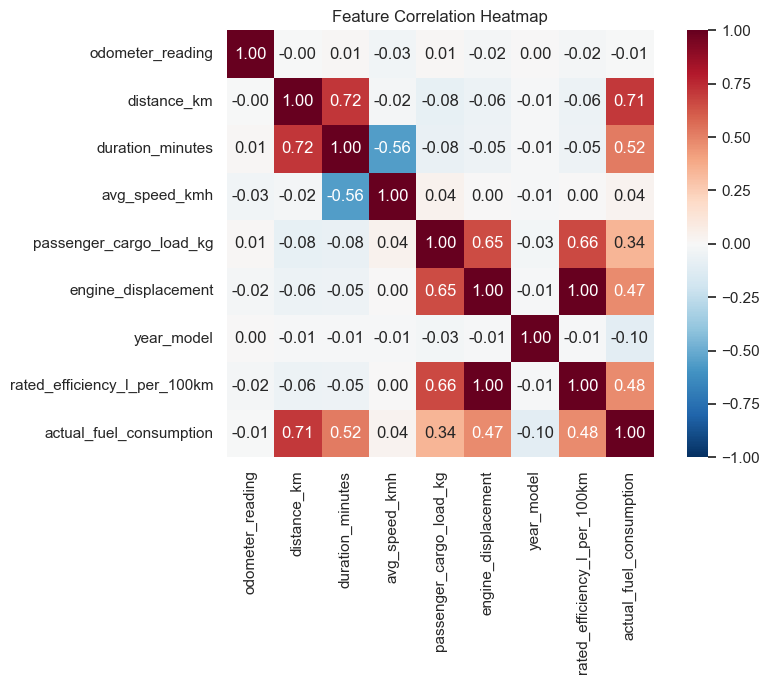

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[NUMERIC_FEATURES + [TARGET_COLUMN]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Feature Correlation Heatmap"); plt.tight_layout(); plt.show()

## 5. Train-test split (80/20)

In [7]:
X, y = df[FEATURE_COLUMNS], df[TARGET_COLUMN]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Training set: {len(X_train)} records | Testing set: {len(X_test)} records")

Training set: 1156 records | Testing set: 289 records


## 6. Variable selection — correlation with fuel use (|r| < 0.10 removed) and VIF > 5 (identical to `model/diagnostics.py`)

In [8]:
import math
import warnings

import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera

VIF_THRESHOLD = 5.0
CORR_THRESHOLD = 0.10  # |r| below this = no measurable (only negligible) link to fuel use
# Never removed for a high VIF: the study's primary predictor (Chapter II).
PRIMARY_PREDICTORS = ("distance_km",)
ALPHA = 0.05
VIF_CAP = 1000.0  # perfect collinearity gives an infinite VIF; stored as ">1000"


def compute_vif(frame):
    """VIF of every column in `frame` (numeric predictors), with an intercept."""
    X = sm.add_constant(frame.astype(float), has_constant="add")
    out = {}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # divide-by-zero for perfectly collinear columns
        for i, col in enumerate(X.columns):
            if col == "const":
                continue
            value = variance_inflation_factor(X.values, i)
            out[col] = VIF_CAP if (not math.isfinite(value) or value > VIF_CAP) else round(float(value), 2)
    return out


def select_features_by_vif(frame, numeric_features, threshold=VIF_THRESHOLD):
    """Drop the numeric predictor with the highest VIF until every remaining
    VIF is at or below `threshold`. Returns (kept, initial_vif, final_vif, removed)."""
    kept = [c for c in numeric_features if frame[c].astype(float).std() > 0]
    removed = [{"feature": c, "vif": None, "reason": "constant value"} for c in numeric_features if c not in kept]
    initial = compute_vif(frame[kept])
    while len(kept) > 1:
        vif = compute_vif(frame[kept])
        worst = max(vif, key=vif.get)
        if vif[worst] <= threshold:
            break
        removed.append({"feature": worst, "vif": vif[worst], "reason": f"VIF above {threshold:g}"})
        kept.remove(worst)
    return kept, initial, compute_vif(frame[kept]), removed


def select_features(frame, target, numeric_features, corr_threshold=CORR_THRESHOLD, vif_threshold=VIF_THRESHOLD):
    """Two-step variable selection (Chapter I, Process: "keeps the predictors
    with a measurable link to fuel use and removes the ones carrying the same
    information"):

    1. correlation filter - drop numeric predictors whose |Pearson r| with
       fuel consumption is below `corr_threshold` (no measurable link);
    2. VIF - drop the remaining predictor with the highest VIF until every
       VIF is at or below `vif_threshold` (same information).

    Returns (kept, initial_vif, final_vif, removed, correlations)."""
    y = target.astype(float)
    candidates = [c for c in numeric_features if frame[c].astype(float).std() > 0]
    removed = [{"feature": c, "vif": None, "r": None, "reason": "constant value"}
               for c in numeric_features if c not in candidates]
    correlations = {c: round(float(frame[c].astype(float).corr(y)), 3) for c in candidates}
    initial_vif = compute_vif(frame[candidates]) if len(candidates) > 1 else {c: 1.0 for c in candidates}
    kept = []
    for c in candidates:
        if abs(correlations[c]) < corr_threshold:
            removed.append({"feature": c, "vif": initial_vif.get(c), "r": correlations[c],
                            "reason": f"weak link to fuel use (|r| < {corr_threshold:g})"})
        else:
            kept.append(c)
    while len(kept) > 1:
        vif = compute_vif(frame[kept])
        # Distance traveled is the study's primary predictor (Chapter II, [5]), so
        # when it shares information with another predictor (e.g. trip duration),
        # the other one is removed. Among the rest, the highest VIF goes first; on
        # a tie, the one with the weaker link to fuel use, then the later one.
        candidates_to_drop = [c for c in kept if c not in PRIMARY_PREDICTORS] or kept
        worst = max(candidates_to_drop, key=lambda c: (vif[c], -abs(correlations[c]), kept.index(c)))
        if max(vif.values()) <= vif_threshold or vif[worst] <= vif_threshold:
            break
        removed.append({"feature": worst, "vif": vif[worst], "r": correlations[worst],
                        "reason": f"VIF above {vif_threshold:g}"})
        kept.remove(worst)
    final_vif = compute_vif(frame[kept]) if len(kept) > 1 else {c: 1.0 for c in kept}
    return kept, initial_vif, final_vif, removed, correlations


def _p(value):
    return None if value is None or not math.isfinite(float(value)) else round(float(value), 4)


def regression_diagnostics(X_train, y_train, numeric_features, categorical_features, final_vif):
    """Fit an OLS model on the training split (same predictors as the
    scikit-learn pipeline, categoricals dummy-coded) and test the LINE
    conditions on its residuals."""
    numeric = X_train[numeric_features].astype(float)
    dummies = pd.get_dummies(X_train[categorical_features].astype(str), drop_first=True, dtype=float)
    design = sm.add_constant(pd.concat([numeric, dummies], axis=1), has_constant="add")
    y = np.asarray(y_train, dtype=float)
    result = sm.OLS(y, design).fit()
    resid = np.asarray(result.resid)

    reset = linear_reset(result, power=2, use_f=True)
    dw = float(durbin_watson(resid))
    jb_stat, jb_p, skew, kurtosis = jarque_bera(resid)
    bp_lm, bp_p, _, _ = het_breuschpagan(resid, design)
    max_vif = max(final_vif.values()) if final_vif else 0.0

    tests = [
        {"key": "linearity", "assumption": "Linearity", "test": "Ramsey RESET test",
         "statistic": round(float(reset.fvalue), 3), "p_value": _p(reset.pvalue),
         "passed": bool(reset.pvalue > ALPHA), "rule": f"p > {ALPHA}",
         "meaning": "Fuel use is a straight-line function of the predictors."},
        {"key": "independence", "assumption": "Independence of errors", "test": "Durbin-Watson statistic",
         "statistic": round(dw, 3), "p_value": None,
         "passed": bool(1.5 <= dw <= 2.5), "rule": "1.5 to 2.5 (2 = no autocorrelation)",
         "meaning": "One trip's error does not depend on another's."},
        {"key": "normality", "assumption": "Normality of errors", "test": "Jarque-Bera test",
         "statistic": round(float(jb_stat), 3), "p_value": _p(jb_p),
         "passed": bool(jb_p > ALPHA), "rule": f"p > {ALPHA}",
         "meaning": f"Residuals follow a normal distribution (skew {float(skew):.2f}, kurtosis {float(kurtosis):.2f})."},
        {"key": "equal_variance", "assumption": "Equal variance of errors", "test": "Breusch-Pagan test",
         "statistic": round(float(bp_lm), 3), "p_value": _p(bp_p),
         "passed": bool(bp_p > ALPHA), "rule": f"p > {ALPHA}",
         "meaning": "The spread of errors is the same for small and large trips."},
        {"key": "multicollinearity", "assumption": "No multicollinearity", "test": "Variance Inflation Factor",
         "statistic": round(float(max_vif), 2), "p_value": None,
         "passed": bool(max_vif <= VIF_THRESHOLD), "rule": f"every VIF ≤ {VIF_THRESHOLD:g}",
         "meaning": "Predictors do not carry the same information."},
    ]
    coefficients = []
    for name in ["const"] + list(numeric_features):
        coefficients.append({
            "feature": "Intercept" if name == "const" else name,
            "coef": float(f"{float(result.params[name]):.4g}"),
            "std_err": float(f"{float(result.bse[name]):.4g}"),
            "p_value": _p(result.pvalues[name]),
            "significant": bool(result.pvalues[name] < ALPHA),
        })
    return {
        "tests": tests,
        "coefficients": coefficients,
        "ols_r2": round(float(result.rsquared), 4),
        "ols_adj_r2": round(float(result.rsquared_adj), 4),
        "alpha": ALPHA,
    }

In [9]:
numeric_candidates = [c for c in NUMERIC_FEATURES if c not in supp_info["dropped_features"]]
categorical = [c for c in CATEGORICAL_FEATURES if c not in supp_info["dropped_features"]]
selected_numeric, vif_initial, vif_final, removed, correlations = select_features(X_train, y_train, numeric_candidates)
vif_table = pd.DataFrame({"r with fuel": correlations, "Initial VIF": vif_initial, "Final VIF": pd.Series(vif_final)})
vif_table["Result"] = ["Removed" if f in {r["feature"] for r in removed} else "Kept" for f in vif_table.index]
print("Removed:", [(r["feature"], r["reason"]) for r in removed])
vif_table

Removed: [('odometer_reading', 'weak link to fuel use (|r| < 0.1)'), ('avg_speed_kmh', 'weak link to fuel use (|r| < 0.1)'), ('rated_efficiency_l_per_100km', 'VIF above 5')]


,r with fuel,Initial VIF,Final VIF,Result
avg_speed_kmh,0.048,2.65,NaN,Removed
distance_km,0.704,3.76,2.07,Kept
duration_minutes,0.504,5.49,2.07,Kept
engine_displacement,0.489,245.51,1.81,Kept
odometer_reading,0.002,1.00,NaN,Removed
passenger_cargo_load_kg,0.357,1.84,1.82,Kept
rated_efficiency_l_per_100km,0.488,247.77,NaN,Removed
year_model,-0.111,1.00,1.00,Kept


## 7. Train the Linear Regression model

In [10]:
pipeline = Pipeline(steps=[
    ("preprocessor", build_preprocessing_pipeline(selected_numeric, categorical)),
    ("regressor", LinearRegression()),
])
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

## 8. Evaluate — R², MAE, RMSE and k-fold cross-validation

In [11]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
cv_scores = cross_val_score(pipeline, X, y, cv=KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE), scoring="r2")
print(f"R²   : {r2:.4f}")
print(f"MAE  : {mae:.4f} L")
print(f"RMSE : {rmse:.4f} L")
print(f"{CV_FOLDS}-fold CV R² scores: {np.round(cv_scores, 4)}  mean = {cv_scores.mean():.4f} (± {cv_scores.std():.4f})")

R²   : 0.8364
MAE  : 3.2822 L
RMSE : 4.2699 L
5-fold CV R² scores: [0.8364 0.871  0.8224 0.8271 0.8221]  mean = 0.8358 (± 0.0184)


## 9. Regression assumption checks (LINE conditions)

In [12]:
diagnostics = regression_diagnostics(X_train, y_train, selected_numeric, categorical, vif_final)
pd.DataFrame(diagnostics["tests"])[["assumption", "test", "statistic", "p_value", "rule", "passed"]]

,assumption,test,statistic,p_value,rule,passed
0,Linearity,Ramsey RESET test,770.634,0.0,p > 0.05,False
1,Independence of errors,Durbin-Watson statistic,2.145,NaN,1.5 to 2.5 (2 = no autocorrelation),True
2,Normality of errors,Jarque-Bera test,159.922,0.0,p > 0.05,False
3,Equal variance of errors,Breusch-Pagan test,262.387,0.0,p > 0.05,False
4,No multicollinearity,Variance Inflation Factor,2.070,NaN,every VIF ≤ 5,True


In [13]:
pd.DataFrame(diagnostics["coefficients"])

,feature,coef,std_err,p_value,significant
0,Intercept,401.100000,54.990000,0.0000,True
1,distance_km,0.163800,0.003998,0.0000,True
2,duration_minutes,0.004238,0.002160,0.0499,True
3,passenger_cargo_load_kg,0.002253,0.000315,0.0000,True
4,engine_displacement,2.986000,1.881000,0.1128,False
5,year_model,-0.204100,0.027030,0.0000,True


## 10. Evaluation plots

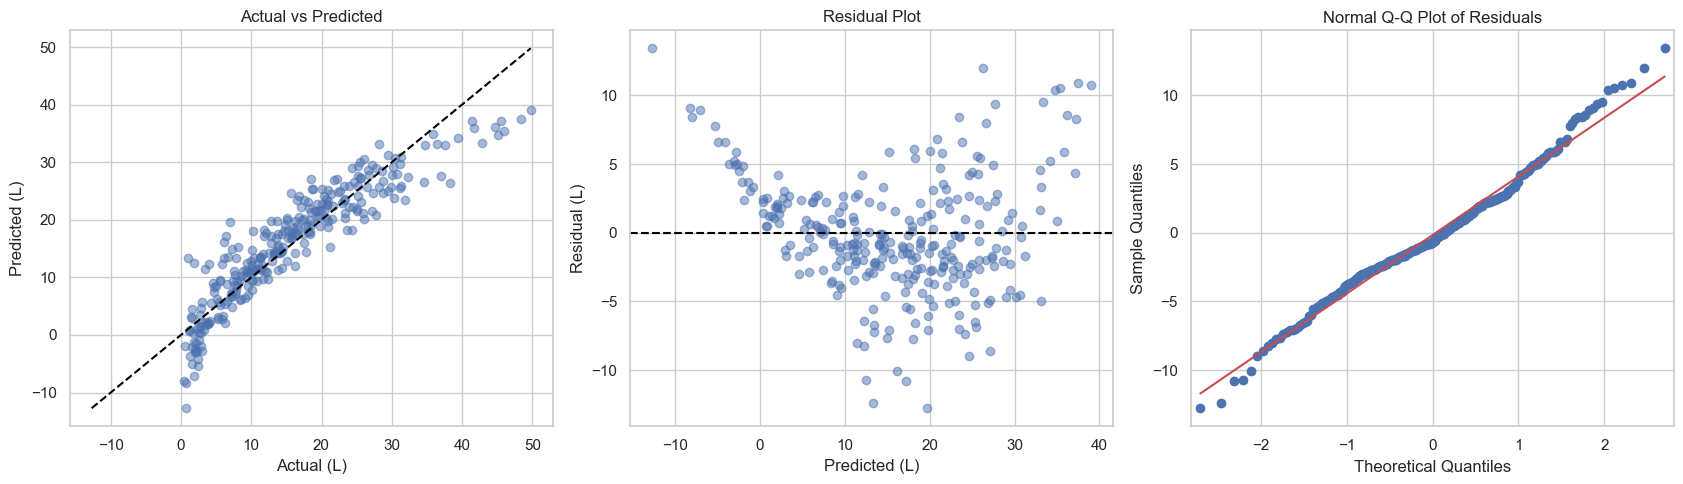

In [14]:
residuals = y_test.values - y_pred
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].scatter(y_test, y_pred, alpha=0.5)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, "--", color="black"); axes[0].set(title="Actual vs Predicted", xlabel="Actual (L)", ylabel="Predicted (L)")
axes[1].scatter(y_pred, residuals, alpha=0.5); axes[1].axhline(0, ls="--", color="black")
axes[1].set(title="Residual Plot", xlabel="Predicted (L)", ylabel="Residual (L)")
sm.qqplot(residuals, line="s", ax=axes[2]); axes[2].set_title("Normal Q-Q Plot of Residuals")
plt.tight_layout(); plt.show()

## 11. Save the trained model (Joblib) for the web application

In [15]:
joblib.dump(pipeline, "linear_regression_pipeline.joblib")
metrics = {"r2_score": round(r2, 4), "mae": round(mae, 4), "rmse": round(rmse, 4), "cv_folds": CV_FOLDS,
           "cv_mean_r2": round(float(cv_scores.mean()), 4), "cv_std_r2": round(float(cv_scores.std()), 4),
           "train_size": len(X_train), "test_size": len(X_test), "total_records": len(df),
           "selected_numeric_features": selected_numeric, "removed_features": removed,
           "vif_initial": vif_initial, "vif_final": vif_final, "diagnostics": diagnostics}
with open("metrics_colab.json", "w") as f:
    json.dump(metrics, f, indent=2)
try:
    from google.colab import files
    files.download("linear_regression_pipeline.joblib")
except ImportError:
    print("Saved linear_regression_pipeline.joblib and metrics_colab.json")

Saved linear_regression_pipeline.joblib and metrics_colab.json


> The web application retrains this same model automatically whenever trip records change, so copying the
> `.joblib` file into the `model/` folder is optional. The notebook documents and reproduces the process.